In [ ]:

QUICK = False
N_JOBS = 2
USE_GOOGLE_DRIVE = False
DRIVE_FOLDER = "/content/drive/MyDrive/TRIAD-BRCA-plus"
FORCE_RERUN = False

In [ ]:
import os, sys, glob, time, pickle, shutil, warnings, subprocess, zipfile
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[_v] = "1"
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib, joblib
from joblib import Parallel, delayed
try:
    from threadpoolctl import threadpool_limits
    threadpool_limits(1)
except Exception:
    pass

if tuple(int(x) for x in sklearn.__version__.split(".")[:2]) < (1, 4):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "scikit-learn>=1.4"])
    raise SystemExit("scikit-learn was upgraded - please use Runtime > Restart session, then Run all again.")

try:
    from IPython.display import display, Markdown, Image as IPImage
except ImportError:
    display = print
    Markdown = str
    IPImage = None

IN_COLAB = "google.colab" in sys.modules
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR, OUT_DIR = os.path.join(DRIVE_FOLDER, "data"), os.path.join(DRIVE_FOLDER, "results")
else:
    base = "/content" if IN_COLAB else os.getcwd()
    DATA_DIR, OUT_DIR = os.path.join(base, "data"), os.path.join(base, "results")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | joblib {joblib.__version__}")
print("DATA_DIR =", DATA_DIR, "| OUT_DIR =", OUT_DIR, "| QUICK =", QUICK, "| N_JOBS =", N_JOBS)

Python 3.13.15 | numpy 2.1.3 | pandas 2.2.3 | scipy 1.16.3 | scikit-learn 1.6.1 | matplotlib 3.10.0 | joblib 1.6.0
DATA_DIR = /content/data | OUT_DIR = /content/results | QUICK = False | N_JOBS = 2


In [ ]:
"""
TRIAD-BRCA+ : global configuration.

Every constant that influences a reported number lives here, so that the whole
study can be audited from a single file.
"""
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
           "NUMEXPR_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "1")

SEED = 42

LABEL_COL = "pam50_+_claudin-low_subtype"
CLASSES = ["Basal", "Her2", "LumA", "LumB"]
CLASS_NAMES = ["Basal-like", "HER2-enriched", "Luminal A", "Luminal B"]
K = len(CLASSES)
EXCLUDED_SUBTYPES = ["Normal", "claudin-low", "NC"]

OUTER_SPLITS = 3 if QUICK else 5
OUTER_REPEATS = 1 if QUICK else 2
INNER_SPLITS = 5
N_BOOT = 1000
LC_FRACTIONS = [0.25, 0.50, 0.75]

LEAKAGE_CATEGORIES = {
    "Direct / alternative subtype labels": ["pam50_+_claudin-low_subtype", "3-gene_classifier_subtype"],
    "Molecular clustering labels": ["integrative_cluster"],
    "Receptor-status variables": ["er_status_measured_by_ihc", "er_status", "pr_status",
                                  "her2_status_measured_by_snp6", "her2_status"],
    "Histological-subtype encodings": ["tumor_other_histologic_subtype", "cancer_type_detailed", "oncotree_code"],
    "Treatment-assignment variables": ["chemotherapy", "hormone_therapy", "radio_therapy", "type_of_breast_surgery"],
    "Survival / outcome variables": ["overall_survival_months", "overall_survival", "death_from_cancer"],
    "Identifiers / constants": ["patient_id", "cancer_type"],
}

CLIN_NUM = ["age_at_diagnosis", "neoplasm_histologic_grade", "tumor_size", "tumor_stage",
            "lymph_nodes_examined_positive", "nottingham_prognostic_index", "mutation_count"]
CLIN_CAT = ["cellularity", "inferred_menopausal_state", "primary_tumor_laterality", "cohort"]

V1_CLIN_NUM = ["age_at_diagnosis", "lymph_nodes_examined_positive", "mutation_count",
               "nottingham_prognostic_index", "tumor_size", "tumor_stage",
               "neoplasm_histologic_grade", "chemotherapy", "hormone_therapy", "radio_therapy"]
V1_CLIN_CAT = ["type_of_breast_surgery", "cancer_type", "cancer_type_detailed", "cellularity",
               "inferred_menopausal_state", "primary_tumor_laterality", "oncotree_code", "cohort"]

MUT_MIN_CARRIERS = 5

MODULES = {
    "Proliferation": ["aurka", "ccnb1", "cdk1", "ccne1", "e2f1", "e2f2", "e2f8", "chek1", "rad51", "cdc25a"],
    "Luminal/ER": ["gata3", "bcl2", "mapt", "ar", "tbx3", "nrip1", "ncoa3"],
    "HER2-amplicon": ["erbb2"],
    "Basal/myoepithelial": ["egfr", "sox9", "cdkn2a", "lamb3"],
    "Immune": ["stat1", "cxcl8", "ptpn22", "klrg1", "fas"],
    "Stromal/ECM": ["mmp2", "mmp14", "pdgfrb", "col12a1", "col6a3", "fn1", "lama2", "dab2"],
}
MODULE_CONTRASTS = {
    "Luminal-Basal axis": ("Luminal/ER", "Basal/myoepithelial"),
    "Proliferation-Luminal axis": ("Proliferation", "Luminal/ER"),
}

V1_K_BEST = 200
V1_GBDT = dict(max_iter=300, learning_rate=0.08, max_depth=6, l2_regularization=1.0)
V1_AE = dict(latent=48, epochs=100, batch=32, lr=0.01, momentum=0.9, C=1.0)
V1_SVM_C = 1.0
V1_BETA, V1_TAU = 10.0, 0.30
V1_STAB_M, V1_STAB_SIGMA2 = 15, 0.01

PLUS_SVM_C_GRID = [1.0, 2.0, 4.0, 8.0]
PLUS_LR_C_GRID = [0.002, 0.005, 0.01, 0.02]
PLUS_GBDT = dict(max_iter=300, learning_rate=0.06, max_depth=3, l2_regularization=1.0, max_features=0.2)
PLUS_LAMBDA_GRID = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5]

SUBTYPE_COLORS = {"Basal": "#2a78d6", "Her2": "#eb6834", "LumA": "#1baf7a", "LumB": "#eda100"}
C_PROPOSED = "#2a78d6"
C_V1 = "#eb6834"
C_EXPERT = "#1baf7a"
C_OTHER = "#b5b3ac"
C_INK, C_INK2, C_MUTED, C_GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SEQ_CMAP = ["#ffffff", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
DIV_NEG, DIV_MID, DIV_POS = "#e34948", "#f0efec", "#2a78d6"

In [ ]:
import glob
import os

import numpy as np
import pandas as pd


FILE_PATTERNS = {
    "metabric_rna": "METABRIC_RNA_Mutation",
    "metabric_clin": "Breast_Cancer_METABRIC",
    "metabric_cbio": "brca_metabric_clinical_data",
    "tcga_omics": "brca_data_w_subtypes_tcga",
    "tcga_clin": "clinical_tcga",
}

MUT_ALIASES = {"kmt2c": "MLL3", "kmt2d": "MLL2", "kmt2a": "MLL", "tenm4": "ODZ4", "tenm1": "ODZ1"}


def find_file(data_dir, key):
    pat = FILE_PATTERNS[key]
    hits = sorted(glob.glob(os.path.join(data_dir, f"*{pat}*.csv")))
    if key == "metabric_clin":
        hits = [h for h in hits if "brca_metabric_clinical" not in os.path.basename(h)]
    if not hits:
        raise FileNotFoundError(f"No file matching *{pat}*.csv in {data_dir}")
    return hits[0]


def _pid_to_int(s):
    return pd.to_numeric(pd.Series(s).astype(str).str.replace("MB-", "", regex=False), errors="coerce")


def load_metabric(data_dir):
    """Return a dict with the full METABRIC table, column blocks and linked endpoints."""
    df = pd.read_csv(find_file(data_dir, "metabric_rna"), low_memory=False)
    cols = list(df.columns)
    mut_cols = [c for c in cols if c.endswith("_mut")]
    rna_start, mut_start = cols.index("brca1"), cols.index(mut_cols[0])
    rna_cols = cols[rna_start:mut_start]
    clin_cols = cols[:rna_start]

    mut = df[mut_cols].fillna("0").astype(str).apply(lambda s: s.str.strip())
    mut_bin = (mut != "0").astype(np.int8)
    mut_bin.columns = [c[:-4] for c in mut_cols]

    ext = pd.read_csv(find_file(data_dir, "metabric_clin"))
    ext["pid"] = _pid_to_int(ext["Patient ID"]).values
    ext = ext.dropna(subset=["pid"]).drop_duplicates("pid").set_index("pid")
    pid = df["patient_id"].astype(int)
    df["rfs_months"] = pid.map(ext["Relapse Free Status (Months)"]).values
    df["rfs_event"] = pid.map(ext["Relapse Free Status"].eq("Recurred").astype(float)).values
    df["vital_status_ext"] = pid.map(ext["Patient's Vital Status"]).values
    df["pam50_ext"] = pid.map(ext["Pam50 + Claudin-low subtype"]).values

    cbio = pd.read_csv(find_file(data_dir, "metabric_cbio"))
    cbio["pid"] = _pid_to_int(cbio["Patient ID"]).values
    cbio = cbio.dropna(subset=["pid"]).drop_duplicates("pid").set_index("pid")
    df["tmb"] = pid.map(cbio["TMB (nonsynonymous)"]).values
    df["pam50_cbio"] = pid.map(cbio["Pam50 + Claudin-low subtype"]).values

    df["os_months"] = df["overall_survival_months"]
    df["os_event"] = df["death_from_cancer"].isin(["Died of Disease", "Died of Other Causes"]).astype(float)
    df.loc[df["death_from_cancer"].isna(), "os_event"] = np.nan
    df["dss_event"] = df["death_from_cancer"].eq("Died of Disease").astype(float)
    df.loc[df["death_from_cancer"].isna(), "dss_event"] = np.nan

    linkage = dict(
        n_rna=len(df), n_ext=len(ext), n_cbio=len(cbio),
        n_linked_ext=int(pid.isin(ext.index).sum()), n_linked_cbio=int(pid.isin(cbio.index).sum()),
    )
    both = df["pam50_ext"].notna()
    linkage["pam50_concordance_ext"] = float((df.loc[both, LABEL_COL] == df.loc[both, "pam50_ext"]).mean())
    both = df["pam50_cbio"].notna()
    linkage["pam50_concordance_cbio"] = float((df.loc[both, LABEL_COL] == df.loc[both, "pam50_cbio"]).mean())
    linkage["n_rfs_available"] = int(df["rfs_months"].notna().sum())

    return dict(df=df, rna_cols=rna_cols, mut_cols=list(mut_bin.columns), clin_cols=clin_cols,
                mut_bin=mut_bin, linkage=linkage, ext=ext, cbio=cbio)


def core4_cohort(M):
    """Restrict to the four reproducible PAM50 subtypes (disclosed scope restriction)."""
    df = M["df"]
    keep = df[LABEL_COL].isin(CLASSES).values
    d = df.loc[keep].reset_index(drop=True)
    y = d[LABEL_COL].map({c: i for i, c in enumerate(CLASSES)}).values.astype(int)
    R = d[M["rna_cols"]].astype(float).values
    Mu = M["mut_bin"].loc[keep].reset_index(drop=True).values.astype(float)
    return dict(df=d, y=y, R=R, Mu=Mu, rna_cols=M["rna_cols"], mut_cols=M["mut_cols"], keep=keep)

def ihc_surrogate(er, pr, her2):
    """0 = triple-negative (Basal-like surrogate), 1 = HER2-positive, 2 = HR+/HER2- (Luminal); -1 = unusable."""
    if her2 == "Positive":
        return 1
    if her2 == "Negative" and er == "Negative" and pr == "Negative":
        return 0
    if her2 == "Negative" and er == "Positive":
        return 2
    return -1


IHC_NAMES = ["Triple-negative (Basal-like)", "HER2-positive (HER2-like)", "HR+/HER2- (Luminal)"]


def load_tcga(data_dir):
    t = pd.read_csv(find_file(data_dir, "tcga_omics"), low_memory=False)
    t["ihc_label"] = [ihc_surrogate(a, b, c) for a, b, c in
                      zip(t["ER.Status"], t["PR.Status"], t["HER2.Final.Status"])]
    clin = pd.read_csv(find_file(data_dir, "tcga_clin"), low_memory=False, dtype=str)
    clin = clin.mask(clin == "'--").mask(clin == "--")
    return dict(omics=t, clin=clin)


def harmonised_panel(M, T):
    """Exact-symbol (plus documented aliases) overlap between METABRIC and TCGA."""
    t = T["omics"]
    trs = {c[3:].lower(): c for c in t.columns if c.startswith("rs_")}
    tmu = {c[3:].upper(): c for c in t.columns if c.startswith("mu_")}
    rna_pairs = [(g, trs[g]) for g in M["rna_cols"] if g in trs]
    mut_pairs = []
    for g in M["mut_cols"]:
        G = MUT_ALIASES.get(g, g.upper())
        if G in tmu:
            mut_pairs.append((g, tmu[G]))
    return rna_pairs, mut_pairs

In [ ]:
def _missing_files():
    return [p for k, p in FILE_PATTERNS.items() if not glob.glob(os.path.join(DATA_DIR, f"*{p}*.csv"))]

missing = _missing_files()
if missing and IN_COLAB and not USE_GOOGLE_DRIVE:
    print("Please select the five CSV files (missing patterns: %s)" % ", ".join(missing))
    from google.colab import files
    uploaded = files.upload()
    for name in uploaded:
        shutil.move(os.path.join(os.getcwd(), name), os.path.join(DATA_DIR, name))
    missing = _missing_files()
if missing:
    raise FileNotFoundError(f"CSV files matching {missing} were not found in {DATA_DIR}")

M = load_metabric(DATA_DIR)
T = load_tcga(DATA_DIR)
D = core4_cohort(M)
print("Files used:")
for k in FILE_PATTERNS:
    print("  ", k, "->", os.path.basename(find_file(DATA_DIR, k)))
print(f"\nMETABRIC: {len(M['df'])} patients | RNA genes: {len(M['rna_cols'])} | mutation genes: {len(M['mut_cols'])}")
print(f"Core-4 cohort: n = {len(D['y'])} | class counts {dict(zip(CLASS_NAMES, np.bincount(D['y']).tolist()))}")
print("Linkage:", M["linkage"])
print(f"TCGA multi-omics: {T['omics'].shape} | usable IHC-surrogate labels: {(T['omics'].ihc_label >= 0).sum()}")

Please select the five CSV files (missing patterns: METABRIC_RNA_Mutation, Breast_Cancer_METABRIC, brca_metabric_clinical_data, brca_data_w_subtypes_tcga, clinical_tcga)


Saving brca_data_w_subtypes_tcga.csv to brca_data_w_subtypes_tcga.csv
Saving brca_metabric_clinical_data.csv to brca_metabric_clinical_data.csv
Saving Breast_Cancer_METABRIC.csv to Breast_Cancer_METABRIC.csv
Saving clinical_-_clinical_tcga.csv to clinical_-_clinical_tcga.csv
Saving METABRIC_RNA_Mutation.csv to METABRIC_RNA_Mutation.csv
Files used:
   metabric_rna -> METABRIC_RNA_Mutation.csv
   metabric_clin -> Breast_Cancer_METABRIC.csv
   metabric_cbio -> brca_metabric_clinical_data.csv
   tcga_omics -> brca_data_w_subtypes_tcga.csv
   tcga_clin -> clinical_-_clinical_tcga.csv

METABRIC: 1904 patients | RNA genes: 489 | mutation genes: 173
Core-4 cohort: n = 1559 | class counts {'Basal-like': 199, 'HER2-enriched': 220, 'Luminal A': 679, 'Luminal B': 461}
Linkage: {'n_rna': 1904, 'n_ext': 1985, 'n_cbio': 1540, 'n_linked_ext': 1904, 'n_linked_cbio': 1500, 'pam50_concordance_ext': 1.0, 'pam50_concordance_cbio': 1.0, 'n_rfs_available': 1904}
TCGA multi-omics: (705, 1942) | usable IHC-sur

In [ ]:
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler



class FeatureBuilder:
    def __init__(self, rna_cols, mut_cols, clin_num, clin_cat, use_rna=True, use_mut=True,
                 use_clin=True, use_modules=True, mut_min_carriers=5):
        self.rna_cols, self.mut_cols = list(rna_cols), list(mut_cols)
        self.clin_num, self.clin_cat = list(clin_num), list(clin_cat)
        self.use_rna, self.use_mut, self.use_clin, self.use_modules = use_rna, use_mut, use_clin, use_modules
        self.mut_min_carriers = mut_min_carriers
        self.module_idx = {m: [self.rna_cols.index(g) for g in gs if g in self.rna_cols]
                           for m, gs in MODULES.items()}

        def _cat_frame(self, C):
        return C[self.clin_cat].astype(object).where(C[self.clin_cat].notna(), "Missing").astype(str)

    def _raw_modules(self, Rs):
        base = {m: Rs[:, idx].mean(1) for m, idx in self.module_idx.items() if idx}
        for name, (a, b) in MODULE_CONTRASTS.items():
            base[name] = base[a] - base[b]
        return pd.DataFrame(base)


    def fit(self, R, Mu, C):
        self.rna_sc_ = StandardScaler().fit(R)
        self.mut_keep_ = (Mu.sum(0) >= self.mut_min_carriers) if self.mut_min_carriers else np.ones(Mu.shape[1], bool)
        if self.use_clin:
            self.imp_ = SimpleImputer(strategy="median").fit(C[self.clin_num].astype(float))
            self.csc_ = StandardScaler().fit(self.imp_.transform(C[self.clin_num].astype(float)))
            self.ohe_ = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10,
                                      sparse_output=False).fit(self._cat_frame(C))
        if self.use_modules:
            Q = self._raw_modules(self.rna_sc_.transform(R))
            self.module_names_ = list(Q.columns)
            self.msc_ = StandardScaler().fit(Q.values)

        names, groups = [], []
        if self.use_rna:
            names += [f"RNA:{g}" for g in self.rna_cols]; groups += ["RNA expression"] * len(self.rna_cols)
        if self.use_mut:
            kept = [g for g, k in zip(self.mut_cols, self.mut_keep_) if k]
            names += [f"MUT:{g}" for g in kept]; groups += ["Somatic mutation"] * len(kept)
        if self.use_clin:
            cat_names = list(self.ohe_.get_feature_names_out(self.clin_cat))
            names += [f"CLIN:{c}" for c in self.clin_num] + [f"CLIN:{c}" for c in cat_names]
            groups += ["Clinical"] * (len(self.clin_num) + len(cat_names))
        if self.use_modules:
            names += [f"MOD:{m}" for m in self.module_names_]; groups += ["Knowledge-guided modules"] * len(self.module_names_)
        self.names_, self.groups_ = names, np.array(groups)
        return self

    def transform(self, R, Mu, C):
        blocks = []
        Rs = self.rna_sc_.transform(R)
        if self.use_rna:
            blocks.append(Rs)
        if self.use_mut:
            blocks.append(Mu[:, self.mut_keep_])
        if self.use_clin:
            blocks.append(self.csc_.transform(self.imp_.transform(C[self.clin_num].astype(float))))
            blocks.append(self.ohe_.transform(self._cat_frame(C)))
        if self.use_modules:
            blocks.append(self.msc_.transform(self._raw_modules(Rs).values))
        return np.hstack(blocks).astype(float)

    def fit_transform(self, R, Mu, C):
        return self.fit(R, Mu, C).transform(R, Mu, C)

In [ ]:

import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, log_loss, matthews_corrcoef
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC


EPS = 1e-9

def normalise(P):
    P = np.clip(np.asarray(P, float), EPS, None)
    return P / P.sum(1, keepdims=True)


def cross_fit(estimator, X, y, folds):
    """Out-of-fold class probabilities (every row predicted by a model that never saw it)."""
    oof = np.zeros((len(y), len(np.unique(y))))
    for a, b in folds:
        oof[b] = clone(estimator).fit(X[a], y[a]).predict_proba(X[b])
    return oof


def js_divergence(p, q):
    m = 0.5 * (p + q)
    kl = lambda a, b: np.sum(a * (np.log(a + EPS) - np.log(b + EPS)), 1)
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def mean_pairwise_js(prob_list):
    ds = [js_divergence(prob_list[i], prob_list[j])
          for i in range(len(prob_list)) for j in range(i + 1, len(prob_list))]
    return np.mean(ds, 0)


def balanced_risk_decision(P, prior, lam):
    """Tempered prior-shift rule (Eq. 12): argmax_k p_k / pi_k^lambda.
    lambda = 1 is the Bayes-optimal rule for balanced accuracy under calibrated posteriors."""
    return np.argmax(normalise(P) / np.power(prior, lam), 1)


def tune_lambda(P_oof, y, prior, grid=PLUS_LAMBDA_GRID):
    """Select lambda on inner out-of-fold posteriors: maximise (BA + MCC)/2; ties -> smaller lambda."""
    best, best_s, scores = 0.0, -np.inf, {}
    for lam in grid:
        pred = balanced_risk_decision(P_oof, prior, lam)
        s = 0.5 * (balanced_accuracy_score(y, pred) + matthews_corrcoef(y, pred))
        scores[lam] = s
        if s > best_s + 1e-12:
            best, best_s = lam, s
    return best, scores

class AEClassifier(BaseEstimator, ClassifierMixin):
    """Single-hidden-layer tanh autoencoder (NumPy, mini-batch SGD with momentum)
    followed by multinomial logistic regression on the latent code (v1 expert 2)."""

    def __init__(self, latent=48, epochs=100, batch=32, lr=0.01, momentum=0.9, C=1.0, random_state=42):
        self.latent, self.epochs, self.batch, self.lr = latent, epochs, batch, lr
        self.momentum, self.C, self.random_state = momentum, C, random_state

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        n, d = X.shape
        h = self.latent
        W1 = rng.normal(0, np.sqrt(1.0 / d), (d, h)); b1 = np.zeros(h)
        W2 = rng.normal(0, np.sqrt(1.0 / h), (h, d)); b2 = np.zeros(d)
        params = [W1, b1, W2, b2]
        vel = [np.zeros_like(p) for p in params]
        for _ in range(self.epochs):
            perm = rng.permutation(n)
            for i in range(0, n, self.batch):
                xb = X[perm[i:i + self.batch]]
                H = np.tanh(xb @ W1 + b1)
                E = H @ W2 + b2 - xb
                gR = E / len(xb)
                gW2, gb2 = H.T @ gR, gR.sum(0)
                gH = (gR @ W2.T) * (1 - H ** 2)
                gW1, gb1 = xb.T @ gH, gH.sum(0)
                grads = [gW1, gb1, gW2, gb2]
                nrm = np.sqrt(sum((g ** 2).sum() for g in grads))
                if nrm > 5.0:
                    grads = [g * 5.0 / nrm for g in grads]
                for j, (p, g) in enumerate(zip(params, grads)):
                    vel[j] = self.momentum * vel[j] - self.lr * g
                    p += vel[j]
        self.W1_, self.b1_ = W1, b1
        self.clf_ = LogisticRegression(C=self.C, max_iter=5000).fit(self.encode(X), y)
        self.classes_ = self.clf_.classes_
        return self

    def encode(self, X):
        return np.tanh(X @ self.W1_ + self.b1_)

    def predict_proba(self, X):
        return self.clf_.predict_proba(self.encode(X))

    def predict(self, X):
        return self.predict_proba(X).argmax(1)


class SGCClassifier(BaseEstimator, ClassifierMixin):

    def __init__(self, k=10, hops=2, C=1.0):
        self.k, self.hops, self.C = k, hops, C

    @staticmethod
    def _unit(X):
        return X / (np.linalg.norm(X, axis=1, keepdims=True) + EPS)

    def fit(self, X, y):
        n = len(X)
        U = self._unit(X)
        S = U @ U.T
        np.fill_diagonal(S, -np.inf)
        nn = np.argsort(-S, 1)[:, :self.k]
        A = np.zeros((n, n))
        A[np.repeat(np.arange(n), self.k), nn.ravel()] = 1.0
        A = np.maximum(A, A.T) + np.eye(n)
        A = A / A.sum(1, keepdims=True)
        self.Xtr_, self.Utr_ = X, U
        H = [X]
        for _ in range(self.hops):
            H.append(A @ H[-1])
        self.Htr_ = H
        self.clf_ = LogisticRegression(C=self.C, max_iter=5000).fit(H[-1], y)
        self.classes_ = self.clf_.classes_
        return self

    def _propagate(self, Xq):
        nn = np.argsort(-(self._unit(Xq) @ self.Utr_.T), 1)[:, :self.k]
        h = Xq
        for t in range(self.hops):
            h = (h + self.Htr_[t][nn].sum(1)) / (self.k + 1)
        return h

    def predict_proba(self, X):
        return self.clf_.predict_proba(self._propagate(X))

    def predict(self, X):
        return self.predict_proba(X).argmax(1)

def kbest(clf, k=V1_K_BEST):
    return Pipeline([("sel", SelectKBest(f_classif, k=k)), ("clf", clf)])


def make_v1_expert(name, seed, select=True):
    if name == "GBDT-v1":
        m = HistGradientBoostingClassifier(random_state=seed, **V1_GBDT)
    elif name == "AE-v1":
        m = AEClassifier(random_state=seed, **V1_AE)
    elif name == "SVM-v1":
        m = SVC(C=V1_SVM_C, gamma="scale", probability=True, random_state=seed)
    else:
        raise ValueError(name)
    return kbest(m) if select else m


V1_EXPERTS = ["GBDT-v1", "AE-v1", "SVM-v1"]


def make_baselines(seed):
    return {
        "Logistic Regression": kbest(LogisticRegression(C=1.0, max_iter=5000)),
        "Random Forest": kbest(RandomForestClassifier(n_estimators=500, max_features="sqrt",
                                                      random_state=seed, n_jobs=1)),
        "k-NN (cosine)": kbest(KNeighborsClassifier(n_neighbors=15, metric="cosine", weights="distance")),
        "Shrinkage LDA": kbest(LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")),
        "MLP": kbest(MLPClassifier(hidden_layer_sizes=(128,), alpha=1.0, max_iter=500, random_state=seed)),
        "SGC-GNN": kbest(SGCClassifier(k=10, hops=2, C=1.0)),
    }


def make_plus_expert(name, hp, seed):
    if name == "SVM+":
        return SVC(C=hp, gamma="scale", probability=True, random_state=seed, cache_size=500)
    if name == "LR+":
        return LogisticRegression(C=hp, max_iter=5000)
    if name == "GBDT+":
        return HistGradientBoostingClassifier(random_state=seed, **PLUS_GBDT)
    raise ValueError(name)


PLUS_EXPERTS = ["SVM+", "LR+", "GBDT+"]
PLUS_GRIDS = {"SVM+": PLUS_SVM_C_GRID, "LR+": PLUS_LR_C_GRID, "GBDT+": [None]}

class TriadV1:
    PAIRS = [(2, 3), (1, 3), (0, 1)]    # LumA-LumB, HER2-LumB, Basal-HER2

    def __init__(self, seed=42, inner_splits=5, select=True):
        self.seed, self.inner_splits, self.select = seed, inner_splits, select

    def fit(self, X, y, with_routing=True):
        nc = len(np.unique(y))
        self.prior_ = np.bincount(y, minlength=nc) / len(y)
        if with_routing:
            folds = list(StratifiedKFold(self.inner_splits, shuffle=True, random_state=self.seed + 1).split(X, y))
            self.oof_ = {n: cross_fit(make_v1_expert(n, self.seed, self.select), X, y, folds) for n in V1_EXPERTS}

            self.C_ = np.array([[np.mean(self.oof_[n].argmax(1)[y == k] == k) for k in range(nc)]
                                for n in V1_EXPERTS])
            D = mean_pairwise_js([self.oof_[n] for n in V1_EXPERTS])
            self.dmin_, self.dmax_ = float(D.min()), float(D.max())

            self.spec_ = {}
            for a, b in self.PAIRS:
                msk = np.isin(y, [a, b])
                self.spec_[(a, b)] = kbest(SVC(C=1.0, gamma="scale", probability=True, random_state=self.seed)
                                           ).fit(X[msk], (y[msk] == a).astype(int))
        self.experts_ = {n: make_v1_expert(n, self.seed, self.select).fit(X, y) for n in V1_EXPERTS}
        return self

    def expert_proba(self, X):
        return {n: normalise(m.predict_proba(X)) for n, m in self.experts_.items()}

    def variants(self, X, E=None):

        E = self.expert_proba(X) if E is None else E
        Ps = [E[n] for n in V1_EXPERTS]
        pbar = np.mean(Ps, 0)
        srt = np.sort(pbar, 1)
        margin = srt[:, -1] - srt[:, -2]
        D = mean_pairwise_js(Ps)
        Dn = np.clip((D - self.dmin_) / (self.dmax_ - self.dmin_ + EPS), 0, 1)
        BE = 0.5 * (1 - margin) + 0.5 * Dn
        wcomp = self.C_[:, pbar.argmax(1)].T
        wcomp = wcomp / wcomp.sum(1, keepdims=True)
        alpha = 1.0 / (1.0 + np.exp(-V1_BETA * (BE - V1_TAU)))
        W = (1 - alpha)[:, None] * (1.0 / len(Ps)) + alpha[:, None] * wcomp
        pfuse = normalise(sum(W[:, [i]] * Ps[i] for i in range(len(Ps))))
        pfinal = pfuse.copy()
        top2 = np.argsort(-pfuse, 1)[:, :2]
        rng = np.random.default_rng(self.seed + 7)
        for (a, b), spec in self.spec_.items():
            act = np.where(((top2[:, 0] == a) & (top2[:, 1] == b)) | ((top2[:, 0] == b) & (top2[:, 1] == a)))[0]
            if len(act) == 0:
                continue
            Xa = X[act]
            q = spec.predict_proba(Xa)[:, 1]
            base_lab = (q >= 0.5).astype(int)
            noise = rng.normal(0, np.sqrt(V1_STAB_SIGMA2), (V1_STAB_M,) + Xa.shape)
            pert = spec.predict((Xa[None] + noise).reshape(-1, Xa.shape[1])).reshape(V1_STAB_M, len(act))
            S = (pert == base_lab[None]).mean(0)
            mass = pfuse[act, a] + pfuse[act, b]
            pspec = pfuse[act].copy()
            pspec[:, a], pspec[:, b] = mass * q, mass * (1 - q)
            pfinal[act] = S[:, None] * pspec + (1 - S)[:, None] * pfuse[act]
        return dict(V1=normalise(pbar), V8=normalise(pfinal), BE=BE, W=W)

class TriadPlus:

    def __init__(self, seed=42, inner_splits=5, grids=None, lambdas=PLUS_LAMBDA_GRID, fixed_hp=None, decision="bayes"):
        self.seed, self.inner_splits = seed, inner_splits
        self.grids = PLUS_GRIDS if grids is None else grids
        self.lambdas, self.fixed_hp, self.decision = lambdas, fixed_hp, decision

    def fit(self, X, y):
        nc = len(np.unique(y))
        self.n_classes_ = nc
        self.prior_ = np.bincount(y, minlength=nc) / len(y)
        self.folds_ = list(StratifiedKFold(self.inner_splits, shuffle=True, random_state=self.seed + 3).split(X, y))
        self.hp_, self.oof_, self.hp_scores_ = {}, {}, {}
        for name in PLUS_EXPERTS:
            grid = [self.fixed_hp[name]] if self.fixed_hp else self.grids[name]
            best = None
            for hp in grid:
                oof = cross_fit(make_plus_expert(name, hp, self.seed), X, y, self.folds_)
                ll = log_loss(y, normalise(oof), labels=list(range(nc)))
                self.hp_scores_[(name, hp)] = ll
                if best is None or ll < best[0] - 1e-12:
                    best = (ll, hp, oof)
            self.hp_[name], self.oof_[name] = best[1], normalise(best[2])
        self.oof_fused_ = self.fuse(self.oof_)

        self.lambda_tuned_, self.lambda_scores_ = tune_lambda(self.oof_fused_, y, self.prior_, self.lambdas)
        self.lambda_ = 1.0 if self.decision == "bayes" else self.lambda_tuned_
        self.experts_ = {n: make_plus_expert(n, self.hp_[n], self.seed).fit(X, y) for n in PLUS_EXPERTS}
        return self

    def expert_proba(self, X, experts=None):
        experts = PLUS_EXPERTS if experts is None else experts
        return {n: normalise(self.experts_[n].predict_proba(X)) for n in experts}

    @staticmethod
    def fuse(E, experts=None):
        experts = list(E) if experts is None else experts
        return normalise(np.mean([E[n] for n in experts], 0))

    def predict_proba(self, X):
        return self.fuse(self.expert_proba(X))

    def decide(self, P, lam=None):
        return balanced_risk_decision(P, self.prior_, self.lambda_ if lam is None else lam)

    def predict(self, X):
        return self.decide(self.predict_proba(X))

In [ ]:

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, log_loss,
                             matthews_corrcoef, precision_recall_fscore_support, roc_auc_score)


METRICS = ["BA", "F1", "MCC", "AUC", "ACC"]
METRIC_NAMES = {"BA": "Balanced Accuracy", "F1": "Macro-F1", "MCC": "MCC", "AUC": "Macro-AUC", "ACC": "Accuracy"}


def compute_metrics(y, P, pred=None):
    P = normalise(P)
    pred = P.argmax(1) if pred is None else pred
    return dict(BA=balanced_accuracy_score(y, pred), F1=f1_score(y, pred, average="macro"),
                MCC=matthews_corrcoef(y, pred),
                AUC=roc_auc_score(y, P, multi_class="ovr", average="macro", labels=list(range(P.shape[1]))),
                ACC=accuracy_score(y, pred))


def fmt_ms(x, d=3):
    return f"{np.mean(x):.{d}f} ± {np.std(x, ddof=1):.{d}f}"

def corrected_ttest(d, n_train, n_test):
    """Nadeau & Bengio (2003) corrected resampled t-test for repeated k-fold CV."""
    d = np.asarray(d, float)
    J = len(d)
    v = d.var(ddof=1)
    if v <= 1e-15:
        return (0.0, 1.0) if abs(d.mean()) < 1e-12 else (np.inf, 0.0)
    t = d.mean() / np.sqrt((1.0 / J + n_test / n_train) * v)
    return float(t), float(2 * stats.t.sf(abs(t), J - 1))


def holm(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    m = len(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj


def cohen_dz(d):
    d = np.asarray(d, float)
    s = d.std(ddof=1)
    return 0.0 if s < 1e-15 else float(d.mean() / s)


def wilcoxon_p(d):
    d = np.asarray(d, float)
    if np.all(np.abs(d) < 1e-12):
        return 1.0
    try:
        return float(stats.wilcoxon(d, zero_method="zsplit").pvalue)
    except ValueError:
        return 1.0


def friedman_nemenyi(score_table):

    ranks = score_table.rank(axis=1, ascending=False, method="average")
    mean_ranks = ranks.mean().sort_values()
    chi2, p = stats.friedmanchisquare(*[score_table[c].values for c in score_table.columns])
    k, N = score_table.shape[1], score_table.shape[0]
    q = stats.studentized_range.ppf(0.95, k, np.inf) / np.sqrt(2)
    cd = q * np.sqrt(k * (k + 1) / (6.0 * N))
    return mean_ranks, float(chi2), float(p), float(cd)


def bootstrap_ci(fn, y, *arrays, n_boot=1000, seed=0, alpha=0.05):
    rng = np.random.default_rng(seed)
    n = len(y)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y[idx])) < len(np.unique(y)):
            continue
        vals.append(fn(y[idx], *[a[idx] for a in arrays]))
    vals = np.array(vals)
    return np.quantile(vals, alpha / 2, axis=0), np.quantile(vals, 1 - alpha / 2, axis=0)

def per_class_table(y, P, pred, class_names, n_boot=1000, seed=0):
    P = normalise(P)
    prec, rec, f1, sup = precision_recall_fscore_support(y, pred, labels=list(range(K)), zero_division=0)
    spec = np.array([np.mean(pred[y != k] != k) for k in range(K)])
    auc = np.array([roc_auc_score((y == k).astype(int), P[:, k]) for k in range(K)])

    def f1_fn(yy, pp):
        return precision_recall_fscore_support(yy, pp, labels=list(range(K)), zero_division=0)[2]
    lo, hi = bootstrap_ci(f1_fn, y, pred, n_boot=n_boot, seed=seed)
    rows = []
    for k in range(K):
        rows.append(dict(Subtype=class_names[k], Precision=prec[k], Recall=rec[k], Specificity=spec[k],
                         F1=f1[k], F1_lo=lo[k], F1_hi=hi[k], AUC=auc[k], Support=int(sup[k])))
    return pd.DataFrame(rows)

def ece_top_label(y, P, n_bins=15):
    P = normalise(P)
    conf, pred = P.max(1), P.argmax(1)
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(np.mean(pred[m] == y[m]) - conf[m].mean())
    return float(ece)

def reliability_curve(y, P, n_bins=10):
    P = normalise(P)
    conf, pred = P.max(1), P.argmax(1)
    bins = np.linspace(0, 1, n_bins + 1)
    xs, ys, ns = [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 5:
            xs.append(conf[m].mean()); ys.append(np.mean(pred[m] == y[m])); ns.append(int(m.sum()))
    return np.array(xs), np.array(ys), np.array(ns)

def calibration_metrics(y, P):
    P = normalise(P)
    Y = np.eye(K)[y]
    return dict(Brier=float(np.mean(np.sum((P - Y) ** 2, 1))), LogLoss=float(log_loss(y, P, labels=list(range(K)))),
                ECE=ece_top_label(y, P))

def pairwise_diversity(y, preds):
    names = list(preds)
    rows = []
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a, b = preds[names[i]] == y, preds[names[j]] == y
            n11, n00 = np.sum(a & b), np.sum(~a & ~b)
            n10, n01 = np.sum(a & ~b), np.sum(~a & b)
            q = (n11 * n00 - n01 * n10) / max(n11 * n00 + n01 * n10, 1)
            rho = np.corrcoef((~a).astype(float), (~b).astype(float))[0, 1]
            rows.append(dict(A=names[i], B=names[j], Disagreement=(n10 + n01) / len(y),
                             DoubleFault=n00 / len(y), YuleQ=q, ErrorCorr=rho))
    return pd.DataFrame(rows)

def kaplan_meier(t, e):
    t, e = np.asarray(t, float), np.asarray(e, float)
    order = np.argsort(t)
    t, e = t[order], e[order]
    times = np.unique(t[e == 1])
    S, surv, n_at_risk = 1.0, [], []
    for u in times:
        n = np.sum(t >= u)
        d = np.sum((t == u) & (e == 1))
        S *= 1 - d / n
        surv.append(S); n_at_risk.append(n)
    return np.r_[0, times], np.r_[1.0, surv]


def logrank_multigroup(t, e, g):
    t, e, g = np.asarray(t, float), np.asarray(e, float), np.asarray(g)
    groups = np.unique(g)
    times = np.unique(t[e == 1])
    O = np.zeros(len(groups)); E = np.zeros(len(groups)); V = np.zeros((len(groups), len(groups)))
    for u in times:
        at = t >= u
        n = at.sum(); d = np.sum((t == u) & (e == 1))
        if n < 2:
            continue
        ng = np.array([np.sum(at & (g == k)) for k in groups])
        dg = np.array([np.sum((t == u) & (e == 1) & (g == k)) for k in groups])
        O += dg; E += d * ng / n
        f = d * (n - d) / (n - 1) if n > 1 else 0
        V += f * (np.diag(ng / n) - np.outer(ng / n, ng / n))
    diff = (O - E)[:-1]
    chi2 = float(diff @ np.linalg.pinv(V[:-1, :-1]) @ diff)
    return chi2, float(stats.chi2.sf(chi2, len(groups) - 1))


def cox_ph(t, e, X, max_iter=50):
    t, e, X = np.asarray(t, float), np.asarray(e, float), np.asarray(X, float)
    order = np.argsort(-t)
    t, e, X = t[order], e[order], X[order]
    beta = np.zeros(X.shape[1])
    for _ in range(max_iter):
        eta = X @ beta
        w = np.exp(eta - eta.max())
        cw = np.cumsum(w)
        cwx = np.cumsum(w[:, None] * X, 0)
        cwxx = np.cumsum(w[:, None, None] * X[:, :, None] * X[:, None, :], 0)
        # handle ties (Breslow): risk set for time t_i is all j with t_j >= t_i
        last = {}
        for i in range(len(t)):
            last[t[i]] = i
        idx = np.array([last[ti] for ti in t])
        g = np.zeros_like(beta); H = np.zeros((len(beta), len(beta)))
        for i in np.where(e == 1)[0]:
            j = idx[i]
            mu = cwx[j] / cw[j]
            g += X[i] - mu
            H -= cwxx[j] / cw[j] - np.outer(mu, mu)
        step = np.linalg.solve(H - 1e-9 * np.eye(len(beta)), g)
        beta = beta - step
        if np.max(np.abs(step)) < 1e-8:
            break
    se = np.sqrt(np.diag(np.linalg.inv(-H)))
    return beta, se


def harrell_c(t, e, risk):
    t, e, risk = np.asarray(t, float), np.asarray(e, float), np.asarray(risk, float)
    conc = ties = total = 0.0
    for i in np.where(e == 1)[0]:
        m = t > t[i]
        total += m.sum()
        conc += np.sum(risk[i] > risk[m]); ties += np.sum(risk[i] == risk[m])
    return float((conc + 0.5 * ties) / max(total, 1))

def permutation_importance(proba_fn, decide_fn, X, y, groups, n_repeats=3, seed=0):
    rng = np.random.default_rng(seed)
    P0 = proba_fn(X)
    ll0 = log_loss(y, P0, labels=list(range(K)))
    ba0 = balanced_accuracy_score(y, decide_fn(P0))
    out = {}
    for name, cols in groups.items():
        dll, dba = [], []
        for _ in range(n_repeats):
            Xp = X.copy()
            perm = rng.permutation(len(X))
            Xp[:, cols] = X[perm][:, cols]
            P = proba_fn(Xp)
            dll.append(log_loss(y, P, labels=list(range(K))) - ll0)
            dba.append(ba0 - balanced_accuracy_score(y, decide_fn(P)))
        out[name] = (float(np.mean(dll)), float(np.mean(dba)))
    return out

In [ ]:

import time

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler


# Display names used in every table / figure
N_LR, N_RF, N_KNN, N_LDA, N_MLP, N_SGC = ("Logistic Regression", "Random Forest", "k-NN (cosine)",
                                          "Shrinkage LDA", "MLP", "SGC-GNN")
N_GBDT1, N_AE1, N_SVM1 = "GBDT (XGBoost-style, v1)", "Autoencoder + LR (v1)", "SVM-RBF (v1)"
N_V1, N_V8 = "TRIAD-BRCA v1: V1 equal-weight", "TRIAD-BRCA v1: V8 adaptive"
N_SVMP, N_LRP, N_GBDTP = "SVM-RBF+ (tuned)", "Ridge-LR+ (tuned)", "GBDT+ (shallow)"
N_PROP = "TRIAD-BRCA+ (proposed)"
V1_DISPLAY = {"GBDT-v1": N_GBDT1, "AE-v1": N_AE1, "SVM-v1": N_SVM1}
PLUS_DISPLAY = {"SVM+": N_SVMP, "LR+": N_LRP, "GBDT+": N_GBDTP}

ABLATION = [
    ("A0", "TRIAD-BRCA v1 equal-weight triad (V1)"),
    ("A1", "+ strict leakage governance (treatment & histology removed)"),
    ("A2", "+ full-panel multi-view input (no univariate top-200 bottleneck)"),
    ("A3", "+ re-designed tuned heterogeneous triad (equal-weight, argmax)"),
    ("A4", "+ knowledge-guided meta-gene modules"),
    ("A5", "+ balanced-risk decision (= TRIAD-BRCA+)"),
]
FUSIONS = ["Best single expert", "Linear pool (equal)", "Log-linear pool", "Stacked meta-learner",
           "BE-adaptive routing (v1 Eqs. 5-7)"]
DECISIONS = ["Argmax", "Balanced-risk (λ = 1)", "Tempered (λ inner-tuned)"]


def outer_folds(y, splits=OUTER_SPLITS, repeats=OUTER_REPEATS, seed=SEED):
    rskf = RepeatedStratifiedKFold(n_splits=splits, n_repeats=repeats, random_state=seed)
    return [(i // splits, i % splits, tr, te) for i, (tr, te) in enumerate(rskf.split(np.zeros(len(y)), y))]


def builders(D):
    rc, mc = D["rna_cols"], D["mut_cols"]
    return dict(
        v1=lambda: FeatureBuilder(rc, mc, V1_CLIN_NUM, V1_CLIN_CAT, use_modules=False, mut_min_carriers=0),
        strict=lambda: FeatureBuilder(rc, mc, CLIN_NUM, CLIN_CAT, use_modules=False, mut_min_carriers=0),
        panel=lambda: FeatureBuilder(rc, mc, CLIN_NUM, CLIN_CAT, use_modules=False, mut_min_carriers=MUT_MIN_CARRIERS),
        plus=lambda: FeatureBuilder(rc, mc, CLIN_NUM, CLIN_CAT, use_modules=True, mut_min_carriers=MUT_MIN_CARRIERS),
    )


def _equal_triad(X_tr, y_tr, X_te, seed, select):
    Ps = {n: normalise(make_v1_expert(n, seed, select).fit(X_tr, y_tr).predict_proba(X_te)) for n in V1_EXPERTS}
    return normalise(np.mean(list(Ps.values()), 0)), Ps

def fusion_grid(tp, E_te, y_tr):
    prior = tp.prior_
    O = tp.oof_
    names = PLUS_EXPERTS
    out = {}

    from sklearn.metrics import balanced_accuracy_score
    best = max(names, key=lambda n: balanced_accuracy_score(y_tr, O[n].argmax(1)))
    fus_te = {"Best single expert": E_te[best]}
    fus_oof = {"Best single expert": O[best]}

    fus_te["Linear pool (equal)"] = tp.fuse(E_te); fus_oof["Linear pool (equal)"] = tp.oof_fused_

    geo = lambda E: normalise(np.exp(np.mean([np.log(E[n] + 1e-9) for n in names], 0)))
    fus_te["Log-linear pool"] = geo(E_te); fus_oof["Log-linear pool"] = geo(O)

    Z_tr = np.hstack([np.log(O[n] + 1e-9) for n in names])
    Z_te = np.hstack([np.log(E_te[n] + 1e-9) for n in names])
    meta = LogisticRegression(C=1.0, max_iter=5000)
    fus_oof["Stacked meta-learner"] = normalise(cross_fit(meta, Z_tr, y_tr, tp.folds_))
    fus_te["Stacked meta-learner"] = normalise(meta.fit(Z_tr, y_tr).predict_proba(Z_te))

    Cm = np.array([[np.mean(O[n].argmax(1)[y_tr == k] == k) for k in range(K)] for n in names])
    Dtr = mean_pairwise_js([O[n] for n in names])
    dmin, dmax = Dtr.min(), Dtr.max()

    def route(E):
        Ps = [E[n] for n in names]
        pbar = np.mean(Ps, 0)
        s = np.sort(pbar, 1)
        be = 0.5 * (1 - (s[:, -1] - s[:, -2])) + 0.5 * np.clip((mean_pairwise_js(Ps) - dmin) / (dmax - dmin + 1e-9), 0, 1)
        wc = Cm[:, pbar.argmax(1)].T; wc = wc / wc.sum(1, keepdims=True)
        a = 1 / (1 + np.exp(-10 * (be - 0.30)))
        W = (1 - a)[:, None] / len(Ps) + a[:, None] * wc
        return normalise(sum(W[:, [i]] * Ps[i] for i in range(len(Ps)))), W, be
    fus_te["BE-adaptive routing (v1 Eqs. 5-7)"], W_te, be_te = route(E_te)
    fus_oof["BE-adaptive routing (v1 Eqs. 5-7)"] = route(O)[0]

    for f in FUSIONS:
        lam, _ = tune_lambda(fus_oof[f], y_tr, prior)
        out[(f, DECISIONS[0])] = (fus_te[f], fus_te[f].argmax(1))
        out[(f, DECISIONS[1])] = (fus_te[f], balanced_risk_decision(fus_te[f], prior, 1.0))
        out[(f, DECISIONS[2])] = (fus_te[f], balanced_risk_decision(fus_te[f], prior, lam))
    return out, best, (W_te, be_te)

def robustness(D, te, fb1, tv1, fbp, tp, seed):
    R0, M0, C0 = D["R"][te], D["Mu"][te], D["df"].iloc[te]
    y = D["y"][te]
    rng = np.random.default_rng(seed + 99)
    res = []

    def score(R, M):
        X1 = fb1.transform(R, M, C0)
        E1 = tv1.expert_proba(X1)
        Xp = fbp.transform(R, M, C0)
        Pp = tp.predict_proba(Xp)
        from sklearn.metrics import balanced_accuracy_score as ba
        return {N_GBDT1: ba(y, E1["GBDT-v1"].argmax(1)),
                N_V1: ba(y, np.mean(list(E1.values()), 0).argmax(1)),
                N_PROP: ba(y, tp.decide(Pp))}
    for lvl in [0.0, 0.1, 0.2, 0.3, 0.5]:
        M = M0.copy(); M[rng.random(M.shape) < lvl] = 0.0
        for k, v in score(R0, M).items():
            res.append(dict(Perturbation="Mutation calls lost", Level=lvl, Model=k, BA=v))
    for lvl in [0.0, 0.25, 0.5, 0.75, 1.0]:
        R = R0 + rng.normal(0, lvl, R0.shape)
        for k, v in score(R, M0).items():
            res.append(dict(Perturbation="Gaussian RNA noise (SD)", Level=lvl, Model=k, BA=v))
    for lvl in [0.0, 0.1, 0.2, 0.3, 0.5]:
        R = R0.copy(); R[rng.random(R.shape) < lvl] = 0.0     # missing value -> cohort mean
        for k, v in score(R, M0).items():
            res.append(dict(Perturbation="RNA values missing (mean-imputed)", Level=lvl, Model=k, BA=v))
    return res

def run_outer_fold(job, D, extras=True):
    rep, fold, tr, te = job
    t0 = time.time()
    seed = SEED + 100 * rep + fold
    y = D["y"]; ytr, yte = y[tr], y[te]
    R, Mu, C = D["R"], D["Mu"], D["df"]
    B = builders(D)
    out = dict(rep=rep, fold=fold, te=te, tr_n=len(tr), P={}, pred={}, info={}, timing={})

    def add(name, P, pred=None):
        P = normalise(P)
        out["P"][name] = P
        out["pred"][name] = P.argmax(1) if pred is None else np.asarray(pred)

    def feats(kind):
        fb = B[kind]().fit(R[tr], Mu[tr], C.iloc[tr])
        return fb, fb.transform(R[tr], Mu[tr], C.iloc[tr]), fb.transform(R[te], Mu[te], C.iloc[te])

    fb1, X1tr, X1te = feats("v1")
    t = time.time()
    for name, mdl in make_baselines(seed).items():
        add(name, mdl.fit(X1tr, ytr).predict_proba(X1te))
    out["timing"]["baselines"] = time.time() - t
    t = time.time()
    tv1 = TriadV1(seed=seed, inner_splits=INNER_SPLITS).fit(X1tr, ytr)
    E1 = tv1.expert_proba(X1te)
    for n in V1_EXPERTS:
        add(V1_DISPLAY[n], E1[n])
    v = tv1.variants(X1te, E1)
    add(N_V1, v["V1"]); add(N_V8, v["V8"])
    lam_v1, _ = tune_lambda(normalise(np.mean([tv1.oof_[n] for n in V1_EXPERTS], 0)), ytr, tv1.prior_)
    add("V1 + balanced-risk decision", v["V1"], balanced_risk_decision(v["V1"], tv1.prior_, 1.0))
    out["info"]["v1_routing"] = dict(BE=v["BE"], W=v["W"], competence=tv1.C_)
    out["info"]["lambda_v1"] = lam_v1
    out["timing"]["triad_v1"] = time.time() - t

    t = time.time()
    _, XStr, XSte = feats("strict")
    add("A1", _equal_triad(XStr, ytr, XSte, seed, select=True)[0])
    _, XPtr, XPte = feats("panel")
    add("A2", _equal_triad(XPtr, ytr, XPte, seed, select=False)[0])
    fbp, X2tr, X2te = feats("plus")
    out["timing"]["ablation_v1_experts"] = time.time() - t

    t = time.time()
    tpn = TriadPlus(seed=seed, inner_splits=INNER_SPLITS).fit(XPtr, ytr)
    Pn = tpn.predict_proba(XPte)
    add("A3", Pn)
    add("LOCO|− knowledge-guided modules", Pn, tpn.decide(Pn))
    out["timing"]["triad_plus_no_modules"] = time.time() - t

    t = time.time()
    tp = TriadPlus(seed=seed, inner_splits=INNER_SPLITS).fit(X2tr, ytr)
    E2 = tp.expert_proba(X2te)
    for n in PLUS_EXPERTS:
        add(PLUS_DISPLAY[n], E2[n])
    P2 = tp.fuse(E2)
    add("A4", P2)
    add(N_PROP, P2, tp.decide(P2))
    out["info"]["plus"] = dict(hp=tp.hp_, lam=tp.lambda_tuned_, lambda_scores=tp.lambda_scores_, hp_nomod=tpn.hp_,
                               hp_scores={f"{k[0]}|{k[1]}": v for k, v in tp.hp_scores_.items()})
    out["timing"]["triad_plus"] = time.time() - t

    grid, best, (W_te, be_te) = fusion_grid(tp, E2, ytr)
    for (f, d), (P, pred) in grid.items():
        add(f"FD|{f}|{d}", P, pred)
    out["info"]["best_single"] = best
    out["info"]["plus_routing"] = dict(W=W_te, BE=be_te)

    for drop in PLUS_EXPERTS:
        keep = [n for n in PLUS_EXPERTS if n != drop]
        Pk = tp.fuse(E2, keep)
        add(f"LOCO|− {PLUS_DISPLAY[drop]}", Pk, balanced_risk_decision(Pk, tp.prior_, 1.0))

    if extras and rep == 0:
        t = time.time()
        out["robust"] = robustness(D, te, fb1, tv1, fbp, tp, seed)
        groups = {g: np.where(fbp.groups_ == g)[0] for g in np.unique(fbp.groups_)}
        out["perm_group"] = permutation_importance(tp.predict_proba, tp.decide, X2te, yte, groups,
                                                   n_repeats=5, seed=seed)
        feat_groups = {n: [i] for i, n in enumerate(fbp.names_)}
        out["perm_feature"] = permutation_importance(tp.predict_proba, tp.decide, X2te, yte, feat_groups,
                                                     n_repeats=2, seed=seed)
        out["timing"]["extras"] = time.time() - t
        out["info"]["feature_names"] = fbp.names_
        out["info"]["feature_groups"] = list(fbp.groups_)
    out["timing"]["total"] = time.time() - t0
    return out

AUDIT_ROWS = [
    ("L0", "Honest pipeline (strict pre-treatment features)", "strict", []),
    ("L1", "+ treatment-assignment variables", "strict", ["chemotherapy", "hormone_therapy", "radio_therapy"]),
    ("L2", "+ histological-subtype encodings", "strict", ["cancer_type_detailed", "oncotree_code",
                                                        "tumor_other_histologic_subtype"]),
    ("L3", "+ receptor status (ER / PR / HER2)", "strict", ["er_status", "pr_status", "her2_status",
                                                          "er_status_measured_by_ihc", "her2_status_measured_by_snp6"]),
    ("L4", "+ derived molecular labels (IntClust, 3-gene)", "strict", ["integrative_cluster", "3-gene_classifier_subtype"]),
]


def run_leakage_audit_fold(job, D):
    """Re-insert each excluded channel into the honest representation and measure the change,
    using three probes with different inductive biases (ridge-LR, RBF-SVM, shallow GBDT)."""
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.svm import SVC
    rep, fold, tr, te = job
    seed = SEED + 100 * rep + fold
    y = D["y"]; ytr, yte = y[tr], y[te]
    R, Mu, C = D["R"], D["Mu"], D["df"]
    rows = []
    probes = {"Ridge-LR": lambda: LogisticRegression(C=0.01, max_iter=5000),
              "RBF-SVM": lambda: SVC(C=4.0, gamma="scale", probability=True, random_state=seed),
              "GBDT": lambda: HistGradientBoostingClassifier(random_state=seed, **PLUS_GBDT)}
    therapy = ("chemotherapy", "hormone_therapy", "radio_therapy")
    for code, label, base, extra in AUDIT_ROWS:
        num = list(CLIN_NUM) + [c for c in extra if c in therapy]
        cat = list(CLIN_CAT) + [c for c in extra if c not in therapy]
        fb = FeatureBuilder(D["rna_cols"], D["mut_cols"], num, cat, use_modules=False,
                            mut_min_carriers=MUT_MIN_CARRIERS).fit(R[tr], Mu[tr], C.iloc[tr])
        Xa, Xb = fb.transform(R[tr], Mu[tr], C.iloc[tr]), fb.transform(R[te], Mu[te], C.iloc[te])
        for pname, mk in probes.items():
            P = mk().fit(Xa, ytr).predict_proba(Xb)
            m = compute_metrics(yte, P); m.update(Code=code, Setting=label, Probe=pname, rep=rep, fold=fold)
            rows.append(m)

    fb = FeatureBuilder(D["rna_cols"], D["mut_cols"], V1_CLIN_NUM, V1_CLIN_CAT, use_modules=False, mut_min_carriers=0)
    Xall = fb.fit_transform(R, Mu, C)
    from sklearn.feature_selection import SelectKBest, f_classif
    from sklearn.svm import SVC
    sel = SelectKBest(f_classif, k=200).fit(Xall, y)
    Xl = sel.transform(Xall)
    P = SVC(C=1.0, gamma="scale", probability=True, random_state=seed).fit(Xl[tr], ytr).predict_proba(Xl[te])
    m = compute_metrics(yte, P); m.update(Code="L5", Setting="Preprocessing leakage: scaler + top-200 selector fit on full cohort (v1 SVM)", Probe="v1 SVM", rep=rep, fold=fold)
    rows.append(m)
    fbh = FeatureBuilder(D["rna_cols"], D["mut_cols"], V1_CLIN_NUM, V1_CLIN_CAT, use_modules=False,
                         mut_min_carriers=0).fit(R[tr], Mu[tr], C.iloc[tr])
    mdl = kbest(SVC(C=1.0, gamma="scale", probability=True, random_state=seed))
    P = mdl.fit(fbh.transform(R[tr], Mu[tr], C.iloc[tr]), ytr).predict_proba(fbh.transform(R[te], Mu[te], C.iloc[te]))
    m = compute_metrics(yte, P); m.update(Code="L5h", Setting="Same model, preprocessing fit inside the training fold (honest)", Probe="v1 SVM", rep=rep, fold=fold)
    rows.append(m)
    return rows


def run_learning_curve_job(job, D):
    rep, fold, tr, te, frac = job
    seed = SEED + 100 * rep + fold
    y = D["y"]
    rng_tr, _ = train_test_split(tr, train_size=frac, stratify=y[tr], random_state=seed) if frac < 1 else (tr, None)
    R, Mu, C = D["R"], D["Mu"], D["df"]
    B = builders(D)
    rows = []
    fb1 = B["v1"]().fit(R[rng_tr], Mu[rng_tr], C.iloc[rng_tr])
    X1a, X1b = fb1.transform(R[rng_tr], Mu[rng_tr], C.iloc[rng_tr]), fb1.transform(R[te], Mu[te], C.iloc[te])
    tv1 = TriadV1(seed=seed).fit(X1a, y[rng_tr], with_routing=False)
    E1 = tv1.expert_proba(X1b)
    rows.append(dict(Model=N_GBDT1, **compute_metrics(y[te], E1["GBDT-v1"])))
    rows.append(dict(Model=N_V1, **compute_metrics(y[te], np.mean(list(E1.values()), 0))))
    fbp = B["plus"]().fit(R[rng_tr], Mu[rng_tr], C.iloc[rng_tr])
    X2a, X2b = fbp.transform(R[rng_tr], Mu[rng_tr], C.iloc[rng_tr]), fbp.transform(R[te], Mu[te], C.iloc[te])
    tp = TriadPlus(seed=seed).fit(X2a, y[rng_tr])
    P = tp.predict_proba(X2b)
    rows.append(dict(Model=N_PROP, **compute_metrics(y[te], P, tp.decide(P))))
    for r in rows:
        r.update(rep=rep, fold=fold, frac=frac, n_train=len(rng_tr))
    return rows


PAM_TO_IHC = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1], [0, 0, 1]], float)   # Basal, HER2, LumA, LumB -> 3 IHC groups
EXT_PROTOCOLS = {
    "E1": ("v1 protocol: source-fitted scaling, PAM50-trained", "pam", "source"),
    "E2": ("Per-cohort harmonisation, PAM50-trained", "pam", "cohort"),
    "E3": ("Per-cohort harmonisation, IHC-label-harmonised", "ihc", "cohort"),
}


def run_external(M, T):
    from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, matthews_corrcoef

    df, t = M["df"], T["omics"]
    rna_pairs, mut_pairs = harmonised_panel(M, T)
    XM_r = df[[a for a, _ in rna_pairs]].astype(float).values
    XT_r = t[[b for _, b in rna_pairs]].astype(float).values
    XM_m = M["mut_bin"][[a for a, _ in mut_pairs]].values.astype(float)
    XT_m = t[[b for _, b in mut_pairs]].values.astype(float)
    okT = t["ihc_label"].values >= 0
    yT = t["ihc_label"].values[okT].astype(int)
    yM_ihc = np.array([ihc_surrogate(a, b, c) for a, b, c in zip(df.er_status, df.pr_status, df.her2_status)])
    okM = yM_ihc >= 0
    core_m = df[LABEL_COL].isin(CLASSES).values
    yM_pam = df.loc[core_m, LABEL_COL].map({c: i for i, c in enumerate(CLASSES)}).values.astype(int)

    results, preds = [], {}

    def record(code, model, pred3):
        name = EXT_PROTOCOLS[code][0]
        m = dict(Code=code, Protocol=name, Model=model, ACC=accuracy_score(yT, pred3),
                 BA=balanced_accuracy_score(yT, pred3), F1=f1_score(yT, pred3, average="macro"),
                 MCC=matthews_corrcoef(yT, pred3))
        lo, hi = bootstrap_ci(lambda a, b: np.array([balanced_accuracy_score(a, b), matthews_corrcoef(a, b)]),
                              yT, pred3, n_boot=1000, seed=1)
        m.update(BA_lo=lo[0], BA_hi=hi[0], MCC_lo=lo[1], MCC_hi=hi[1],
                 Predicted_distribution="/".join(str(int(x)) for x in np.bincount(pred3, minlength=3)))
        results.append(m)
        preds[(code, model)] = pred3

    for code, (_, lab, norm) in EXT_PROTOCOLS.items():
        train_rows = core_m if lab == "pam" else okM
        if norm == "source":           # v1: scaler estimated on METABRIC, applied unchanged to TCGA
            sc = StandardScaler().fit(XM_r[train_rows])
            XMr, XTr = sc.transform(XM_r), sc.transform(XT_r)
        else:                          # proposed: each cohort standardised on itself (label-free)
            XMr, XTr = StandardScaler().fit_transform(XM_r), StandardScaler().fit_transform(XT_r)
        Xtr = np.hstack([XMr, XM_m])[train_rows]
        XT = np.hstack([XTr, XT_m])[okT]
        ytr = yM_pam if lab == "pam" else yM_ihc[okM].astype(int)
        mapper = PAM_TO_IHC if lab == "pam" else np.eye(3)
        E = {n: normalise(make_v1_expert(n, SEED, select=False).fit(Xtr, ytr).predict_proba(XT)) for n in V1_EXPERTS}
        for n in V1_EXPERTS:
            record(code, V1_DISPLAY[n], (E[n] @ mapper).argmax(1))
        record(code, N_V1, (np.mean(list(E.values()), 0) @ mapper).argmax(1))
        if norm == "cohort":
            tp = TriadPlus(seed=SEED).fit(Xtr, ytr)
            P = tp.predict_proba(XT)
            shifted = normalise(P / np.power(tp.prior_, tp.lambda_))
            record(code, N_PROP, (shifted @ mapper).argmax(1))
    import pandas as pd
    info = dict(n_rna=len(rna_pairs), n_mut=len(mut_pairs), rna_genes=[a for a, _ in rna_pairs],
                mut_genes=[a for a, _ in mut_pairs], n_tcga=int(okT.sum()), tcga_dist=np.bincount(yT).tolist(),
                n_metabric_ihc=int(okM.sum()), metabric_ihc_dist=np.bincount(yM_ihc[okM]).tolist(),
                n_metabric_pam=int(core_m.sum()))
    return pd.DataFrame(results), preds, yT, info

In [ ]:
CACHE = os.path.join(OUT_DIR, "cache")
os.makedirs(CACHE, exist_ok=True)


def _quiet(fn, *a, **k):
    import warnings as _w
    _w.filterwarnings("ignore")
    return fn(*a, **k)


def run_jobs(name, fn, jobs, key):
    """Run `fn(job, D)` for every job in parallel batches of N_JOBS, caching each result to disk."""
    results, todo = {}, []
    for j in jobs:
        path = os.path.join(CACHE, f"{name}_{key(j)}.pkl")
        if os.path.exists(path) and not FORCE_RERUN:
            results[key(j)] = pickle.load(open(path, "rb"))
        else:
            todo.append(j)
    print(f"[{name}] {len(results)} job(s) loaded from cache, {len(todo)} to run")
    t_all = time.time()
    for i in range(0, len(todo), N_JOBS):
        batch = todo[i:i + N_JOBS]
        t0 = time.time()
        if N_JOBS > 1 and len(batch) > 1:
            outs = Parallel(n_jobs=len(batch))(delayed(_quiet)(fn, j, D) for j in batch)
        else:
            outs = [_quiet(fn, j, D) for j in batch]
        for j, o in zip(batch, outs):
            pickle.dump(o, open(os.path.join(CACHE, f"{name}_{key(j)}.pkl"), "wb"))
            results[key(j)] = o
        print(f"  {min(i + N_JOBS, len(todo))}/{len(todo)} done  (batch {(time.time()-t0)/60:.1f} min, "
              f"total {(time.time()-t_all)/60:.1f} min)", flush=True)
    return [results[key(j)] for j in jobs]


jobs = outer_folds(D["y"], OUTER_SPLITS, OUTER_REPEATS, SEED)
fold_key = lambda j: f"r{j[0]}f{j[1]}"
print(f"{len(jobs)} outer folds ({OUTER_SPLITS}-fold x {OUTER_REPEATS} repeat(s)); test-fold sizes:",
      [len(j[3]) for j in jobs])

10 outer folds (5-fold x 2 repeat(s)); test-fold sizes: [312, 312, 312, 312, 311, 312, 312, 312, 312, 311]


In [ ]:
t0 = time.time()
cv = run_jobs("cv", run_outer_fold, jobs, fold_key)
print(f"cross-validation stage: {(time.time()-t0)/60:.1f} min")

_rows = []
for r in cv:
    yte = D["y"][r["te"]]
    for name in [N_V1, N_V8, "A4", N_PROP]:
        m = compute_metrics(yte, r["P"][name], r["pred"][name]); m["Model"] = name; _rows.append(m)
_summary = pd.DataFrame(_rows).groupby("Model")[["BA", "F1", "MCC", "AUC", "ACC"]].mean().round(4)
_summary = _summary.rename(index={"A4": "TRIAD-BRCA+ (arg-max operating point)"})
display(_summary)

[cv] 0 job(s) loaded from cache, 10 to run
  2/10 done  (batch 19.7 min, total 19.7 min)
  4/10 done  (batch 19.9 min, total 39.6 min)
  6/10 done  (batch 15.7 min, total 55.3 min)
  8/10 done  (batch 10.4 min, total 65.7 min)
  10/10 done  (batch 10.3 min, total 76.1 min)
cross-validation stage: 76.1 min


,BA,F1,MCC,AUC,ACC
Model,,,,,
TRIAD-BRCA+ (arg-max operating point),0.8433,0.8524,0.7911,0.9723,0.8569
TRIAD-BRCA v1: V1 equal-weight,0.8315,0.8399,0.7773,0.9703,0.8473
TRIAD-BRCA v1: V8 adaptive,0.8333,0.8429,0.7767,0.9677,0.8470
TRIAD-BRCA+ (proposed),0.8491,0.8439,0.7795,0.9723,0.8464


In [ ]:
t0 = time.time()
audit = [x for rows in run_jobs("audit", run_leakage_audit_fold, jobs, fold_key) for x in rows]
print(f"leakage audit: {(time.time()-t0)/60:.1f} min")

lc_jobs = [(r, f, tr, te, frac) for (r, f, tr, te) in jobs if r == 0 for frac in LC_FRACTIONS]
t0 = time.time()
lc = run_jobs("lc", run_learning_curve_job, lc_jobs, key=lambda j: f"r{j[0]}f{j[1]}_{j[4]}")
print(f"learning curves: {(time.time()-t0)/60:.1f} min")

[audit] 0 job(s) loaded from cache, 10 to run
  2/10 done  (batch 2.3 min, total 2.3 min)
  4/10 done  (batch 2.0 min, total 4.3 min)
  6/10 done  (batch 1.9 min, total 6.2 min)
  8/10 done  (batch 1.9 min, total 8.1 min)
  10/10 done  (batch 1.9 min, total 10.1 min)
leakage audit: 10.1 min
[lc] 0 job(s) loaded from cache, 15 to run
  2/15 done  (batch 1.4 min, total 1.4 min)
  4/15 done  (batch 1.9 min, total 3.3 min)
  6/15 done  (batch 2.2 min, total 5.4 min)
  8/15 done  (batch 1.4 min, total 6.9 min)
  10/15 done  (batch 1.8 min, total 8.7 min)
  12/15 done  (batch 2.2 min, total 10.9 min)
  14/15 done  (batch 1.4 min, total 12.3 min)
  15/15 done  (batch 1.4 min, total 13.7 min)
learning curves: 13.7 min


In [ ]:
ext_path = os.path.join(CACHE, "external.pkl")
if os.path.exists(ext_path) and not FORCE_RERUN:
    ext = pickle.load(open(ext_path, "rb"))
else:
    t0 = time.time()
    ext = _quiet(run_external, M, T)
    pickle.dump(ext, open(ext_path, "wb"))
    print(f"external transfer: {(time.time()-t0)/60:.1f} min")
display(ext[0][["Code", "Protocol", "Model", "ACC", "BA", "F1", "MCC"]].round(3))

external transfer: 1.5 min


,Code,Protocol,Model,ACC,BA,F1,MCC
0,E1,"v1 protocol: source-fitted scaling, PAM50-trained","GBDT (XGBoost-style, v1)",0.261,0.333,0.271,0.037
1,E1,"v1 protocol: source-fitted scaling, PAM50-trained",Autoencoder + LR (v1),0.595,0.629,0.556,0.373
2,E1,"v1 protocol: source-fitted scaling, PAM50-trained",SVM-RBF (v1),0.178,0.333,0.101,0.000
3,E1,"v1 protocol: source-fitted scaling, PAM50-trained",TRIAD-BRCA v1: V1 equal-weight,0.581,0.616,0.534,0.369
4,E2,"Per-cohort harmonisation, PAM50-trained","GBDT (XGBoost-style, v1)",0.757,0.628,0.639,0.497
5,E2,"Per-cohort harmonisation, PAM50-trained",Autoencoder + LR (v1),0.769,0.656,0.652,0.535
6,E2,"Per-cohort harmonisation, PAM50-trained",SVM-RBF (v1),0.755,0.646,0.635,0.513
7,E2,"Per-cohort harmonisation, PAM50-trained",TRIAD-BRCA v1: V1 equal-weight,0.773,0.652,0.653,0.538
8,E2,"Per-cohort harmonisation, PAM50-trained",TRIAD-BRCA+ (proposed),0.733,0.660,0.638,0.496
9,E3,"Per-cohort harmonisation, IHC-label-harmonised","GBDT (XGBoost-style, v1)",0.777,0.607,0.637,0.528


In [ ]:

import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from scipy import stats
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve, auc as sk_auc


SEQ = LinearSegmentedColormap.from_list("seq", SEQ_CMAP)
DIV = LinearSegmentedColormap.from_list("div", [DIV_NEG, DIV_MID, DIV_POS])

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 8.5, "axes.titlesize": 9.5, "axes.labelsize": 8.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": C_INK, "xtick.color": C_INK2, "ytick.color": C_INK2, "axes.grid": True,
    "grid.color": C_GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
    "savefig.dpi": 300, "savefig.bbox": "tight", "figure.dpi": 100, "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

N_PROP_ACC = "TRIAD-BRCA+ (arg-max operating point)"
MAIN_MODELS = [N_LR, N_RF, N_KNN, N_LDA, N_MLP, N_SGC, N_GBDT1, N_AE1, N_SVM1, N_V1, N_V8,
               N_SVMP, N_LRP, N_GBDTP, N_PROP_ACC, N_PROP]
V1_REPORTED = {"BA": "0.830 ± 0.022", "F1": "0.838 ± 0.022", "MCC": "0.773 ± 0.026", "AUC": "0.969 ± 0.006", "ACC": "not reported",
               "TCGA_BA": 0.534, "TCGA_MCC": 0.336, "TCGA_ACC": 0.607}
FAMILY = {**{m: "Single-model baselines" for m in [N_LR, N_RF, N_KNN, N_LDA, N_MLP, N_SGC]},
          **{m: "TRIAD-BRCA v1 experts" for m in [N_GBDT1, N_AE1, N_SVM1]},
          N_V1: "TRIAD-BRCA v1 frameworks", N_V8: "TRIAD-BRCA v1 frameworks",
          **{m: "TRIAD-BRCA+ experts" for m in [N_SVMP, N_LRP, N_GBDTP]}, N_PROP: "Proposed", N_PROP_ACC: "Proposed"}
FAMILY_COLOR = {"Single-model baselines": C_OTHER, "TRIAD-BRCA v1 experts": "#f2b59b",
                "TRIAD-BRCA v1 frameworks": C_V1, "TRIAD-BRCA+ experts": "#9ec5f4", "Proposed": C_PROPOSED}


class ReporterTables:
    def __init__(self, out_dir, D, M, T, cv, audit=None, lc=None, ext=None):
        self.out = out_dir
        self.fig_dir = os.path.join(out_dir, "figures"); self.tab_dir = os.path.join(out_dir, "tables")
        os.makedirs(self.fig_dir, exist_ok=True); os.makedirs(self.tab_dir, exist_ok=True)
        self.D, self.M, self.T, self.cv, self.audit, self.lc, self.ext = D, M, T, cv, audit, lc, ext
        for r in self.cv:
            r["P"][N_PROP_ACC], r["pred"][N_PROP_ACC] = r["P"]["A4"], r["pred"]["A4"]
        self.y = D["y"]
        self.tables, self.captions, self.figcaps = {}, {}, {}
        n = len(self.y)
        self.n_test = n / OUTER_SPLITS
        self.n_train = n - self.n_test
        self._fold_metrics()
        self._pooled()


    def save_table(self, key, df, caption):
        self.tables[key] = df
        self.captions[key] = caption
        df.to_csv(os.path.join(self.tab_dir, f"{key}.csv"), index=False)

    def save_fig(self, fig, key, caption):
        path = os.path.join(self.fig_dir, f"{key}.png")
        fig.savefig(path, facecolor="white")
        plt.close(fig)
        self.figcaps[key] = caption

    def _fold_metrics(self):
        rows = []
        for r in self.cv:
            yte = self.y[r["te"]]
            for name in r["P"]:
                m = compute_metrics(yte, r["P"][name], r["pred"][name])
                m.update(Model=name, rep=r["rep"], fold=r["fold"])
                rows.append(m)
        self.fm = pd.DataFrame(rows)
        self.fm["fid"] = self.fm["rep"] * OUTER_SPLITS + self.fm["fold"]

    def _pooled(self):

        self.pool_P, self.pool_pred = {}, {}
        n = len(self.y)
        for r in self.cv:
            if r["rep"] != 0:
                continue
            for name in r["P"]:
                self.pool_P.setdefault(name, np.zeros((n, K)))[r["te"]] = r["P"][name]
                self.pool_pred.setdefault(name, np.zeros(n, int))[r["te"]] = r["pred"][name]

    def vec(self, model, metric):
        d = self.fm[self.fm.Model == model].sort_values("fid")
        return d[metric].values

    def summary(self, model, metric, d=3):
        return fmt_ms(self.vec(model, metric), d)

    def table_data_sources(self):
        L = self.M["linkage"]
        t = self.T["omics"]
        rows = [
            ["METABRIC_RNA_Mutation.csv", f"{L['n_rna']:,} patients × 693 columns",
             "489 mRNA z-scores, 173 somatic-mutation genes, 31 clinical fields",
             "Primary modelling cohort (core-4 PAM50, n = 1,559)"],
            ["Breast_Cancer_METABRIC.csv", f"{L['n_ext']:,} patients × 34 columns",
             "Clinical export incl. relapse-free survival", f"Linked by patient ID ({L['n_linked_ext']:,} matched); "
             f"RFS endpoint; PAM50 label concordance {100*L['pam50_concordance_ext']:.1f}%"],
            ["brca_metabric_clinical_data.csv", f"{L['n_cbio']:,} patients × 39 columns",
             "cBioPortal clinical export incl. TMB", f"Linked ({L['n_linked_cbio']:,} matched); label cross-check "
             f"(concordance {100*L['pam50_concordance_cbio']:.1f}%); TMB description only"],
            ["brca_data_w_subtypes_tcga.csv", f"{len(t):,} patients × {t.shape[1]-1:,} columns",
             "RNA-seq (604 genes), mutation (249), CNV (860), RPPA (223), ER/PR/HER2 IHC",
             f"Independent external cohort (IHC-surrogate labels, n = {(t.ihc_label >= 0).sum()})"],
            ["clinical_-_clinical_tcga.csv", f"{len(self.T['clin']):,} rows / {self.T['clin']['cases.submitter_id'].nunique():,} cases",
             "GDC clinical, demographic and treatment records", "External-cohort characterisation (not patient-linked)"],
        ]
        self.save_table("Table1_data_sources", pd.DataFrame(rows, columns=["File", "Size", "Content", "Role in this study"]),
                        "Data sources and their role in the study.")

    def table_leakage(self):
        rationale = {
            "Direct / alternative subtype labels": "Redundant or near-redundant target labels",
            "Molecular clustering labels": "Derived from the same expression profiles",
            "Receptor-status variables": "Near-deterministic of subtype by clinical definition",
            "Histological-subtype encodings": "Three redundant encodings of histology (v1 removed only one)",
            "Treatment-assignment variables": "Prescribed on the basis of ER/HER2 status (proxy of the label); new in TRIAD-BRCA+",
            "Survival / outcome variables": "Downstream of diagnosis; reserved for clinical-validity analysis",
            "Identifiers / constants": "No predictive content; pipeline-leakage risk",
        }
        rows = [[k, ", ".join(v), rationale[k]] for k, v in LEAKAGE_CATEGORIES.items()]
        rows.append(["Retained pre-treatment clinical view", ", ".join(CLIN_NUM + CLIN_CAT), "Available at diagnosis, label-independent"])
        self.save_table("Table2_leakage_governance", pd.DataFrame(rows, columns=["Category", "Variables", "Rationale"]),
                        "Leakage governance: variable categories excluded before any modelling, and the retained clinical view.")

    def table_modules(self):
        rows = [[m, len(g), ", ".join(x.upper() for x in g)] for m, g in MODULES.items()]
        rows += [[n, "—", f"{a} − {b}"] for n, (a, b) in MODULE_CONTRASTS.items()]

        Rz = (self.D["R"] - self.D["R"].mean(0)) / self.D["R"].std(0)
        rc = self.D["rna_cols"]
        sc = {m: Rz[:, [rc.index(g) for g in gs]].mean(1) for m, gs in MODULES.items()}
        for n, (a, b) in MODULE_CONTRASTS.items():
            sc[n] = sc[a] - sc[b]
        self.module_scores = pd.DataFrame(sc)
        H = []
        for r in rows:
            v = sc[r[0]]
            h, p = stats.kruskal(*[v[self.y == k] for k in range(K)])
            means = [f"{v[self.y == k].mean():+.2f}" for k in range(K)]
            H.append(r + means + [f"{h:.1f}", "<0.001" if p < 1e-3 else f"{p:.3f}"])
        cols = ["Module / axis", "Genes (n)", "Genes"] + [f"Mean {c}" for c in CLASS_NAMES] + ["Kruskal H", "p"]
        self.save_table("Table3_knowledge_modules", pd.DataFrame(H, columns=cols),
                        "Knowledge-guided meta-gene modules (fixed a priori), with descriptive mean scores by subtype "
                        "(standardised units) and Kruskal–Wallis tests on the full core-4 cohort.")

    def table_hyperparameters(self):
        hp_svm = pd.Series([r["info"]["plus"]["hp"]["SVM+"] for r in self.cv]).value_counts().to_dict()
        hp_lr = pd.Series([r["info"]["plus"]["hp"]["LR+"] for r in self.cv]).value_counts().to_dict()
        lam = pd.Series([r["info"]["plus"]["lam"] for r in self.cv]).value_counts().sort_index().to_dict()
        hp_svm0 = pd.Series([r["info"]["plus"]["hp_nomod"]["SVM+"] for r in self.cv]).value_counts().to_dict()
        f = lambda d: "; ".join(f"{k}: {v}/{len(self.cv)}" for k, v in sorted(d.items()))
        rows = [
            ["Outer protocol", "Repeated stratified 5-fold CV × 2 (10 paired folds), seed 42", "—"],
            ["Inner protocol", f"Stratified {INNER_SPLITS}-fold cross-fitting inside every outer training fold", "—"],
            ["Mutation view", f"Binary indicator kept if ≥ {MUT_MIN_CARRIERS} carriers in the training fold", "—"],
            ["RBF-SVM+", f"C ∈ {PLUS_SVM_C_GRID}, γ = 1/(d·Var X), Platt probabilities", f"Selected C — {f(hp_svm)}"],
            ["Ridge-LR+", f"C ∈ {PLUS_LR_C_GRID} (L2, multinomial)", f"Selected C — {f(hp_lr)}"],
            ["GBDT+", ", ".join(f"{k}={v}" for k, v in PLUS_GBDT.items()), "Fixed a priori"],
            ["Selection criterion", "Inner out-of-fold multi-class log-loss", "—"],
            ["Fusion", "Equal-weight linear opinion pool of the three posteriors", "—"],
            ["Balanced-risk decision (proposed)", "ŷ = argmax_k p̄_k / π_k (λ = 1, Bayes-optimal for balanced accuracy)", "Fixed by theory"],
            ["Tempered decision (ablation only)", f"λ ∈ {PLUS_LAMBDA_GRID}; objective ½(BA + MCC) on inner OOF", f"Selected λ — {f(lam)}"],
            ["V1 + balanced-risk (control)", "λ = 1 applied to the v1 equal-weight posterior", "Fixed by theory"],
            ["v1 GBDT (XGBoost-style)", ", ".join(f"{k}={v}" for k, v in V1_GBDT.items()) + f", top-{V1_K_BEST} ANOVA", "As v1"],
            ["v1 Autoencoder + LR", ", ".join(f"{k}={v}" for k, v in V1_AE.items()), "As v1"],
            ["v1 RBF-SVM", "C = 1.0, γ = scale, Platt probabilities", "As v1"],
            ["v1 routing (V8)", "β = 10, τ = 0.30, M = 15, σ² = 0.01, inner R = 1 × 5-fold", "As v1 (R reduced 3→1)"],
        ]
        self.save_table("Table4_hyperparameters", pd.DataFrame(rows, columns=["Component", "Setting / search space", "Selected across the 10 outer folds"]),
                        "Hyper-parameters, search spaces and the values selected by inner cross-fitting.")

    def table_cohort(self):
        d = self.D["df"].copy()
        d["Subtype"] = [CLASS_NAMES[k] for k in self.y]
        grp = [d[d.Subtype == c] for c in CLASS_NAMES]

        def cont(col, med=False, dec=1):
            vals = [g[col].dropna() for g in grp]
            f = (lambda v: f"{v.median():.{dec}f} [{v.quantile(.25):.{dec}f}–{v.quantile(.75):.{dec}f}]") if med else \
                (lambda v: f"{v.mean():.{dec}f} ± {v.std():.{dec}f}")
            p = stats.kruskal(*vals).pvalue
            allv = d[col].dropna()
            return [f(v) for v in vals] + [f(allv), p]

        def cat(col, level, fn=None):
            s = d[col] if fn is None else fn(d)
            vals = [(s[d.Subtype == c] == level) for c in CLASS_NAMES]
            tab = pd.crosstab(d.Subtype, s == level)
            p = stats.chi2_contingency(tab)[1] if tab.shape[1] == 2 else np.nan
            return [f"{v.sum()} ({100*v.mean():.1f}%)" for v in vals] + [f"{(s == level).sum()} ({100*(s == level).mean():.1f}%)", p]
        rows = [["Patients, n"] + [str(len(g)) for g in grp] + [str(len(d)), np.nan]]
        rows.append(["Age at diagnosis, years"] + cont("age_at_diagnosis"))
        rows.append(["Tumour size, mm (median [IQR])"] + cont("tumor_size", med=True, dec=0))
        rows.append(["Histologic grade 3"] + cat("neoplasm_histologic_grade", 3.0))
        rows.append(["Positive lymph nodes (median [IQR])"] + cont("lymph_nodes_examined_positive", med=True, dec=0))
        rows.append(["Nottingham prognostic index"] + cont("nottingham_prognostic_index", dec=2))
        rows.append(["Post-menopausal"] + cat("inferred_menopausal_state", "Post"))
        rows.append(["Mutation count (median [IQR])"] + cont("mutation_count", med=True, dec=0))
        rows.append(["ER-positive*"] + cat("er_status", "Positive"))
        rows.append(["PR-positive*"] + cat("pr_status", "Positive"))
        rows.append(["HER2-positive*"] + cat("her2_status", "Positive"))
        rows.append(["Overall survival, months (median [IQR])"] + cont("os_months", med=True, dec=0))
        rows.append(["Died of breast cancer"] + cat("death_from_cancer", "Died of Disease"))
        rows.append(["Relapse (linked export)"] + cat("rfs_event", 1.0))
        df = pd.DataFrame(rows, columns=["Characteristic"] + CLASS_NAMES + ["All", "p"])
        df["p"] = df["p"].apply(lambda p: "" if pd.isna(p) else ("<0.001" if p < 1e-3 else f"{p:.3f}"))
        self.save_table("Table5_cohort", df, "Characteristics of the analytical METABRIC cohort by PAM50 subtype "
                        "(core-4, n = 1,559). *Receptor status is shown descriptively and is never used as a predictor. "
                        "p: Kruskal–Wallis (continuous) or χ² (binary).")

    def table_audit(self):
        a = pd.DataFrame(self.audit)
        self.audit_df = a
        probes = ["Ridge-LR", "RBF-SVM", "GBDT"]
        rows = []
        for code in ["L0", "L1", "L2", "L3", "L4"]:
            row = [code, a[a.Code == code].Setting.iloc[0]]
            for pr in probes:
                s = a[(a.Code == code) & (a.Probe == pr)].sort_values(["rep", "fold"])
                b = a[(a.Code == "L0") & (a.Probe == pr)].sort_values(["rep", "fold"])
                if code == "L0":
                    row.append(f"{s.BA.mean():.4f}")
                else:
                    d = s.BA.values - b.BA.values
                    p = corrected_ttest(d, self.n_train, self.n_test)[1]
                    row.append(f"{s.BA.mean():.4f} ({d.mean()*100:+.2f} pp; p={'<0.001' if p < 1e-3 else f'{p:.2f}'})")
            s_all = a[(a.Code == code) & a.Probe.isin(probes)]
            row.append(f"{100*(s_all.ACC.mean() - s_all.BA.mean()):+.2f}")
            rows.append(row)
        for code in ["L5h", "L5"]:
            s = a[a.Code == code].sort_values(["rep", "fold"])
            h = a[a.Code == "L5h"].sort_values(["rep", "fold"])
            d = s.BA.values - h.BA.values
            p = corrected_ttest(d, self.n_train, self.n_test)[1]
            txt = f"{s.BA.mean():.4f}" if code == "L5h" else f"{s.BA.mean():.4f} ({d.mean()*100:+.2f} pp; p={'<0.001' if p < 1e-3 else f'{p:.2f}'})"
            rows.append([code, s.Setting.iloc[0], "—", txt, "—", f"{100*(s.ACC.mean() - s.BA.mean()):+.2f}"])
        df = pd.DataFrame(rows, columns=["Code", "Setting", "BA — ridge-LR probe", "BA — RBF-SVM probe", "BA — GBDT probe",
                                         "Accuracy − BA (pp)"])
        self.save_table("Table6_leakage_audit", df, "Leakage audit over the 10 paired folds. Each excluded channel is re-inserted into the "
                        "honest full-panel representation and scored with three probes; parentheses give the change in Balanced "
                        "Accuracy versus the honest pipeline (percentage points, corrected resampled t-test). L5 repeats the v1 "
                        "preprocessing-leakage experiment with the v1 SVM expert. The last column quantifies metric-substitution optimism.")

    def table_main(self):
        rows = []
        for m in MAIN_MODELS:
            rows.append([m, FAMILY[m]] + [self.summary(m, k) for k in METRICS])
        df = pd.DataFrame(rows, columns=["Model", "Family", "Balanced Accuracy", "Macro-F1", "MCC", "Macro-AUC", "Accuracy"])
        self.save_table("Table7_main_comparison", df, "Performance on core-4 PAM50 subtyping (METABRIC, repeated 5-fold CV × 2, "
                        "mean ± SD over 10 paired folds). All models share identical fold indices.")

    def table_stats(self):
        blocks = [(N_PROP, [m for m in MAIN_MODELS if m not in (N_PROP, N_PROP_ACC)] + ["V1 + balanced-risk decision"]),
                  (N_PROP_ACC, [N_V1, N_V8, N_SVM1, N_GBDT1, N_AE1])]
        rows = []
        for prop, comps in blocks:
            res = {}
            for met in ["BA", "F1", "MCC", "AUC", "ACC"]:
                ps, ds = [], []
                for c in comps:
                    dlt = self.vec(prop, met) - self.vec(c, met)
                    ps.append(corrected_ttest(dlt, self.n_train, self.n_test)[1]); ds.append(dlt)
                res[met] = (ds, holm(ps))
            for i, c in enumerate(comps):
                dBA = res["BA"][0][i]
                row = ["Balanced-risk (primary)" if prop == N_PROP else "Arg-max operating point", c]
                for met in ["BA", "F1", "MCC", "AUC", "ACC"]:
                    dl, ph = res[met][0][i], res[met][1][i]
                    row.append(f"{dl.mean():+.4f} ({'<0.001' if ph < 1e-3 else f'{ph:.3f}'})")
                wp = wilcoxon_p(dBA)
                row += [f"{cohen_dz(dBA):.2f}", "<0.001" if wp < 1e-3 else f"{wp:.3f}",
                        f"{int(np.sum(dBA > 1e-12))}/{int(np.sum(np.abs(dBA) <= 1e-12))}/{int(np.sum(dBA < -1e-12))}"]
                rows.append(row)
        cols = ["TRIAD-BRCA+ configuration", "Comparator", "ΔBA (p_Holm)", "ΔF1 (p_Holm)", "ΔMCC (p_Holm)", "ΔAUC (p_Holm)",
                "ΔACC (p_Holm)", "Cohen's d_z (BA)", "Wilcoxon p (BA)", "W/T/L folds (BA)"]
        self.save_table("Table8_statistics", pd.DataFrame(rows, columns=cols),
                        "Paired comparison of TRIAD-BRCA+ with every comparator over the 10 folds: mean difference and Nadeau–Bengio "
                        "corrected resampled t-test, Holm-adjusted within each configuration and metric; effect size, Wilcoxon test "
                        "and win/tie/loss counts refer to Balanced Accuracy.")
        tab = self.fm[self.fm.Model.isin(MAIN_MODELS)].pivot(index="fid", columns="Model", values="BA")[MAIN_MODELS]
        self.cd = friedman_nemenyi(tab)

    def table_ablation(self):
        codes = {"A0": N_V1, "A1": "A1", "A2": "A2", "A3": "A3", "A4": "A4", "A5": N_PROP}
        rows, prev, ps = [], None, []
        for code, label in ABLATION:
            name = codes[code]
            row = [code, label] + [self.summary(name, k, 4) for k in ["BA", "F1", "MCC", "AUC"]]
            if prev is None:
                row += ["—", "—"]; ps.append(np.nan)
            else:
                d = self.vec(name, "BA") - self.vec(prev, "BA")
                p = corrected_ttest(d, self.n_train, self.n_test)[1]
                ps.append(p); row += [f"{d.mean():+.4f}", p]
            rows.append(row); prev = name
        adj = holm(np.array(ps[1:]))
        for i in range(1, len(rows)):
            rows[i][-1] = "<0.001" if adj[i - 1] < 1e-3 else f"{adj[i-1]:.3f}"
        tot = self.vec(N_PROP, "BA") - self.vec(N_V1, "BA")
        rows.append(["A0→A5", "Cumulative gain", "", "", "", "", f"{tot.mean():+.4f}",
                     "<0.001" if corrected_ttest(tot, self.n_train, self.n_test)[1] < 1e-3 else f"{corrected_ttest(tot, self.n_train, self.n_test)[1]:.3f}"])
        df = pd.DataFrame(rows, columns=["Step", "Configuration", "Balanced Accuracy", "Macro-F1", "MCC", "Macro-AUC", "ΔBA vs previous", "p_Holm"])
        self.save_table("Table9_ablation", df, "Incremental ablation from TRIAD-BRCA v1 (A0) to TRIAD-BRCA+ (A5). "
                        "Each step adds one component; p: corrected resampled t-test on ΔBA, Holm-adjusted over the five steps.")

        loco = [("− balanced-risk decision (argmax)", "A4")] + \
               [(f"− {PLUS_DISPLAY[n]}", f"LOCO|− {PLUS_DISPLAY[n]}") for n in ["SVM+", "LR+", "GBDT+"]] + \
               [("− knowledge-guided modules", "LOCO|− knowledge-guided modules")]
        rows, ps = [], []
        for label, name in loco:
            d = self.vec(name, "BA") - self.vec(N_PROP, "BA")
            p = corrected_ttest(d, self.n_train, self.n_test)[1]; ps.append(p)
            rows.append([label] + [self.summary(name, k, 4) for k in ["BA", "F1", "MCC", "AUC"]] + [f"{d.mean():+.4f}", p])
        adj = holm(np.array(ps))
        for i in range(len(rows)):
            rows[i][-1] = "<0.001" if adj[i] < 1e-3 else f"{adj[i]:.3f}"
        rows.insert(0, ["Full TRIAD-BRCA+"] + [self.summary(N_PROP, k, 4) for k in ["BA", "F1", "MCC", "AUC"]] + ["—", "—"])
        self.save_table("Table10_loco", pd.DataFrame(rows, columns=["Configuration", "Balanced Accuracy", "Macro-F1", "MCC", "Macro-AUC", "ΔBA vs full", "p_Holm"]),
                        "Leave-one-component-out analysis of TRIAD-BRCA+ (p: corrected resampled t-test, Holm-adjusted).")

    def table_fusion(self):
        rows = []
        for f in FUSIONS:
            row = [f]
            for dcs in DECISIONS:
                name = f"FD|{f}|{dcs}"
                row.append(f"{self.vec(name,'BA').mean():.4f} / {self.vec(name,'MCC').mean():.4f}")
            rows.append(row)
        rows.append(["TRIAD-BRCA v1 experts, equal-weight (V1)",
                     f"{self.vec(N_V1,'BA').mean():.4f} / {self.vec(N_V1,'MCC').mean():.4f}",
                     f"{self.vec('V1 + balanced-risk decision','BA').mean():.4f} / {self.vec('V1 + balanced-risk decision','MCC').mean():.4f}", "—"])
        self.save_table("Table11_fusion_decision", pd.DataFrame(rows, columns=["Fusion rule (TRIAD-BRCA+ experts)"] + DECISIONS),
                        "Fusion × decision analysis on identical expert fits (cells: Balanced Accuracy / MCC, mean of 10 folds). "
                        "The proposed configuration is the equal-weight linear pool with the balanced-risk (λ = 1) rule.")

        W = np.vstack([r["info"]["plus_routing"]["W"] for r in self.cv])
        BE = np.concatenate([r["info"]["plus_routing"]["BE"] for r in self.cv])
        rows = []
        for lab, m in [("Low (BE < 0.15)", BE < 0.15), ("Moderate (0.15 ≤ BE < 0.30)", (BE >= 0.15) & (BE < 0.30)),
                       ("High (BE ≥ 0.30)", BE >= 0.30)]:
            rows.append([lab, int(m.sum())] + [f"{W[m, i].mean():.3f}" for i in range(3)])
        self.save_table("Table12_routing_weights", pd.DataFrame(rows, columns=["Boundary-Energy stratum", "n (test predictions)", N_SVMP, N_LRP, N_GBDTP]),
                        "Mean BE-adaptive routing weights (v1 Eqs. 5–7) assigned to the TRIAD-BRCA+ experts, by Boundary-Energy stratum (all 10 outer test folds).")

    def table_per_class(self):
        out = []
        for model in [N_V1, N_PROP_ACC, N_PROP]:
            t = per_class_table(self.y, self.pool_P[model], self.pool_pred[model], CLASS_NAMES, seed=3)
            t.insert(0, "Model", model)
            out.append(t)
        df = pd.concat(out)
        df["F1 (95% CI)"] = [f"{a:.3f} ({b:.3f}–{c:.3f})" for a, b, c in zip(df.F1, df.F1_lo, df.F1_hi)]
        df = df[["Model", "Subtype", "Precision", "Recall", "Specificity", "F1 (95% CI)", "AUC", "Support"]]
        for c in ["Precision", "Recall", "Specificity", "AUC"]:
            df[c] = df[c].map(lambda v: f"{v:.3f}")
        self.save_table("Table13_per_subtype", df, "Per-subtype performance on pooled out-of-fold predictions (repeat 1; every patient "
                        "predicted once, n = 1,559). 95% CIs: 1,000 bootstrap resamples.")

    def table_calibration(self):
        rows = []
        for m in [N_GBDT1, N_AE1, N_SVM1, N_V1, N_V8, N_SVMP, N_LRP, N_GBDTP, N_PROP]:
            c = calibration_metrics(self.y, self.pool_P[m])
            rows.append([m, f"{c['Brier']:.4f}", f"{c['LogLoss']:.4f}", f"{c['ECE']:.4f}"])
        self.save_table("Table14_calibration", pd.DataFrame(rows, columns=["Model", "Brier score", "Log-loss", "ECE (15 bins)"]),
                        "Probability calibration on pooled out-of-fold posteriors (lower is better). For TRIAD-BRCA+ the "
                        "fused posterior is evaluated; the balanced-risk rule changes decisions, not probabilities.")

    def table_diversity(self):
        rows = []
        for fam, names in [("TRIAD-BRCA v1", [N_GBDT1, N_AE1, N_SVM1]), ("TRIAD-BRCA+", [N_SVMP, N_LRP, N_GBDTP])]:
            preds = {n: self.pool_P[n].argmax(1) for n in names}
            pw = pairwise_diversity(self.y, preds)
            correct = np.array([preds[n] == self.y for n in names])
            for _, r in pw.iterrows():
                rows.append([fam, f"{r.A} vs {r.B}", f"{r.Disagreement:.3f}", f"{r.DoubleFault:.3f}", f"{r.YuleQ:.3f}", f"{r.ErrorCorr:.3f}"])
            rows.append([fam, "Triad: oracle accuracy (≥1 expert correct)", f"{correct.any(0).mean():.3f}", "", "", ""])
            rows.append([fam, "Triad: all experts wrong", f"{(~correct).all(0).mean():.3f}", "", "", ""])
        self.save_table("Table16_diversity", pd.DataFrame(rows, columns=["Triad", "Pair / statistic", "Disagreement", "Double-fault", "Yule's Q", "Error correlation"]),
                        "Error diversity of the expert triads on pooled out-of-fold predictions (lower Q / error correlation = more complementary).")

    def table_robustness(self):
        rb = pd.DataFrame([x for r in self.cv if r.get("robust") for x in r["robust"]])
        self.robust_df = rb
        g = rb.groupby(["Perturbation", "Level", "Model"]).BA.agg(["mean", "std"]).reset_index()
        g["BA"] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(g["mean"], g["std"])]
        piv = g.pivot_table(index=["Perturbation", "Level"], columns="Model", values="BA", aggfunc="first").reset_index()
        piv = piv[["Perturbation", "Level", N_GBDT1, N_V1, N_PROP]]
        self.save_table("Table17_robustness", piv, "Robustness to degraded molecular input at inference (5 folds of repeat 1, "
                        "Balanced Accuracy mean ± SD). Mutation calls are randomly lost; RNA values receive Gaussian noise or are set missing.")

    def table_survival(self):
        d = self.D["df"]
        rows, self.surv = [], {}
        for ep, tcol, ecol in [("Disease-specific survival", "os_months", "dss_event"), ("Relapse-free survival", "rfs_months", "rfs_event")]:
            ok = d[tcol].notna().values & d[ecol].notna().values
            t, e = d[tcol].values[ok].astype(float), d[ecol].values[ok].astype(float)
            for lab, g in [("PAM50 reference labels", self.y[ok]), ("TRIAD-BRCA+ predictions", self.pool_pred[N_PROP][ok]),
                           ("TRIAD-BRCA v1 (V1) predictions", self.pool_pred[N_V1][ok])]:
                chi2, p = logrank_multigroup(t, e, g)
                X = np.column_stack([(g == k).astype(float) for k in [0, 1, 3]])   # LumA reference
                beta, se = cox_ph(t, e, X)
                risk = X @ beta
                cidx = harrell_c(t, e, risk)
                hr = [f"{np.exp(b):.2f} ({np.exp(b-1.96*s):.2f}–{np.exp(b+1.96*s):.2f})" for b, s in zip(beta, se)]
                rows.append([ep, lab, int(ok.sum()), int(e.sum()), f"{chi2:.1f}", "<0.001" if p < 1e-3 else f"{p:.3g}"] + hr + [f"{cidx:.3f}"])
                self.surv[(ep, lab)] = (t, e, g)
        cols = ["Endpoint", "Grouping", "n", "Events", "Log-rank χ² (3 df)", "p", "HR Basal-like vs LumA", "HR HER2-enriched vs LumA", "HR Luminal B vs LumA", "Harrell's C"]
        self.save_table("Table19_survival", pd.DataFrame(rows, columns=cols),
                        "Clinical validity: prognostic stratification by reference PAM50 labels versus out-of-fold predicted "
                        "subtypes (univariable Cox models, Luminal A reference; HR with 95% CI).")

    def table_tcga_cohort(self):
        t = self.T["omics"]
        c = self.T["clin"].drop_duplicates("cases.submitter_id")
        age = pd.to_numeric(c["diagnoses.age_at_diagnosis"], errors="coerce") / 365.25
        stage = c["diagnoses.ajcc_pathologic_stage"].fillna("Not reported").str.replace(r"[ABC]$", "", regex=True)
        rows = [["Multi-omics export", "Patients", f"{len(t)}"],
                ["Multi-omics export", "Histology: infiltrating ductal / lobular",
                 f"{(t['histological.type'] == 'infiltrating ductal carcinoma').sum()} / {(t['histological.type'] == 'infiltrating lobular carcinoma').sum()}"],
                ["Multi-omics export", "ER positive / negative / unavailable", f"{(t['ER.Status']=='Positive').sum()} / {(t['ER.Status']=='Negative').sum()} / {t['ER.Status'].isin(['Positive','Negative']).__invert__().sum()}"],
                ["Multi-omics export", "HER2 positive / negative / unavailable", f"{(t['HER2.Final.Status']=='Positive').sum()} / {(t['HER2.Final.Status']=='Negative').sum()} / {t['HER2.Final.Status'].isin(['Positive','Negative']).__invert__().sum()}"],
                ["Multi-omics export", "Usable IHC-surrogate label", f"{(t.ihc_label >= 0).sum()}"]]
        for k, nm in enumerate(IHC_NAMES):
            rows.append(["Multi-omics export", f"  {nm}", f"{(t.ihc_label == k).sum()} ({100*(t.ihc_label == k).sum()/(t.ihc_label >= 0).sum():.1f}%)"])
        rows.append(["Multi-omics export", "Deceased (vital.status = 1)", f"{int(t['vital.status'].sum())} ({100*t['vital.status'].mean():.1f}%)"])
        rows.append(["GDC clinical export", "Unique cases", f"{len(c)}"])
        rows.append(["GDC clinical export", "Age at diagnosis, years (mean ± SD)", f"{age.mean():.1f} ± {age.std():.1f}"])
        rows.append(["GDC clinical export", "Female", f"{(c['demographic.sex_at_birth'].str.lower() == 'female').sum()}"])
        for s in ["Stage I", "Stage II", "Stage III", "Stage IV", "Stage X", "Not reported"]:
            rows.append(["GDC clinical export", f"AJCC pathologic {s}", f"{(stage == s).sum()}"])
        rows.append(["GDC clinical export", "Vital status: dead", f"{(c['demographic.vital_status'] == 'Dead').sum()}"])
        self.save_table("Table20_tcga_cohort", pd.DataFrame(rows, columns=["Source", "Characteristic", "Value"]),
                        "External TCGA-BRCA cohort characteristics. The multi-omics export carries no patient barcodes, so the "
                        "GDC clinical export is summarised at cohort level only.")

    def table_external(self):
        res, preds, yT, info = self.ext
        self.ext_info = info
        df = res.copy()
        df["BA (95% CI)"] = [f"{a:.3f} ({b:.3f}–{c:.3f})" for a, b, c in zip(df.BA, df.BA_lo, df.BA_hi)]
        df["MCC (95% CI)"] = [f"{a:.3f} ({b:.3f}–{c:.3f})" for a, b, c in zip(df.MCC, df.MCC_lo, df.MCC_hi)]
        for c in ["ACC", "F1"]:
            df[c] = df[c].map(lambda v: f"{v:.3f}")
        df = df[["Code", "Protocol", "Model", "ACC", "BA (95% CI)", "F1", "MCC (95% CI)", "Predicted_distribution"]]
        df = df.rename(columns={"ACC": "Accuracy", "F1": "Macro-F1", "Predicted_distribution": "Predicted TN/HER2/Lum"})
        self.save_table("Table21_external_tcga", df,
                        f"Cross-cohort transfer METABRIC → TCGA-BRCA (harmonised panel: {info['n_rna']} RNA + {info['n_mut']} mutation genes; "
                        f"IHC-surrogate 3-class reference, n = {info['n_tcga']}; true distribution TN/HER2/Lum = "
                        f"{'/'.join(map(str, info['tcga_dist']))}). 95% CIs: 1,000 bootstrap resamples.")

    def table_headline(self):
        ext = self.ext[0]
        v1e = ext[(ext.Code == "E1") & (ext.Model == N_V1)].iloc[0]
        pe = ext[(ext.Code == "E3") & (ext.Model == N_PROP)].iloc[0]
        rows = []
        for met, nm in [("BA", "Balanced Accuracy"), ("F1", "Macro-F1"), ("MCC", "MCC"), ("AUC", "Macro-AUC"), ("ACC", "Accuracy")]:
            a = self.vec(N_V1, met)
            rows.append([f"METABRIC {nm}", V1_REPORTED[met], fmt_ms(a), fmt_ms(self.vec(N_PROP, met)), fmt_ms(self.vec(N_PROP_ACC, met))])
        rows.append(["TCGA transfer Balanced Accuracy", f"{V1_REPORTED['TCGA_BA']:.3f}", f"{v1e.BA:.3f}", f"{pe.BA:.3f}", "—"])
        rows.append(["TCGA transfer MCC", f"{V1_REPORTED['TCGA_MCC']:.3f}", f"{v1e.MCC:.3f}", f"{pe.MCC:.3f}", "—"])
        rows.append(["TCGA transfer Accuracy", f"{V1_REPORTED['TCGA_ACC']:.3f}", f"{v1e.ACC:.3f}", f"{pe.ACC:.3f}", "—"])
        self.save_table("Table22_headline", pd.DataFrame(rows, columns=["Endpoint", "TRIAD-BRCA v1 (as reported)", "TRIAD-BRCA v1 V1 (re-run, same folds)",
                                                                         "TRIAD-BRCA+ balanced-risk (primary)", "TRIAD-BRCA+ arg-max operating point"]),
                        "Headline comparison. The re-run column uses the identical folds and the stricter leakage governance of this study; "
                        "the TCGA rows compare the v1 protocol (E1) with the proposed harmonised protocol (E3).")

    def table_learning_curve(self):
        lc = pd.DataFrame([x for rows in self.lc for x in rows])
        full = []
        for r in self.cv:
            if r["rep"] != 0:
                continue
            yte = self.y[r["te"]]
            for m in [N_GBDT1, N_V1, N_PROP]:
                x = compute_metrics(yte, r["P"][m], r["pred"][m]); x.update(Model=m, rep=0, fold=r["fold"], frac=1.0, n_train=r["tr_n"])
                full.append(x)
        lc = pd.concat([lc, pd.DataFrame(full)], ignore_index=True)
        self.lc_df = lc
        g = lc.groupby(["frac", "Model"]).agg(n_train=("n_train", "mean"), BA=("BA", "mean"), BA_sd=("BA", "std"), MCC=("MCC", "mean")).reset_index()
        g["Balanced Accuracy"] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(g.BA, g.BA_sd)]
        piv = g.pivot_table(index=["frac"], columns="Model", values="Balanced Accuracy", aggfunc="first").reset_index()
        piv.insert(1, "Training patients", g.groupby("frac").n_train.mean().round().astype(int).values)
        piv = piv[["frac", "Training patients", N_GBDT1, N_V1, N_PROP]].rename(columns={"frac": "Training fraction"})
        self.save_table("Table18_learning_curve", piv, "Learning curves: Balanced Accuracy (mean ± SD over the 5 folds of repeat 1) "
                        "versus the number of training patients.")

    def table_importance(self):
        pg = pd.DataFrame([{**{"Group": k, "dLogLoss": v[0], "dBA": v[1]}, "fold": r["fold"]}
                           for r in self.cv if r.get("perm_group") for k, v in r["perm_group"].items()])
        pf = pd.DataFrame([{**{"Feature": k, "dLogLoss": v[0], "dBA": v[1]}, "fold": r["fold"]}
                           for r in self.cv if r.get("perm_feature") for k, v in r["perm_feature"].items()])
        self.pg = pg.groupby("Group")[["dLogLoss", "dBA"]].agg(["mean", "std"])

        self.pf = pf.groupby("Feature")[["dLogLoss", "dBA"]].mean().sort_values("dLogLoss", ascending=False)
        rows = [[g, f"{self.pg.loc[g, ('dLogLoss','mean')]:.4f} ± {self.pg.loc[g, ('dLogLoss','std')]:.4f}",
                 f"{self.pg.loc[g, ('dBA','mean')]:+.4f} ± {self.pg.loc[g, ('dBA','std')]:.4f}"] for g in self.pg.index]
        top = self.pf.head(20)
        rows += [[f"  {f}", f"{r.dLogLoss:.4f}", f"{r.dBA:+.4f}"] for f, r in top.iterrows()]
        self.save_table("Table15_importance", pd.DataFrame(rows, columns=["Feature group / top-20 feature", "Δ log-loss when permuted", "Δ Balanced Accuracy when permuted"]),
                        "Permutation importance (model reliance) of TRIAD-BRCA+ on outer test folds of repeat 1: view-level "
                        "(5 permutations) and the 20 most important individual features (2 permutations).")

### 12.2 Figure builder (Figures 1–17) and report driver

In [ ]:
class Reporter(ReporterTables):

    def fig_framework(self):
        fig, ax = plt.subplots(figsize=(7.2, 4.1))
        ax.set_xlim(-1.5, 101.5); ax.set_ylim(-1.5, 60); ax.axis("off")

        def box(x, y, w, h, title, lines, fc, ec, tc=C_INK):
            ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.4,rounding_size=1.2", fc=fc, ec=ec, lw=0.9))
            ax.text(x + w / 2, y + h - 2.3, title, ha="center", va="top", fontsize=7.2, weight="bold", color=tc)
            ax.text(x + w / 2, y + h - 6.2, "\n".join(lines), ha="center", va="top", fontsize=6.0, color=C_INK2, linespacing=1.35)

        def arrow(x0, y0, x1, y1):
            ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=9, lw=0.9, color=C_INK2))
        ax.text(0, 59, "TRIAD-BRCA+ pipeline", fontsize=9.5, weight="bold", color=C_INK, va="top")
        box(0, 25, 17, 28, "Data", ["METABRIC RNA 489", "Mutation 173", "Clinical 31 fields", "", "Linked survival", "(RFS, DSS)", "", "TCGA-BRCA", "(external)"], "#f7f6f3", "#c3c2b7")
        box(20.5, 25, 18.5, 28, "Stage 1", ["Leakage governance", "(7 categories incl.", "treatment assignment)", "", "In-fold multi-view", "representation:", "RNA z · mutation (≥5)", "pre-treatment clinical", "+ 8 meta-gene modules"], "#eaf2fc", C_PROPOSED)
        box(42.5, 25, 18, 28, "Stage 2", ["Tuned heterogeneous", "triad", "", "RBF-SVM+", "Ridge-LR+", "Shallow GBDT+", "", "HPs by inner 5-fold", "cross-fitted log-loss"], "#eaf2fc", C_PROPOSED)
        box(64, 25, 15.5, 28, "Stage 3", ["Equal-weight", "linear opinion", "pool", "", "p̄(x) = ⅓ Σ pₑ(x)", "", "(adaptive routing", "shown to add", "nothing: v1)"], "#eaf2fc", C_PROPOSED)
        box(82.5, 25, 17.5, 28, "Stage 4", ["Balanced-risk", "decision", "", "ŷ = argmaxₖ p̄ₖ / πₖ", "", "Bayes-optimal for", "balanced accuracy", "(no extra fitting)", "→ PAM50 subtype"], "#eaf2fc", C_PROPOSED)
        for x0, x1 in [(17.6, 20.1), (39.5, 42.1), (61, 63.6), (80, 82.1)]:
            arrow(x0, 39, x1, 39)
        box(0, 0, 47, 19, "Evaluation (paired, identical folds)", ["Repeated stratified 5-fold × 2 · 15 models", "incremental + leave-one-out ablation", "Nadeau–Bengio + Holm · Friedman–Nemenyi", "calibration · diversity · robustness", "learning curves · survival validity"], "#f7f6f3", "#c3c2b7")
        box(51, 0, 49, 19, "Stage 5 — cross-cohort transfer", ["Harmonised 22-RNA + 44-mutation panel", "per-cohort label-free standardisation", "IHC-label-harmonised training → TCGA-BRCA (n = 506)"], "#fdf0e9", C_V1)
        arrow(91, 24.4, 91, 19.6)
        self.save_fig(fig, "Figure1_framework", "Architecture of TRIAD-BRCA+. Stages 1–4 are fitted strictly inside each outer "
                      "training fold; Stage 5 transfers the framework to TCGA-BRCA.")

    def fig_cohort(self):
        df = self.M["df"]
        counts = df["pam50_+_claudin-low_subtype"].value_counts()
        order = ["LumA", "LumB", "Her2", "Basal", "claudin-low", "Normal", "NC"]
        fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.3), gridspec_kw=dict(width_ratios=[1, 1.6]))
        ax = axes[0]
        cols = [SUBTYPE_COLORS.get(o, C_OTHER) for o in order]
        vals = [counts.get(o, 0) for o in order]
        ax.barh(range(len(order))[::-1], vals, color=cols, height=0.68)
        lab = {"LumA": "Luminal A", "LumB": "Luminal B", "Her2": "HER2-enriched", "Basal": "Basal-like",
               "claudin-low": "Claudin-low (excl.)", "Normal": "Normal-like (excl.)", "NC": "Not classified (excl.)"}
        ax.set_yticks(range(len(order))[::-1]); ax.set_yticklabels([lab[o] for o in order])
        for i, v in zip(range(len(order))[::-1], vals):
            ax.text(v + 8, i, str(v), va="center", fontsize=7, color=C_INK2)
        ax.set_xlabel("Patients"); ax.set_title("a  PAM50 labels (n = 1,904)"); ax.grid(axis="y", visible=False)
        ax.set_xlim(0, max(vals) * 1.18)
        ax = axes[1]
        mods = ["Proliferation", "Luminal/ER", "HER2-amplicon", "Basal/myoepithelial"]
        pos = 0
        for j, mname in enumerate(mods):
            for k in range(K):
                v = self.module_scores[mname].values[self.y == k]
                parts = ax.violinplot(v, positions=[pos], widths=0.8, showextrema=False)
                for pc in parts["bodies"]:
                    pc.set_facecolor(SUBTYPE_COLORS[CLASSES[k]]); pc.set_alpha(0.85); pc.set_edgecolor("white")
                ax.plot([pos - 0.18, pos + 0.18], [np.median(v)] * 2, color=C_INK, lw=1)
                pos += 1
            pos += 0.8
        ax.set_xticks([1.5 + j * 4.8 for j in range(4)]); ax.set_xticklabels(["Proliferation", "Luminal/ER", "HER2\namplicon", "Basal/\nmyoepithelial"], fontsize=7.2)
        ax.set_ylabel("Module score (SD units)"); ax.set_title("b  Meta-gene module scores by subtype")
        handles = [plt.Rectangle((0, 0), 1, 1, fc=SUBTYPE_COLORS[c]) for c in CLASSES]
        ax.legend(handles, CLASS_NAMES, ncol=4, fontsize=6.8, loc="upper center", bbox_to_anchor=(0.5, -0.17))
        ax.grid(axis="x", visible=False)
        fig.tight_layout()
        self.save_fig(fig, "Figure2_cohort_modules", "(a) PAM50 label distribution in METABRIC; the four reproducible "
                      "subtypes form the analytical cohort. (b) Distribution of four knowledge-guided module scores by subtype.")

    def fig_audit(self):
        a = self.audit_df
        probes = [("Ridge-LR", C_EXPERT), ("RBF-SVM", C_PROPOSED), ("GBDT", "#eda100")]
        codes = ["L1", "L2", "L3", "L4"]
        short = {"L1": "+ treatment\nvariables", "L2": "+ histology\nencodings", "L3": "+ receptor\nstatus", "L4": "+ derived\nlabels"}
        fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9), gridspec_kw=dict(width_ratios=[1.6, 1]))
        ax = axes[0]; w = 0.26
        for j, (pr, c) in enumerate(probes):
            b = a[(a.Code == "L0") & (a.Probe == pr)].sort_values(["rep", "fold"]).BA.values
            ms, ss = [], []
            for code in codes:
                d = (a[(a.Code == code) & (a.Probe == pr)].sort_values(["rep", "fold"]).BA.values - b) * 100
                ms.append(d.mean()); ss.append(d.std(ddof=1))
            ax.bar(np.arange(len(codes)) + (j - 1) * (w + 0.02), ms, w, yerr=ss, color=c, label=pr, error_kw=dict(lw=0.7, capsize=2))
        ax.axhline(0, color=C_INK2, lw=0.7)
        ax.set_xticks(range(len(codes))); ax.set_xticklabels([short[c] for c in codes], fontsize=7)
        ax.set_ylabel("Δ Balanced Accuracy vs honest (pp)"); ax.legend(fontsize=6.8, ncol=3, loc="upper left"); ax.set_ylim(-1.9, 2.6)
        ax.set_title("a  Re-inserting excluded channels"); ax.grid(axis="x", visible=False)
        ax = axes[1]
        labs, gaps, cols = [], [], []
        for pr, c in probes:
            s = a[(a.Code == "L0") & (a.Probe == pr)]
            labs.append(pr); gaps.append(100 * (s.ACC.mean() - s.BA.mean())); cols.append(c)
        s5, s5h = a[a.Code == "L5"].sort_values(["rep", "fold"]), a[a.Code == "L5h"].sort_values(["rep", "fold"])
        labs.append("Leaky prep.\n(v1 SVM)"); gaps.append(100 * (s5.BA.values - s5h.BA.values).mean()); cols.append(C_OTHER)
        ax.bar(range(len(labs)), gaps, color=cols, width=0.62)
        for i, g in enumerate(gaps):
            ax.text(i, g + 0.05, f"{g:+.2f}", ha="center", fontsize=6.8, color=C_INK2)
        ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, fontsize=6.8)
        ax.set_ylabel("Optimism (pp)"); ax.set_title("b  Accuracy − BA, and leaky preprocessing"); ax.grid(axis="x", visible=False)
        ax.axhline(0, color=C_INK2, lw=0.7)
        fig.tight_layout()
        self.save_fig(fig, "Figure3_leakage_audit", "Leakage audit (10 paired folds). (a) Change in Balanced Accuracy when each excluded "
                      "channel is re-inserted, for three probes (mean ± SD). (b) Optimism from reporting accuracy instead of balanced "
                      "accuracy, and from fitting preprocessing on the full cohort (v1 SVM expert).")

    def fig_main(self):
        fig, axes = plt.subplots(1, 2, figsize=(7.2, 4.4), sharey=True)
        order = sorted(MAIN_MODELS, key=lambda m: self.vec(m, "BA").mean())
        for ax, met, ttl in [(axes[0], "BA", "a  Balanced Accuracy"), (axes[1], "MCC", "b  Matthews correlation")]:
            for i, m in enumerate(order):
                v = self.vec(m, met)
                c = FAMILY_COLOR[FAMILY[m]]
                ax.errorbar(v.mean(), i, xerr=v.std(ddof=1), fmt="o", color=c, ms=6 if m == N_PROP else 4.5,
                            mec="white", mew=0.6, elinewidth=1.0, capsize=2)
                ax.scatter(v, np.full(len(v), i) + np.linspace(-0.18, 0.18, len(v)), s=3, color=c, alpha=0.45, lw=0)
            ax.axvline(self.vec(N_V1, met).mean(), color=C_V1, lw=0.8, ls="--")
            ax.set_title(ttl); ax.set_xlabel(met if met != "BA" else "Balanced Accuracy")
            ax.grid(axis="y", visible=False)
        axes[0].set_yticks(range(len(order))); axes[0].set_yticklabels(order, fontsize=7)
        for lbl in axes[0].get_yticklabels():
            if lbl.get_text() == N_PROP:
                lbl.set_weight("bold")
        handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=f) for f, c in FAMILY_COLOR.items()]
        fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=6.8, bbox_to_anchor=(0.55, -0.06))
        fig.tight_layout(rect=(0, 0.05, 1, 1))
        self.save_fig(fig, "Figure4_model_comparison", "Model comparison (mean ± SD over 10 paired folds; small dots = individual folds). "
                      "Dashed line: TRIAD-BRCA v1 equal-weight ensemble.")

    def fig_cd(self):
        ranks, chi2, p, cd = self.cd
        fig, ax = plt.subplots(figsize=(7.2, 3.3))
        k = len(ranks)
        ax.set_xlim(0.5, k + 0.5); ax.set_ylim(0, 1); ax.axis("off")
        ax.plot([1, k], [0.82, 0.82], color=C_INK2, lw=0.8)
        for r in range(1, k + 1):
            ax.plot([r, r], [0.82, 0.85], color=C_INK2, lw=0.8); ax.text(r, 0.88, str(r), ha="center", fontsize=7, color=C_INK2)
        names = list(ranks.index); vals = ranks.values
        half = (k + 1) // 2
        for i, (nm, rv) in enumerate(zip(names, vals)):
            left = i < half
            yy = 0.74 - (i if left else (k - 1 - i)) * 0.085
            xx = 0.6 if left else k + 0.4
            col = C_PROPOSED if nm == N_PROP else (C_V1 if "v1" in nm else C_INK2)
            ax.plot([rv, rv, xx], [0.82, yy, yy], color=col, lw=0.7)
            ax.text(xx + (-0.05 if left else 0.05), yy, f"{nm} ({rv:.2f})", ha="right" if left else "left", va="center",
                    fontsize=6.3, color=col, weight="bold" if nm == N_PROP else "normal")
        ax.plot([1, 1 + cd], [0.96, 0.96], color=C_INK, lw=1.6); ax.text(1 + cd / 2, 0.985, f"CD = {cd:.2f}", ha="center", fontsize=7)
        # cliques
        yb = 0.79
        for i in range(k):
            j = i
            while j + 1 < k and vals[j + 1] - vals[i] <= cd:
                j += 1
            if j > i and not any(i >= a and j <= b for a, b in getattr(self, "_cl", [])):
                self._cl = getattr(self, "_cl", []) + [(i, j)]
        for n_, (i, j) in enumerate(getattr(self, "_cl", [])[:6]):
            ax.plot([vals[i] - 0.05, vals[j] + 0.05], [yb - n_ * 0.018] * 2, color=C_INK, lw=2.2, solid_capstyle="round")
        ax.set_title(f"Friedman χ² = {chi2:.1f}, p = {p:.1e}; Nemenyi critical difference (α = 0.05)", fontsize=8.5)
        self.save_fig(fig, "Figure5_critical_difference", "Critical-difference diagram of mean Balanced-Accuracy ranks over the 10 "
                      "paired folds (lower rank = better). Thick bars join models that are not significantly different (Nemenyi).")

    def fig_ablation(self):
        codes = [N_V1, "A1", "A2", "A3", "A4", N_PROP]
        labels = ["A0\nv1 V1", "A1\nstrict\ngovern.", "A2\nfull\npanel", "A3\ntuned\ntriad", "A4\nmodules", "A5\nbalanced\nrisk"]
        fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2))
        for ax, met, ttl in [(axes[0], "BA", "a  Balanced Accuracy"), (axes[1], "MCC", "b  MCC")]:
            m = [self.vec(c, met).mean() for c in codes]; s = [self.vec(c, met).std(ddof=1) for c in codes]
            base = m[0]
            for i in range(len(codes)):
                if i == 0:
                    ax.bar(i, m[0] - (base - 0.03), bottom=base - 0.03, color=C_V1, width=0.62)
                else:
                    d = m[i] - m[i - 1]
                    ax.bar(i, d if abs(d) > 1e-5 else 0.0004, bottom=m[i - 1] if d >= 0 else m[i],
                           color=C_PROPOSED if i == len(codes) - 1 else (C_EXPERT if d >= 0 else DIV_NEG), width=0.62)
                    ax.text(i, max(m[i], m[i - 1]) + 0.002, f"{d:+.3f}", ha="center", fontsize=6.5, color=C_INK2)
                ax.plot([i - 0.31, i + 0.31], [m[i], m[i]], color=C_INK, lw=0.8)
            ax.set_ylim(base - 0.03, max(m) + 0.02)
            ax.set_xticks(range(len(codes))); ax.set_xticklabels(labels, fontsize=6.6)
            ax.set_title(ttl); ax.grid(axis="x", visible=False)
        fig.tight_layout()
        self.save_fig(fig, "Figure6_ablation", "Incremental ablation waterfall from TRIAD-BRCA v1 (A0) to TRIAD-BRCA+ (A5); "
                      "labels give the mean change contributed by each component.")

    def fig_fusion(self):
        M = np.array([[self.vec(f"FD|{f}|{d}", "BA").mean() for d in DECISIONS] for f in FUSIONS])
        fig, ax = plt.subplots(figsize=(6.2, 2.8))
        im = ax.imshow(M, cmap=SEQ, vmin=M.min() - 0.005, vmax=M.max() + 0.002, aspect="auto")
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                ax.text(j, i, f"{M[i,j]:.4f}", ha="center", va="center", fontsize=7.5,
                        color="white" if M[i, j] > M.min() + 0.6 * (M.max() - M.min()) else C_INK,
                        weight="bold" if (i == 1 and j == 1) else "normal")
        ax.set_xticks(range(3)); ax.set_xticklabels(["Argmax", "Balanced-risk (λ = 1)", "Tempered (λ tuned)"])
        ax.set_yticks(range(len(FUSIONS))); ax.set_yticklabels(FUSIONS, fontsize=7.2); ax.grid(False)
        cb = fig.colorbar(im, ax=ax, fraction=0.04); cb.set_label("Balanced Accuracy", fontsize=7); cb.outline.set_visible(False)
        ax.set_title("Fusion rule × decision rule (identical expert fits)")
        self.save_fig(fig, "Figure7_fusion_decision", "Balanced Accuracy for every combination of fusion and decision rule on the "
                      "same TRIAD-BRCA+ expert fits. Gains come from the decision layer, not from learned or adaptive fusion.")

    def fig_confusion(self):
        fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.9))
        for ax, m, ttl in [(axes[0], N_V1, "a  TRIAD-BRCA v1 (V1)"), (axes[1], N_PROP_ACC, "b  TRIAD-BRCA+ (arg-max)"),
                           (axes[2], N_PROP, "c  TRIAD-BRCA+ (balanced-risk)")]:
            cm = confusion_matrix(self.y, self.pool_pred[m], labels=list(range(K)))
            cmn = cm / cm.sum(1, keepdims=True)
            ax.imshow(cmn, cmap=SEQ, vmin=0, vmax=1)
            for i in range(K):
                for j in range(K):
                    ax.text(j, i, f"{cm[i,j]}\n{100*cmn[i,j]:.1f}%", ha="center", va="center", fontsize=6.0,
                            color="white" if cmn[i, j] > 0.55 else C_INK)
            short = ["Basal", "HER2-E", "LumA", "LumB"]
            ax.set_xticks(range(K)); ax.set_xticklabels(short, fontsize=6.8)
            ax.set_yticks(range(K)); ax.set_yticklabels(short if ax is axes[0] else [""] * K, fontsize=6.8)
            ax.set_xlabel("Predicted", fontsize=7.5); ax.set_title(ttl, fontsize=7.8); ax.grid(False)
            if ax is axes[0]:
                ax.set_ylabel("Reference PAM50", fontsize=7.5)
        fig.tight_layout()
        self.save_fig(fig, "Figure8_confusion", "Confusion matrices of pooled out-of-fold predictions (repeat 1, n = 1,559); "
                      "cell text: count and row-normalised recall.")

    def fig_roc(self):
        P = self.pool_P[N_PROP]; P0 = self.pool_P[N_V1]
        fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2))
        for k in range(K):
            f, t, _ = roc_curve(self.y == k, P[:, k]); a = sk_auc(f, t)
            axes[0].plot(f, t, color=SUBTYPE_COLORS[CLASSES[k]], lw=1.6, label=f"{CLASS_NAMES[k]} (AUC {a:.3f})")
            f0, t0, _ = roc_curve(self.y == k, P0[:, k])
            axes[0].plot(f0, t0, color=SUBTYPE_COLORS[CLASSES[k]], lw=0.8, ls=":", alpha=0.9)
            pr, rc, _ = precision_recall_curve(self.y == k, P[:, k])
            ap = sk_auc(rc, pr)
            axes[1].plot(rc, pr, color=SUBTYPE_COLORS[CLASSES[k]], lw=1.6, label=f"{CLASS_NAMES[k]} (AUPRC {ap:.3f})")
        axes[0].plot([0, 1], [0, 1], color=C_MUTED, lw=0.6, ls="--")
        axes[0].set_xlabel("False-positive rate"); axes[0].set_ylabel("True-positive rate")
        axes[0].set_title("a  One-vs-rest ROC (dotted: v1 V1)"); axes[0].legend(fontsize=6.5, loc="lower right")
        axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("b  Precision–recall")
        axes[1].legend(fontsize=6.5, loc="lower left")
        fig.tight_layout()
        self.save_fig(fig, "Figure9_roc_pr", "Per-subtype ROC and precision–recall curves of the TRIAD-BRCA+ fused posterior "
                      "(pooled out-of-fold, repeat 1).")

    def fig_per_class(self):
        fig, ax = plt.subplots(figsize=(6.6, 2.9))
        w = 0.26
        for j, (m, c, lab) in enumerate([(N_V1, C_V1, "TRIAD-BRCA v1 (V1)"), (N_PROP_ACC, "#9ec5f4", "TRIAD-BRCA+ arg-max"),
                                         (N_PROP, C_PROPOSED, "TRIAD-BRCA+ balanced-risk")]):
            t = per_class_table(self.y, self.pool_P[m], self.pool_pred[m], CLASS_NAMES, seed=3)
            x = np.arange(K) + (j - 1) * (w + 0.02)
            ax.bar(x, t.F1, w, color=c, label=lab,
                   yerr=[t.F1 - t.F1_lo, t.F1_hi - t.F1], error_kw=dict(lw=0.8, capsize=2))
            for xi, v in zip(x, t.F1):
                ax.text(xi, 0.61, f"{v:.3f}", ha="center", fontsize=6.3, color=C_INK if j == 1 else "white", rotation=90, va="bottom")
        ax.set_xticks(range(K)); ax.set_xticklabels(CLASS_NAMES); ax.set_ylim(0.6, 0.98)
        ax.set_ylabel("F1-score (95% CI)"); ax.legend(fontsize=6.8, loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.1)); ax.set_ylim(0.6, 1.0); ax.grid(axis="x", visible=False)
        ax.set_title("Per-subtype F1 (pooled out-of-fold predictions)")
        self.save_fig(fig, "Figure10_per_subtype", "Per-subtype F1 with bootstrap 95% CIs (pooled out-of-fold predictions).")

    def fig_calibration(self):
        fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.2))
        for m, c, lab in [(N_V1, C_V1, "v1 V1"), (N_V8, "#e87ba4", "v1 V8"), (N_PROP, C_PROPOSED, "TRIAD-BRCA+")]:
            x, yv, n = reliability_curve(self.y, self.pool_P[m], 10)
            axes[0].plot(x, yv, "-o", color=c, ms=3.5, lw=1.3, label=lab)
        for m, c in [(N_SVMP, C_PROPOSED), (N_LRP, C_EXPERT), (N_GBDTP, "#eda100")]:
            x, yv, n = reliability_curve(self.y, self.pool_P[m], 10)
            axes[1].plot(x, yv, "-o", color=c, ms=3.5, lw=1.3, label=m)
        for ax, t in zip(axes, ["a  Ensembles", "b  TRIAD-BRCA+ experts"]):
            ax.plot([0, 1], [0, 1], color=C_MUTED, ls="--", lw=0.7)
            ax.set_xlabel("Mean top-label confidence"); ax.set_ylabel("Observed accuracy"); ax.set_title(t)
            ax.legend(fontsize=6.8, loc="upper left"); ax.set_xlim(0.25, 1.0); ax.set_ylim(0.2, 1.02)
        fig.tight_layout()
        self.save_fig(fig, "Figure11_calibration", "Top-label reliability diagrams (10 bins, pooled out-of-fold posteriors).")

    def fig_importance(self):
        fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.8), gridspec_kw=dict(width_ratios=[1, 1.5]))
        g = self.pg.sort_values(("dLogLoss", "mean"))
        gc = {"RNA expression": C_PROPOSED, "Somatic mutation": C_V1, "Clinical": C_EXPERT, "Knowledge-guided modules": "#eda100"}
        axes[0].barh(range(len(g)), np.maximum(g[("dLogLoss", "mean")].values, 1.2e-4), color=[gc[i] for i in g.index], height=0.6)
        axes[0].set_yticks(range(len(g))); axes[0].set_yticklabels(g.index, fontsize=7)
        axes[0].set_xscale("log"); axes[0].set_xlim(1e-4, 10)
        for i, v in enumerate(g[("dLogLoss", "mean")]):
            axes[0].text(max(v, 1.2e-4) * 1.6, i, f"{v:.4f}", va="center", fontsize=6.8, color=C_INK2)
        axes[0].set_xlabel("Δ log-loss when view permuted (log scale)"); axes[0].set_title("a  View-level reliance"); axes[0].grid(axis="y", visible=False)
        top = self.pf.head(20).iloc[::-1]
        col = [gc["RNA expression"] if f.startswith("RNA") else gc["Somatic mutation"] if f.startswith("MUT")
               else gc["Clinical"] if f.startswith("CLIN") else gc["Knowledge-guided modules"] for f in top.index]
        axes[1].barh(range(len(top)), top.dLogLoss, color=col, height=0.65)
        axes[1].set_yticks(range(len(top)))
        axes[1].set_yticklabels([f.split(":", 1)[1].upper() if f.startswith(("RNA", "MUT")) else f.split(":", 1)[1] for f in top.index], fontsize=6.5)
        axes[1].set_xlabel("Δ log-loss when feature permuted"); axes[1].set_title("b  Top-20 features"); axes[1].grid(axis="y", visible=False)
        handles = [plt.Rectangle((0, 0), 1, 1, fc=c) for c in gc.values()]
        fig.legend(handles, list(gc), ncol=4, fontsize=6.8, loc="lower center", bbox_to_anchor=(0.5, -0.03))
        fig.tight_layout(rect=(0, 0.05, 1, 1))
        self.save_fig(fig, "Figure12_importance", "Permutation importance of TRIAD-BRCA+ on outer test folds (repeat 1).")

    def fig_diversity(self):
        fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.9))
        for ax, (fam, names) in zip(axes, [("a  TRIAD-BRCA v1 experts", [N_GBDT1, N_AE1, N_SVM1]),
                                            ("b  TRIAD-BRCA+ experts", [N_SVMP, N_LRP, N_GBDTP])]):
            preds = {n: self.pool_P[n].argmax(1) for n in names}
            E = np.array([[np.corrcoef(preds[a] != self.y, preds[b] != self.y)[0, 1] for b in names] for a in names])
            Em = E.copy(); np.fill_diagonal(Em, np.nan)
            ax.imshow(Em, cmap=SEQ, vmin=0.3, vmax=0.9)
            for i in range(3):
                for j in range(3):
                    ax.text(j, i, "—" if i == j else f"{E[i,j]:.2f}", ha="center", va="center", fontsize=7.5,
                            color=C_MUTED if i == j else ("white" if E[i, j] > 0.62 else C_INK))
            short = [n.split(" (")[0] for n in names]
            ax.set_xticks(range(3)); ax.set_xticklabels(short, rotation=20, ha="right", fontsize=7)
            ax.set_yticks(range(3)); ax.set_yticklabels(short, fontsize=7); ax.set_title(fam); ax.grid(False)
        fig.tight_layout()
        self.save_fig(fig, "Figure13_diversity", "Pairwise error correlation between experts (pooled out-of-fold predictions).")

    def fig_robustness(self):
        rb = self.robust_df
        perts = list(dict.fromkeys(rb.Perturbation))
        fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.7), sharey=True)
        for ax, p in zip(axes, perts):
            s = rb[rb.Perturbation == p]
            for m, c in [(N_GBDT1, C_OTHER), (N_V1, C_V1), (N_PROP, C_PROPOSED)]:
                g = s[s.Model == m].groupby("Level").BA.agg(["mean", "std"])
                ax.errorbar(g.index, g["mean"], yerr=g["std"], color=c, lw=1.5, marker="o", ms=3.5, capsize=2, elinewidth=0.7,
                            label=m.replace(" (XGBoost-style, v1)", " v1").replace("TRIAD-BRCA v1: V1 equal-weight", "v1 V1"))
            ax.set_title(p, fontsize=7.8); ax.set_xlabel("Perturbation level")
        axes[0].set_ylabel("Balanced Accuracy"); axes[0].legend(fontsize=6.5, loc="lower left")
        fig.tight_layout()
        self.save_fig(fig, "Figure14_robustness", "Robustness to degraded molecular input at inference (mean ± SD, 5 folds).")

    def fig_learning_curve(self):
        g = self.lc_df.groupby(["frac", "Model"]).agg(n=("n_train", "mean"), m=("BA", "mean"), s=("BA", "std")).reset_index()
        fig, ax = plt.subplots(figsize=(4.6, 3.0))
        for mname, c in [(N_GBDT1, C_OTHER), (N_V1, C_V1), (N_PROP, C_PROPOSED)]:
            d = g[g.Model == mname]
            ax.plot(d.n, d.m, "-o", color=c, lw=1.6, ms=4, label=mname.replace("TRIAD-BRCA v1: V1 equal-weight", "TRIAD-BRCA v1 (V1)"))
            ax.fill_between(d.n, d.m - d.s, d.m + d.s, color=c, alpha=0.15, lw=0)
        ax.set_xlabel("Training patients"); ax.set_ylabel("Balanced Accuracy"); ax.legend(fontsize=6.8, loc="lower right")
        ax.set_title("Learning curves")
        self.save_fig(fig, "Figure15_learning_curve", "Learning curves (mean ± SD over 5 folds of repeat 1).")

    def fig_km(self):
        fig, axes = plt.subplots(2, 2, figsize=(7.0, 5.6), sharex=True, sharey="row")
        for i, ep in enumerate(["Disease-specific survival", "Relapse-free survival"]):
            for j, lab in enumerate(["PAM50 reference labels", "TRIAD-BRCA+ predictions"]):
                t, e, g = self.surv[(ep, lab)]
                ax = axes[i, j]
                for k in range(K):
                    m = g == k
                    tt, ss = kaplan_meier(t[m], e[m])
                    ax.step(tt, ss, where="post", color=SUBTYPE_COLORS[CLASSES[k]], lw=1.4, label=f"{CLASS_NAMES[k]} (n={m.sum()})")
                chi2, p = logrank_multigroup(t, e, g)
                ax.text(0.97, 0.95, f"log-rank χ² = {chi2:.1f}\np = {p:.1e}", transform=ax.transAxes, ha="right", va="top", fontsize=6.8, color=C_INK2)
                short_ep = "DSS" if ep.startswith("Disease") else "RFS"
                short_lab = "PAM50 reference labels" if lab.startswith("PAM50") else "TRIAD-BRCA+ predicted subtypes"
                ax.set_title(f"{'abcd'[2*i+j]}  {short_ep} · {short_lab}", fontsize=8)
                ax.set_ylim(0, 1.02); ax.set_xlim(0, 300); ax.legend(fontsize=6, loc="lower left")
                if i == 1:
                    ax.set_xlabel("Months")
                if j == 0:
                    ax.set_ylabel("Survival probability")
        fig.tight_layout()
        self.save_fig(fig, "Figure16_survival", "Kaplan–Meier curves by reference PAM50 label and by TRIAD-BRCA+ out-of-fold prediction.")

    def fig_external(self):
        res, preds, yT, info = self.ext
        fig = plt.figure(figsize=(7.2, 5.4))
        ax = fig.add_axes([0.08, 0.56, 0.9, 0.38])
        models = [N_GBDT1, N_AE1, N_SVM1, N_V1, N_PROP]
        cols = {"E1": C_OTHER, "E2": "#9ec5f4", "E3": C_PROPOSED}
        w = 0.26
        for j, code in enumerate(["E1", "E2", "E3"]):
            s = res[res.Code == code].set_index("Model")
            xs, vs, lo, hi = [], [], [], []
            for i, m in enumerate(models):
                if m in s.index:
                    xs.append(i + (j - 1) * (w + 0.02)); vs.append(s.loc[m, "BA"]); lo.append(s.loc[m, "BA"] - s.loc[m, "BA_lo"]); hi.append(s.loc[m, "BA_hi"] - s.loc[m, "BA"])
            ax.bar(xs, vs, w, color=cols[code], yerr=[lo, hi], error_kw=dict(lw=0.7, capsize=1.5), label=f"{code}: {res[res.Code==code].Protocol.iloc[0]}")
        ax.axhline(1 / 3, color=C_MUTED, lw=0.7, ls="--"); ax.text(1.003, 1 / 3, "chance", fontsize=6.5, color=C_MUTED, ha="left", va="center", transform=ax.get_yaxis_transform())
        ax.set_xticks(range(len(models))); ax.set_xticklabels([m.replace(" (XGBoost-style, v1)", " (v1)").replace("TRIAD-BRCA v1: V1 equal-weight", "TRIAD-BRCA v1 (V1)") for m in models], fontsize=7)
        ax.set_ylabel("Balanced Accuracy (95% CI)"); ax.set_ylim(0, 1.08); ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0]); ax.legend(fontsize=6.5, loc="upper left", ncol=1)
        ax.set_title("a  METABRIC → TCGA-BRCA transfer"); ax.grid(axis="x", visible=False)
        for k, (code, m, ttl) in enumerate([("E1", N_V1, "b  v1 protocol, V1"), ("E3", N_PROP, "c  Proposed (E3), TRIAD-BRCA+")]):
            ax2 = fig.add_axes([0.12 + k * 0.47, 0.06, 0.34, 0.36])
            cm = confusion_matrix(yT, preds[(code, m)], labels=[0, 1, 2]); cmn = cm / cm.sum(1, keepdims=True)
            ax2.imshow(cmn, cmap=SEQ, vmin=0, vmax=1)
            for i in range(3):
                for jj in range(3):
                    ax2.text(jj, i, f"{cm[i,jj]}\n{100*cmn[i,jj]:.0f}%", ha="center", va="center", fontsize=6.5, color="white" if cmn[i, jj] > 0.55 else C_INK)
            short = ["Triple-neg.", "HER2+", "HR+/HER2−"]
            ax2.set_xticks(range(3)); ax2.set_xticklabels(short, fontsize=6.8); ax2.set_yticks(range(3)); ax2.set_yticklabels(short, fontsize=6.8)
            ax2.set_xlabel("Predicted", fontsize=7); ax2.set_ylabel("IHC surrogate", fontsize=7); ax2.set_title(ttl, fontsize=8); ax2.grid(False)
        self.save_fig(fig, "Figure17_external", "External transfer to TCGA-BRCA (n = 506). (a) Balanced Accuracy with bootstrap 95% CIs "
                      "under the v1 protocol (E1) and the proposed harmonisation protocols (E2, E3). (b–c) Confusion matrices.")

    def build_all(self):
        steps = [self.table_data_sources, self.table_leakage, self.table_modules, self.table_hyperparameters,
                 self.table_cohort, self.table_audit, self.table_main, self.table_stats, self.table_ablation,
                 self.table_fusion, self.table_per_class, self.table_calibration, self.table_diversity,
                 self.table_robustness, self.table_survival, self.table_tcga_cohort, self.table_external,
                 self.table_headline, self.table_learning_curve, self.table_importance,
                 self.fig_framework, self.fig_cohort, self.fig_audit, self.fig_main, self.fig_cd, self.fig_ablation,
                 self.fig_fusion, self.fig_confusion, self.fig_roc, self.fig_per_class, self.fig_calibration,
                 self.fig_importance, self.fig_diversity, self.fig_robustness, self.fig_learning_curve, self.fig_km,
                 self.fig_external]
        for s in steps:
            s()
            print(f"  built {s.__name__}", flush=True)
        with pd.ExcelWriter(os.path.join(self.out, "TRIAD-BRCA-plus_all_tables.xlsx")) as xw:
            for k, df in self.tables.items():
                df.to_excel(xw, sheet_name=k[:31], index=False)
        self.fm.to_csv(os.path.join(self.tab_dir, "fold_level_metrics_all_models.csv"), index=False)
        pd.DataFrame([dict(key=k, caption=v) for k, v in {**self.captions, **self.figcaps}.items()]).to_csv(
            os.path.join(self.out, "captions.csv"), index=False)

In [ ]:
reporter = Reporter(OUT_DIR, D, M, T, cv, audit, lc, ext)
reporter.build_all()
print("\nTables  ->", os.path.join(OUT_DIR, "tables"))
print("Figures ->", os.path.join(OUT_DIR, "figures"))
print("Excel   ->", os.path.join(OUT_DIR, "TRIAD-BRCA-plus_all_tables.xlsx"))

  built table_data_sources
  built table_leakage
  built table_modules
  built table_hyperparameters
  built table_cohort
  built table_audit
  built table_main
  built table_stats
  built table_ablation
  built table_fusion
  built table_per_class
  built table_calibration
  built table_diversity
  built table_robustness
  built table_survival
  built table_tcga_cohort
  built table_external
  built table_headline
  built table_learning_curve
  built table_importance
  built fig_framework
  built fig_cohort
  built fig_audit
  built fig_main
  built fig_cd
  built fig_ablation
  built fig_fusion
  built fig_confusion
  built fig_roc
  built fig_per_class
  built fig_calibration
  built fig_importance
  built fig_diversity
  built fig_robustness
  built fig_learning_curve
  built fig_km
  built fig_external

Tables  -> /content/results/tables
Figures -> /content/results/figures
Excel   -> /content/results/TRIAD-BRCA-plus_all_tables.xlsx


In [ ]:
import re


def _num(k):
    return int(re.match(r"\D+(\d+)", k).group(1))


pd.set_option("display.max_colwidth", 120)
for key in sorted(reporter.tables, key=_num):
    display(Markdown(f"**{key.replace('_', ' ', 1)}.** {reporter.captions[key]}"))
    display(reporter.tables[key])

**Table1 data_sources.** Data sources and their role in the study.

,File,Size,Content,Role in this study
0,METABRIC_RNA_Mutation.csv,"1,904 patients × 693 columns","489 mRNA z-scores, 173 somatic-mutation genes, 31 clinical fields","Primary modelling cohort (core-4 PAM50, n = 1,559)"
1,Breast_Cancer_METABRIC.csv,"1,985 patients × 34 columns",Clinical export incl. relapse-free survival,"Linked by patient ID (1,904 matched); RFS endpoint; PAM50 label concordance 100.0%"
2,brca_metabric_clinical_data.csv,"1,540 patients × 39 columns",cBioPortal clinical export incl. TMB,"Linked (1,500 matched); label cross-check (concordance 100.0%); TMB description only"
3,brca_data_w_subtypes_tcga.csv,"705 patients × 1,941 columns","RNA-seq (604 genes), mutation (249), CNV (860), RPPA (223), ER/PR/HER2 IHC","Independent external cohort (IHC-surrogate labels, n = 506)"
4,clinical_-_clinical_tcga.csv,"5,546 rows / 1,098 cases","GDC clinical, demographic and treatment records",External-cohort characterisation (not patient-linked)


**Table2 leakage_governance.** Leakage governance: variable categories excluded before any modelling, and the retained clinical view.

,Category,Variables,Rationale
0,Direct / alternative subtype labels,"pam50_+_claudin-low_subtype, 3-gene_classifier_subtype",Redundant or near-redundant target labels
1,Molecular clustering labels,integrative_cluster,Derived from the same expression profiles
2,Receptor-status variables,"er_status_measured_by_ihc, er_status, pr_status, her2_status_measured_by_snp6, her2_status",Near-deterministic of subtype by clinical definition
3,Histological-subtype encodings,"tumor_other_histologic_subtype, cancer_type_detailed, oncotree_code",Three redundant encodings of histology (v1 removed only one)
4,Treatment-assignment variables,"chemotherapy, hormone_therapy, radio_therapy, type_of_breast_surgery",Prescribed on the basis of ER/HER2 status (proxy of the label); new in TRIAD-BRCA+
5,Survival / outcome variables,"overall_survival_months, overall_survival, death_from_cancer",Downstream of diagnosis; reserved for clinical-validity analysis
6,Identifiers / constants,"patient_id, cancer_type",No predictive content; pipeline-leakage risk
7,Retained pre-treatment clinical view,"age_at_diagnosis, neoplasm_histologic_grade, tumor_size, tumor_stage, lymph_nodes_examined_positive, nottingham_prog...","Available at diagnosis, label-independent"


**Table3 knowledge_modules.** Knowledge-guided meta-gene modules (fixed a priori), with descriptive mean scores by subtype (standardised units) and Kruskal–Wallis tests on the full core-4 cohort.

...

,Source,Characteristic,Value
0,Multi-omics export,Patients,705
1,Multi-omics export,Histology: infiltrating ductal / lobular,574 / 131
2,Multi-omics export,ER positive / negative / unavailable,414 / 135 / 156
3,Multi-omics export,HER2 positive / negative / unavailable,86 / 457 / 162
4,Multi-omics export,Usable IHC-surrogate label,506
5,Multi-omics export,Triple-negative (Basal-like),90 (17.8%)
6,Multi-omics export,HER2-positive (HER2-like),86 (17.0%)
7,Multi-omics export,HR+/HER2- (Luminal),330 (65.2%)
8,Multi-omics export,Deceased (vital.status = 1),94 (13.3%)
9,GDC clinical export,Unique cases,1098


**Table21 external_tcga.** Cross-cohort transfer METABRIC → TCGA-BRCA (harmonised panel: 22 RNA + 44 mutation genes; IHC-surrogate 3-class reference, n = 506; true distribution TN/HER2/Lum = 90/86/330). 95% CIs: 1,000 bootstrap resamples.

,Code,Protocol,Model,Accuracy,BA (95% CI),Macro-F1,MCC (95% CI),Predicted TN/HER2/Lum
0,E1,"v1 protocol: source-fitted scaling, PAM50-trained","GBDT (XGBoost-style, v1)",0.261,0.333 (0.285–0.381),0.271,0.037 (-0.025–0.096),311/125/70
1,E1,"v1 protocol: source-fitted scaling, PAM50-trained",Autoencoder + LR (v1),0.595,0.629 (0.582–0.677),0.556,0.373 (0.308–0.436),158/131/217
2,E1,"v1 protocol: source-fitted scaling, PAM50-trained",SVM-RBF (v1),0.178,0.333 (0.333–0.333),0.101,0.000 (0.000–0.000),506/0/0
3,E1,"v1 protocol: source-fitted scaling, PAM50-trained",TRIAD-BRCA v1: V1 equal-weight,0.581,0.616 (0.570–0.658),0.534,0.369 (0.308–0.431),201/99/206
4,E2,"Per-cohort harmonisation, PAM50-trained","GBDT (XGBoost-style, v1)",0.757,0.628 (0.585–0.672),0.639,0.497 (0.425–0.567),89/46/371
5,E2,"Per-cohort harmonisation, PAM50-trained",Autoencoder + LR (v1),0.769,0.656 (0.613–0.699),0.652,0.535 (0.467–0.602),110/39/357
6,E2,"Per-cohort harmonisation, PAM50-trained",SVM-RBF (v1),0.755,0.646 (0.604–0.690),0.635,0.513 (0.440–0.583),116/42/348
7,E2,"Per-cohort harmonisation, PAM50-trained",TRIAD-BRCA v1: V1 equal-weight,0.773,0.652 (0.613–0.694),0.653,0.538 (0.471–0.603),103/40/363
8,E2,"Per-cohort harmonisation, PAM50-trained",TRIAD-BRCA+ (proposed),0.733,0.660 (0.618–0.703),0.638,0.496 (0.425–0.560),123/66/317
9,E3,"Per-cohort harmonisation, IHC-label-harmonised","GBDT (XGBoost-style, v1)",0.777,0.607 (0.566–0.651),0.637,0.528 (0.459–0.594),67/35/404


**Table22 headline.** Headline comparison. The re-run column uses the identical folds and the stricter leakage governance of this study; the TCGA rows compare the v1 protocol (E1) with the proposed harmonised protocol (E3).

,Endpoint,TRIAD-BRCA v1 (as reported),"TRIAD-BRCA v1 V1 (re-run, same folds)",TRIAD-BRCA+ balanced-risk (primary),TRIAD-BRCA+ arg-max operating point
0,METABRIC Balanced Accuracy,0.830 ± 0.022,0.831 ± 0.015,0.849 ± 0.019,0.843 ± 0.026
1,METABRIC Macro-F1,0.838 ± 0.022,0.840 ± 0.016,0.844 ± 0.021,0.852 ± 0.025
2,METABRIC MCC,0.773 ± 0.026,0.777 ± 0.020,0.780 ± 0.031,0.791 ± 0.035
3,METABRIC Macro-AUC,0.969 ± 0.006,0.970 ± 0.007,0.972 ± 0.006,0.972 ± 0.006
4,METABRIC Accuracy,not reported,0.847 ± 0.014,0.846 ± 0.022,0.857 ± 0.024
5,TCGA transfer Balanced Accuracy,0.534,0.616,0.695,—
6,TCGA transfer MCC,0.336,0.369,0.510,—
7,TCGA transfer Accuracy,0.607,0.581,0.727,—


### 12.5 Show all figures

**Figure1 framework.** Architecture of TRIAD-BRCA+. Stages 1–4 are fitted strictly inside each outer training fold; Stage 5 transfers the framework to TCGA-BRCA.

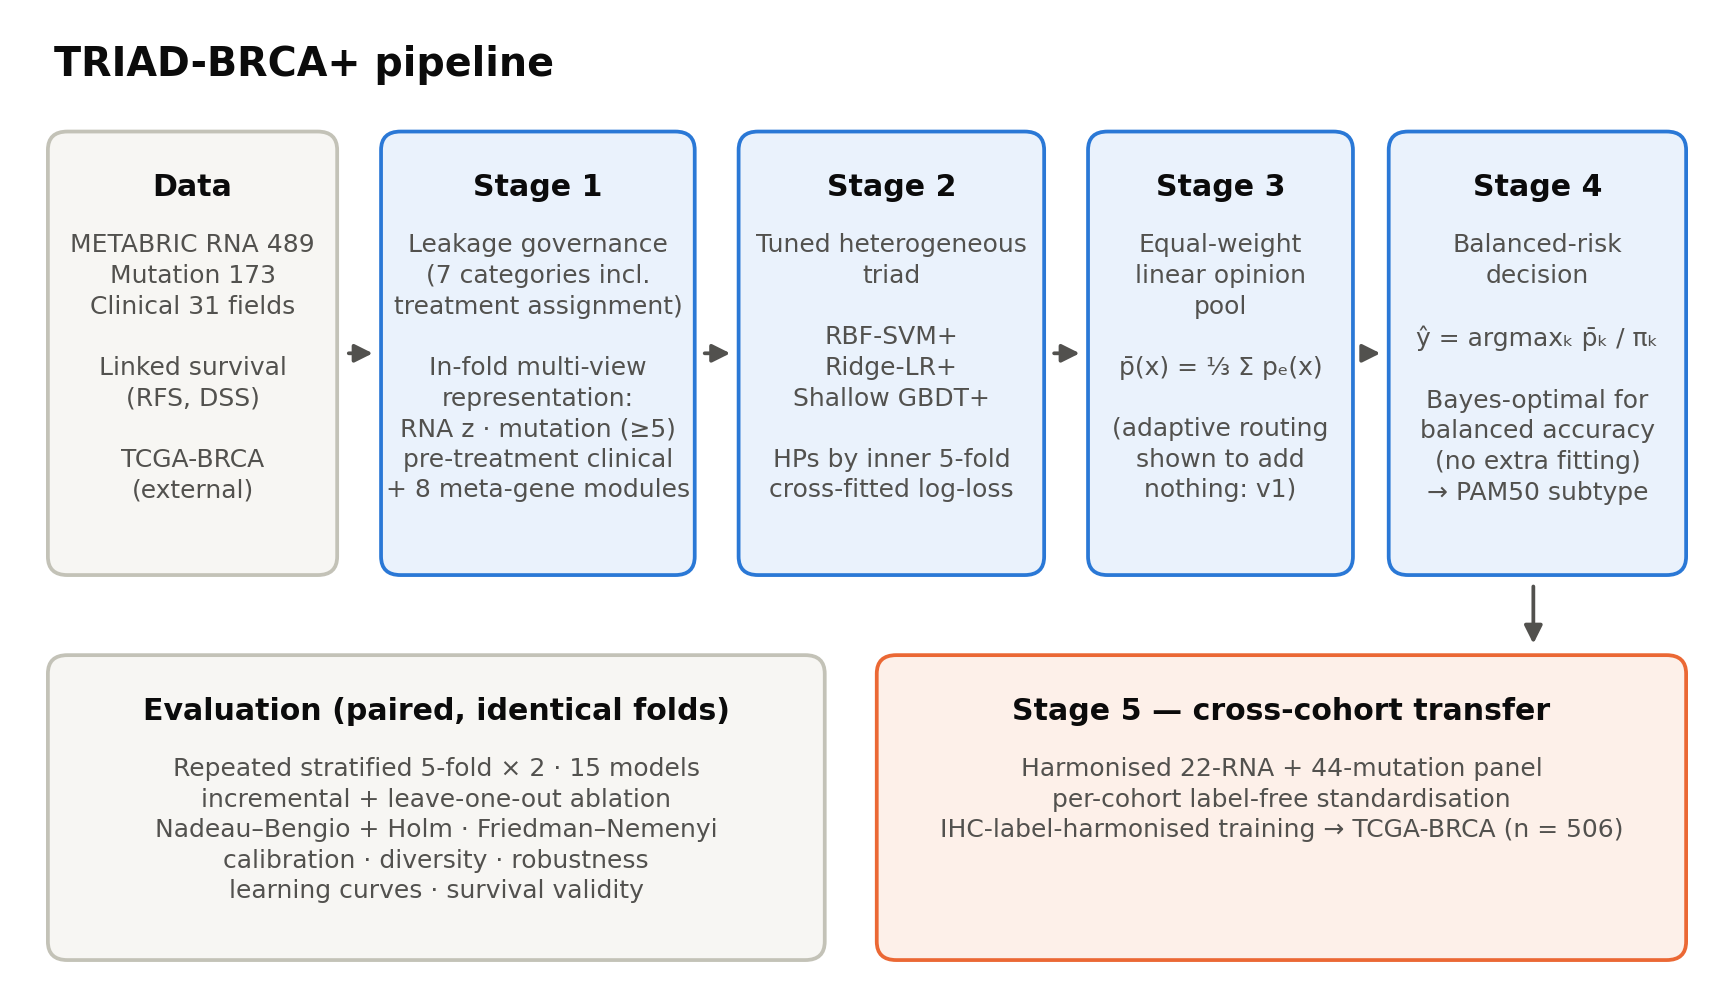

**Figure2 cohort_modules.** (a) PAM50 label distribution in METABRIC; the four reproducible subtypes form the analytical cohort. (b) Distribution of four knowledge-guided module scores by subtype.

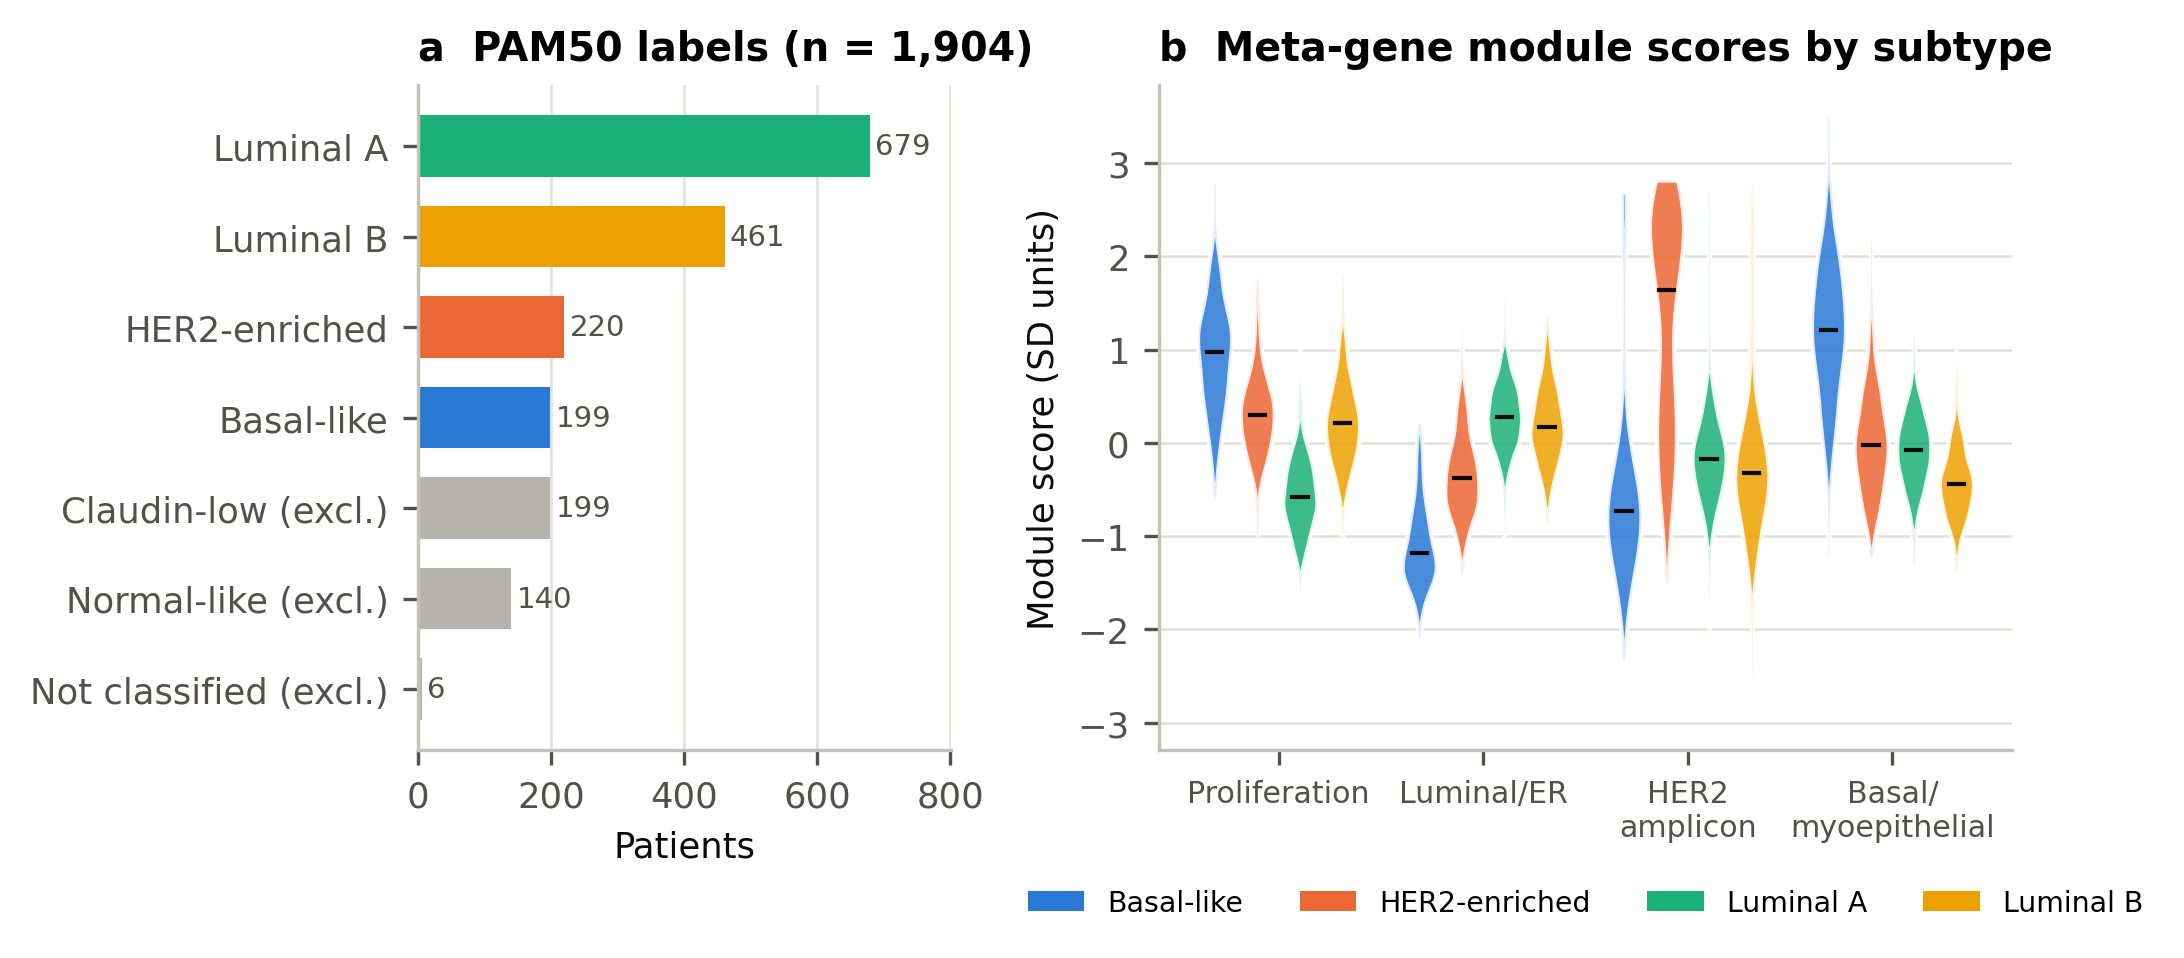

**Figure3 leakage_audit.** Leakage audit (10 paired folds). (a) Change in Balanced Accuracy when each excluded channel is re-inserted, for three probes (mean ± SD). (b) Optimism from reporting accuracy instead of balanced accuracy, and from fitting preprocessing on the full cohort (v1 SVM expert).

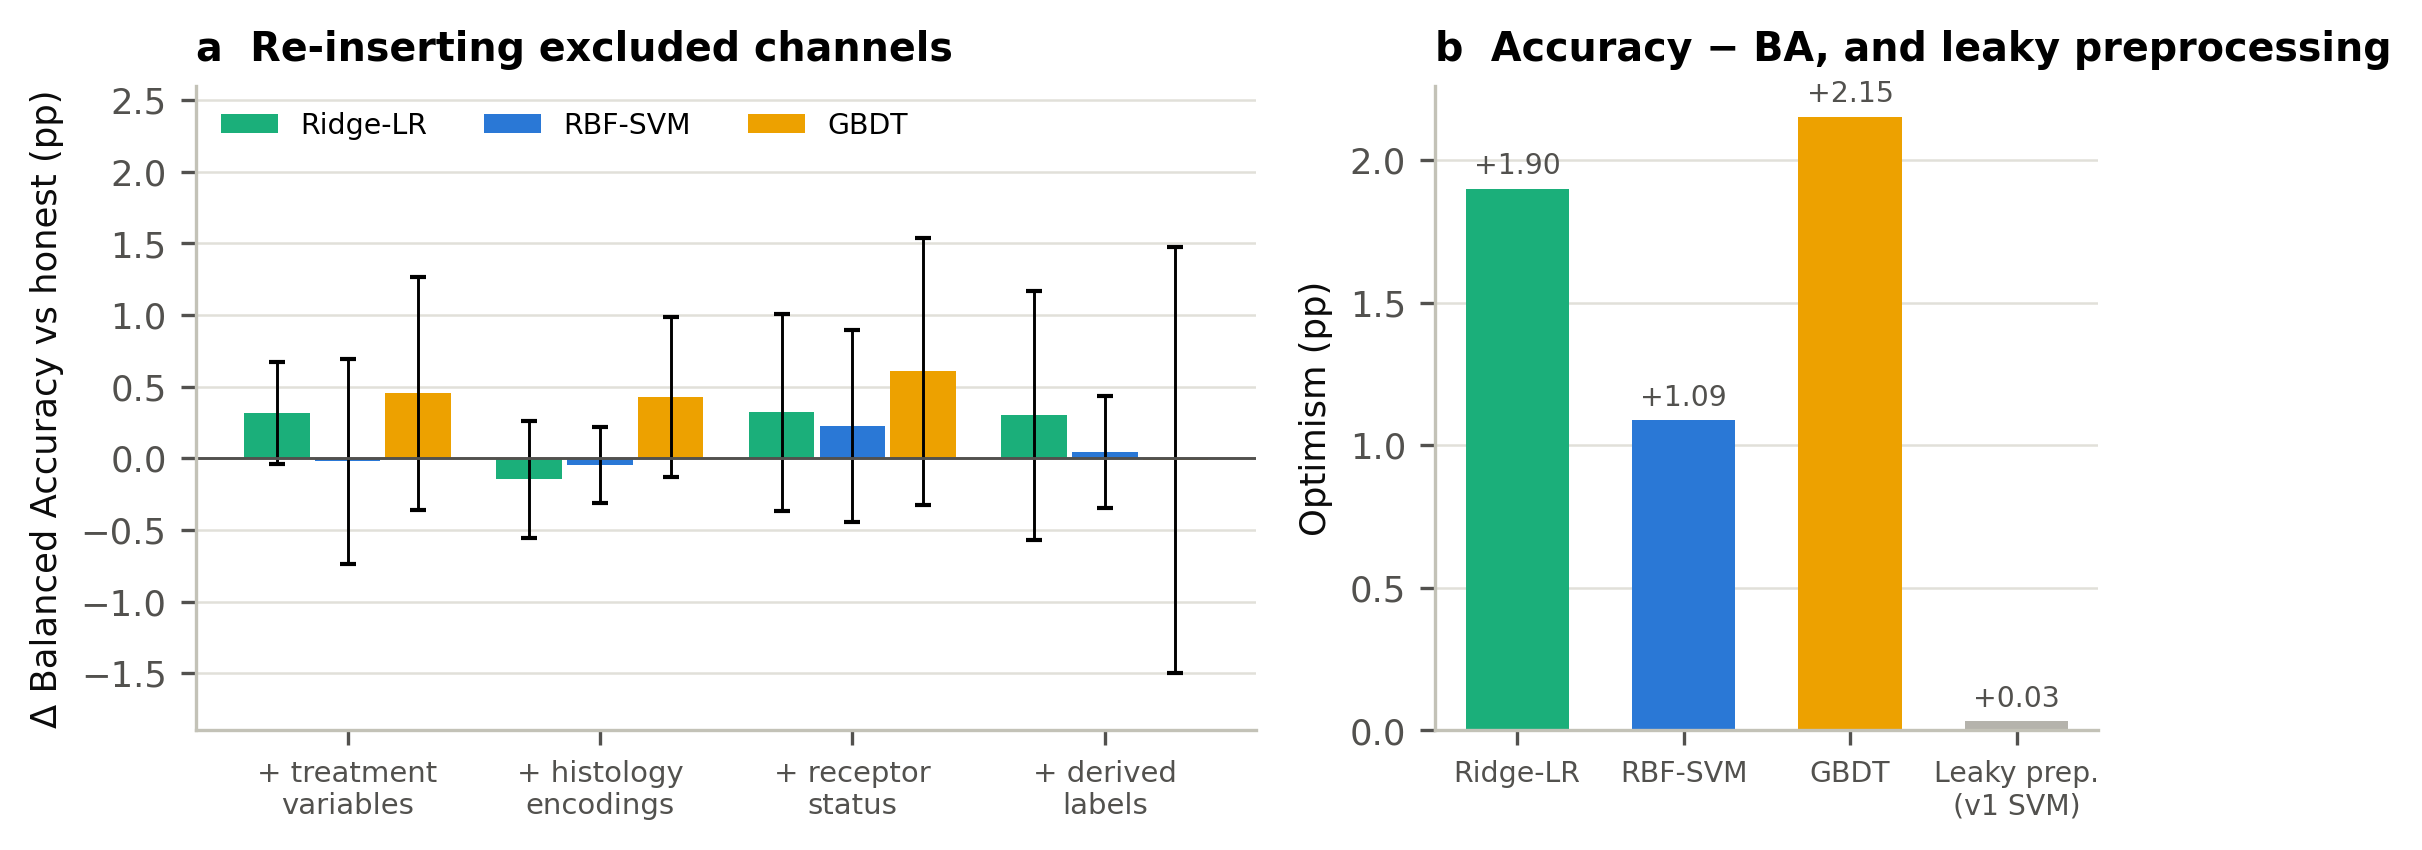

**Figure4 model_comparison.** Model comparison (mean ± SD over 10 paired folds; small dots = individual folds). Dashed line: TRIAD-BRCA v1 equal-weight ensemble.

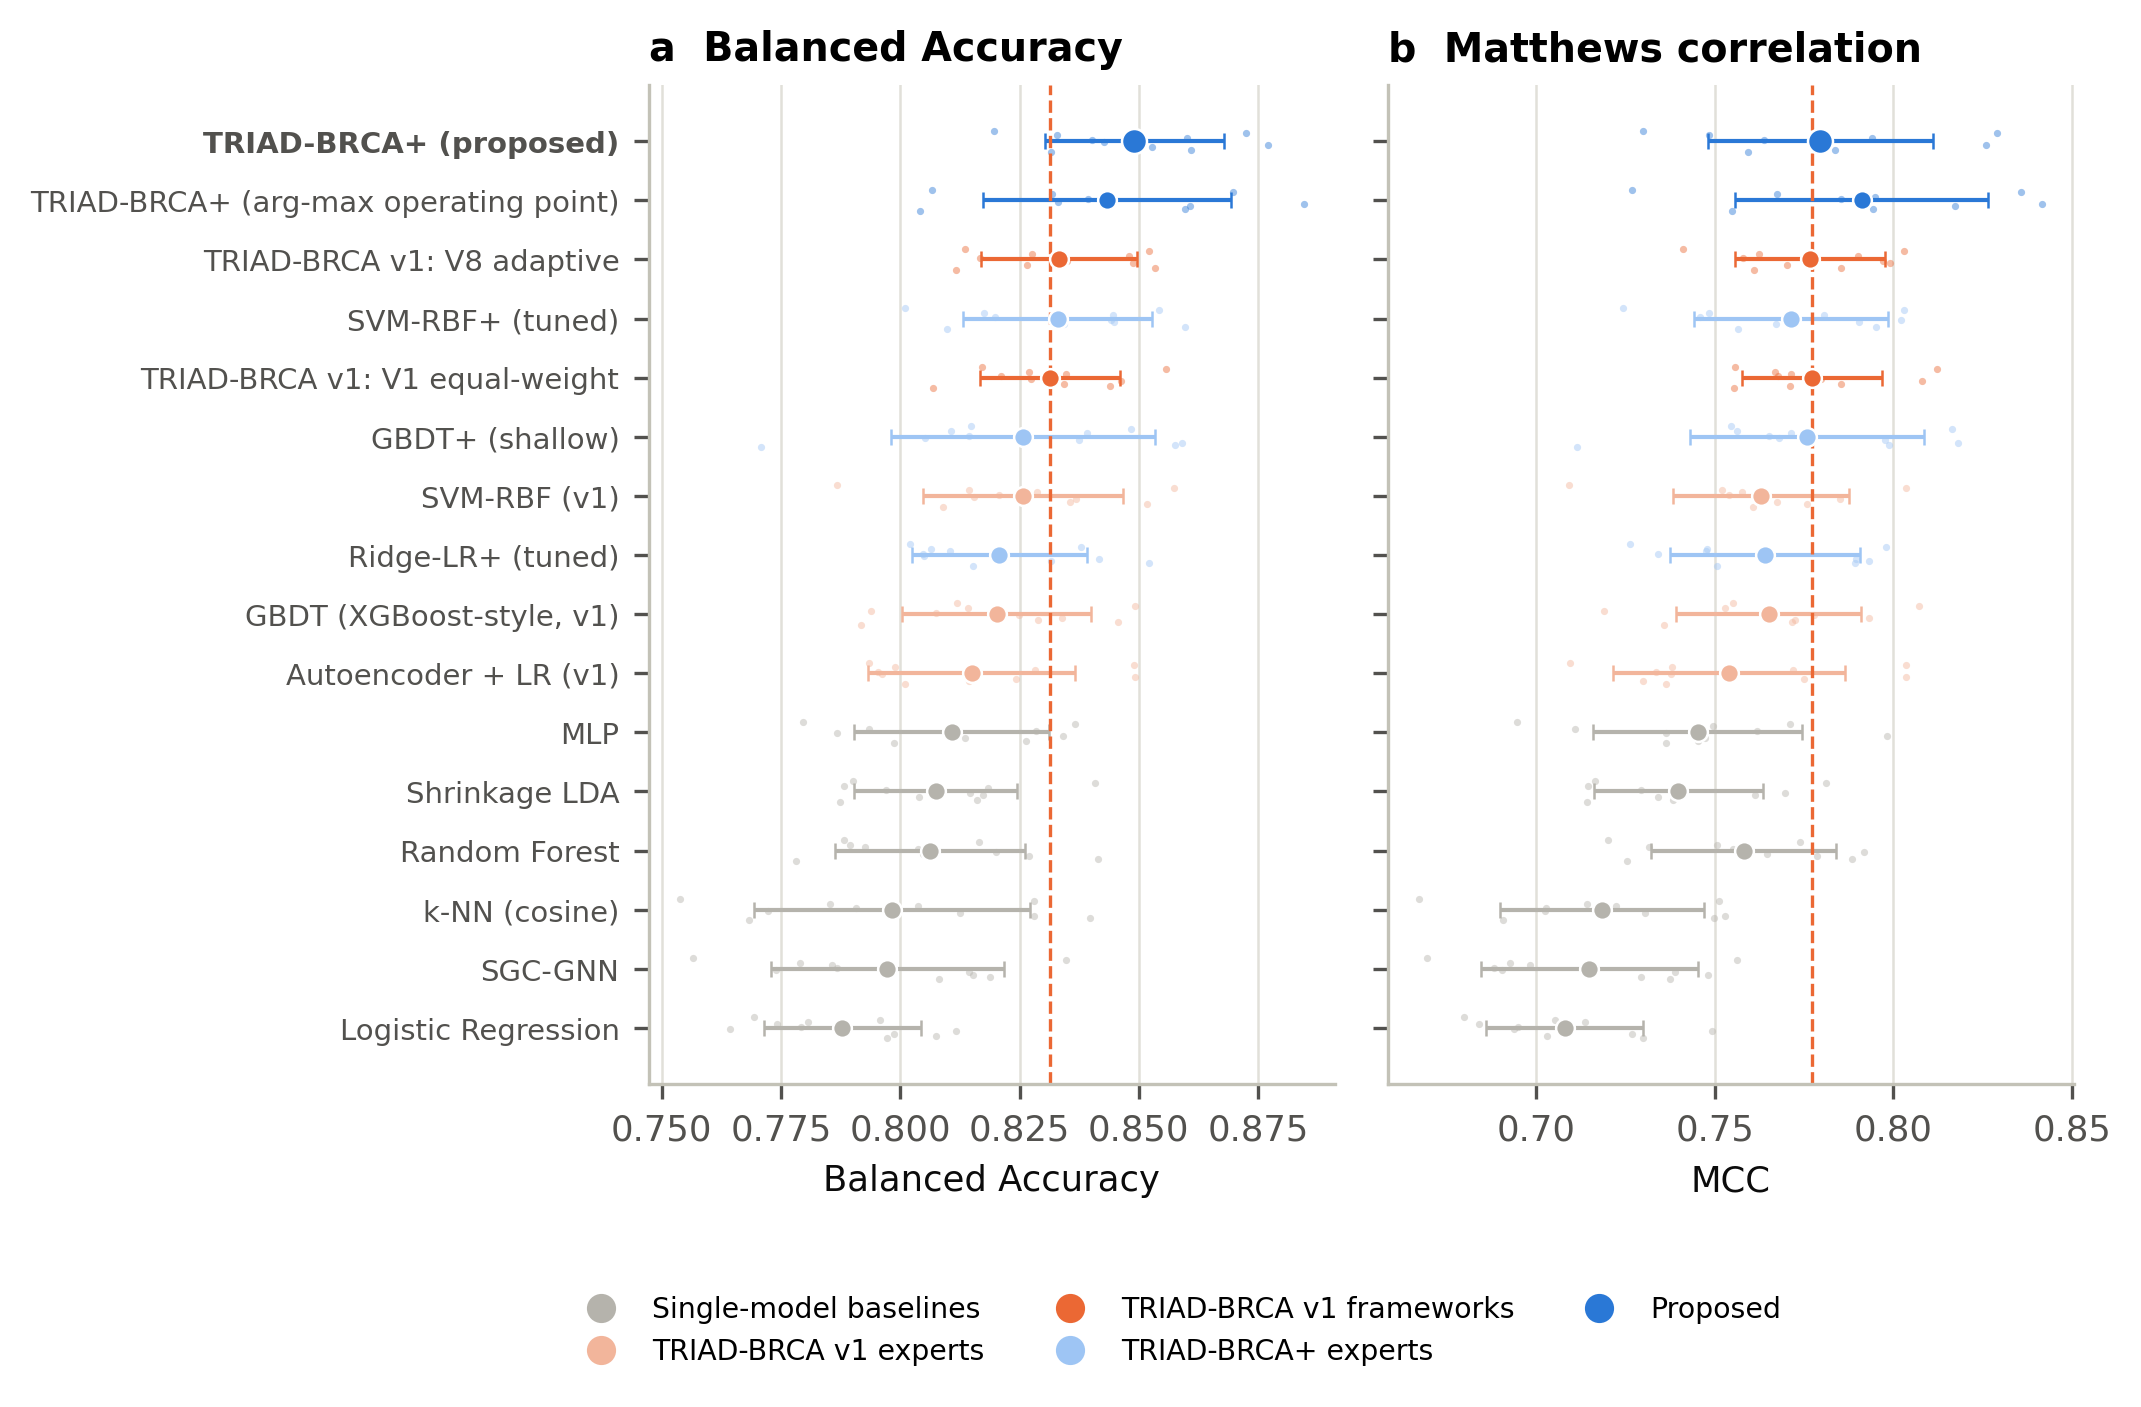

**Figure5 critical_difference.** Critical-difference diagram of mean Balanced-Accuracy ranks over the 10 paired folds (lower rank = better). Thick bars join models that are not significantly different (Nemenyi).

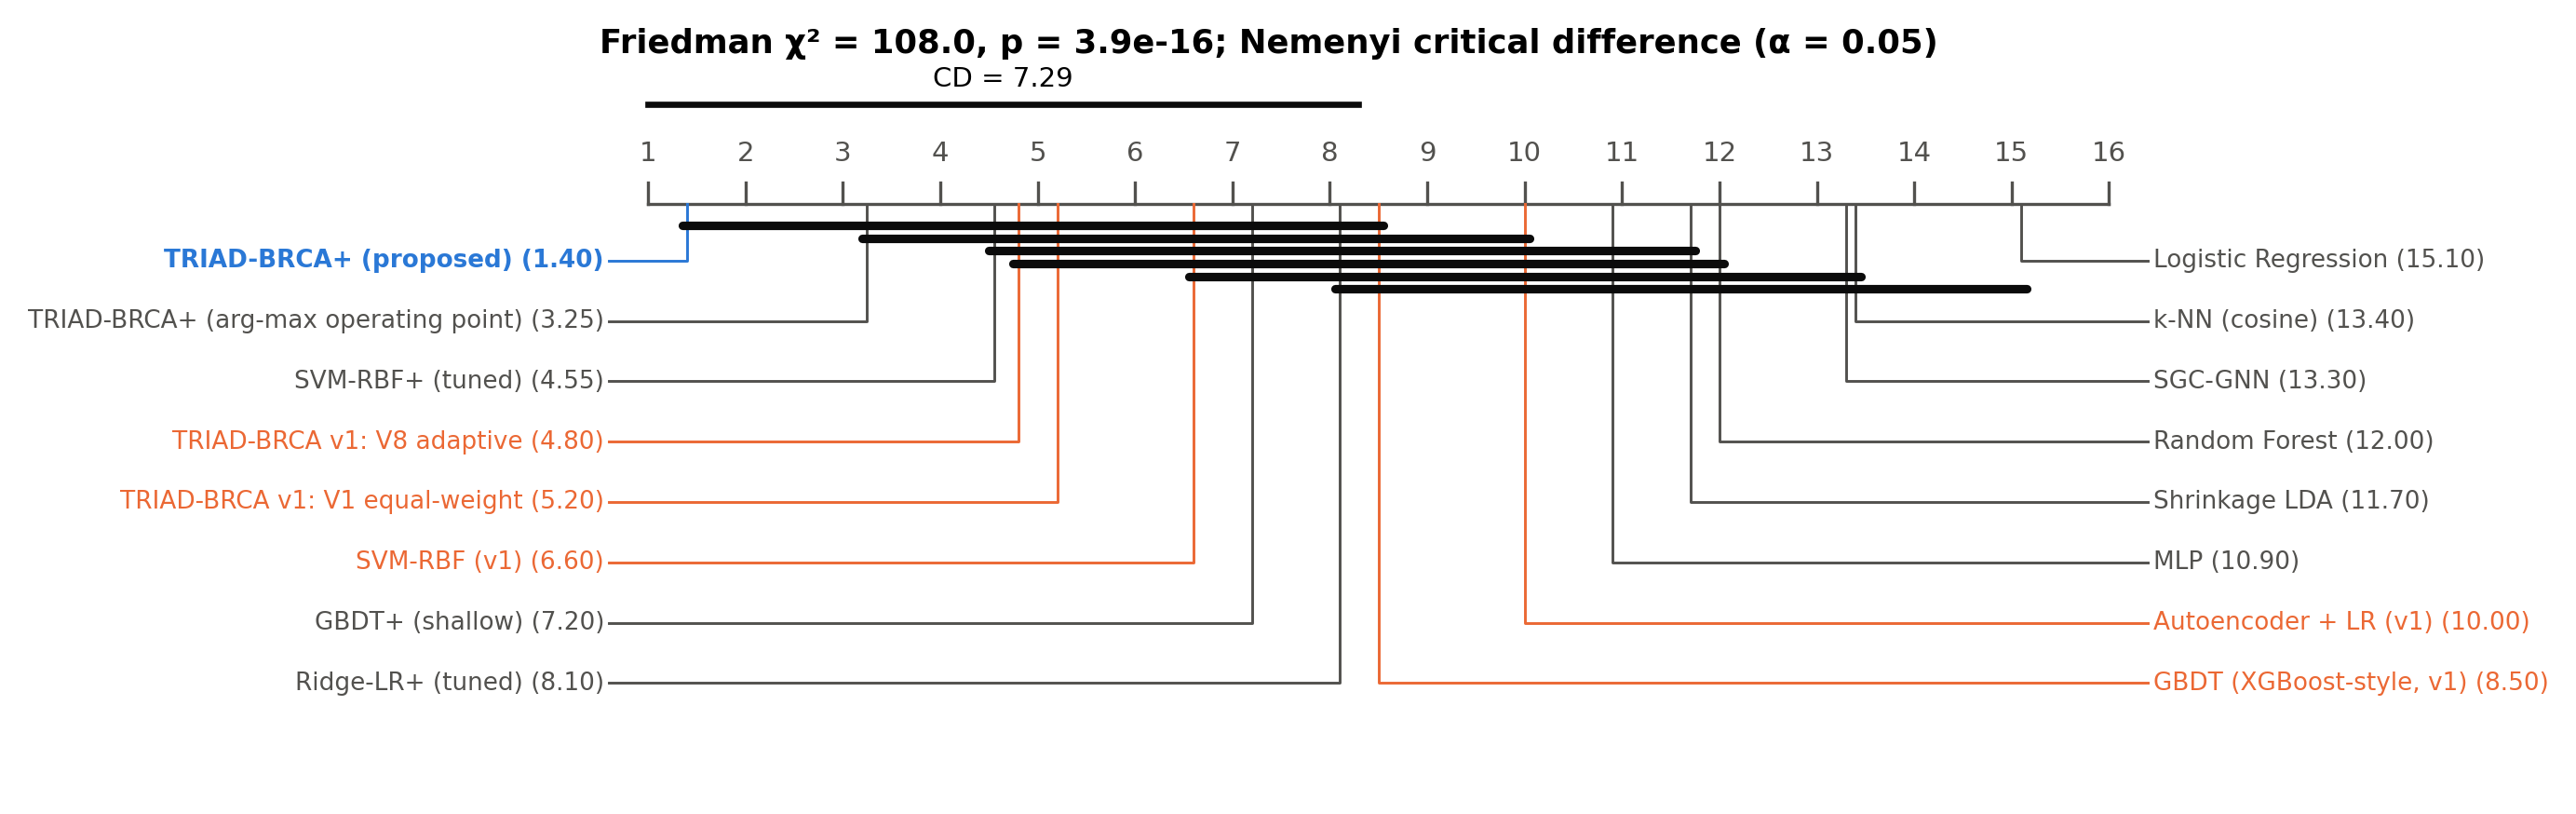

**Figure6 ablation.** Incremental ablation waterfall from TRIAD-BRCA v1 (A0) to TRIAD-BRCA+ (A5); labels give the mean change contributed by each component.

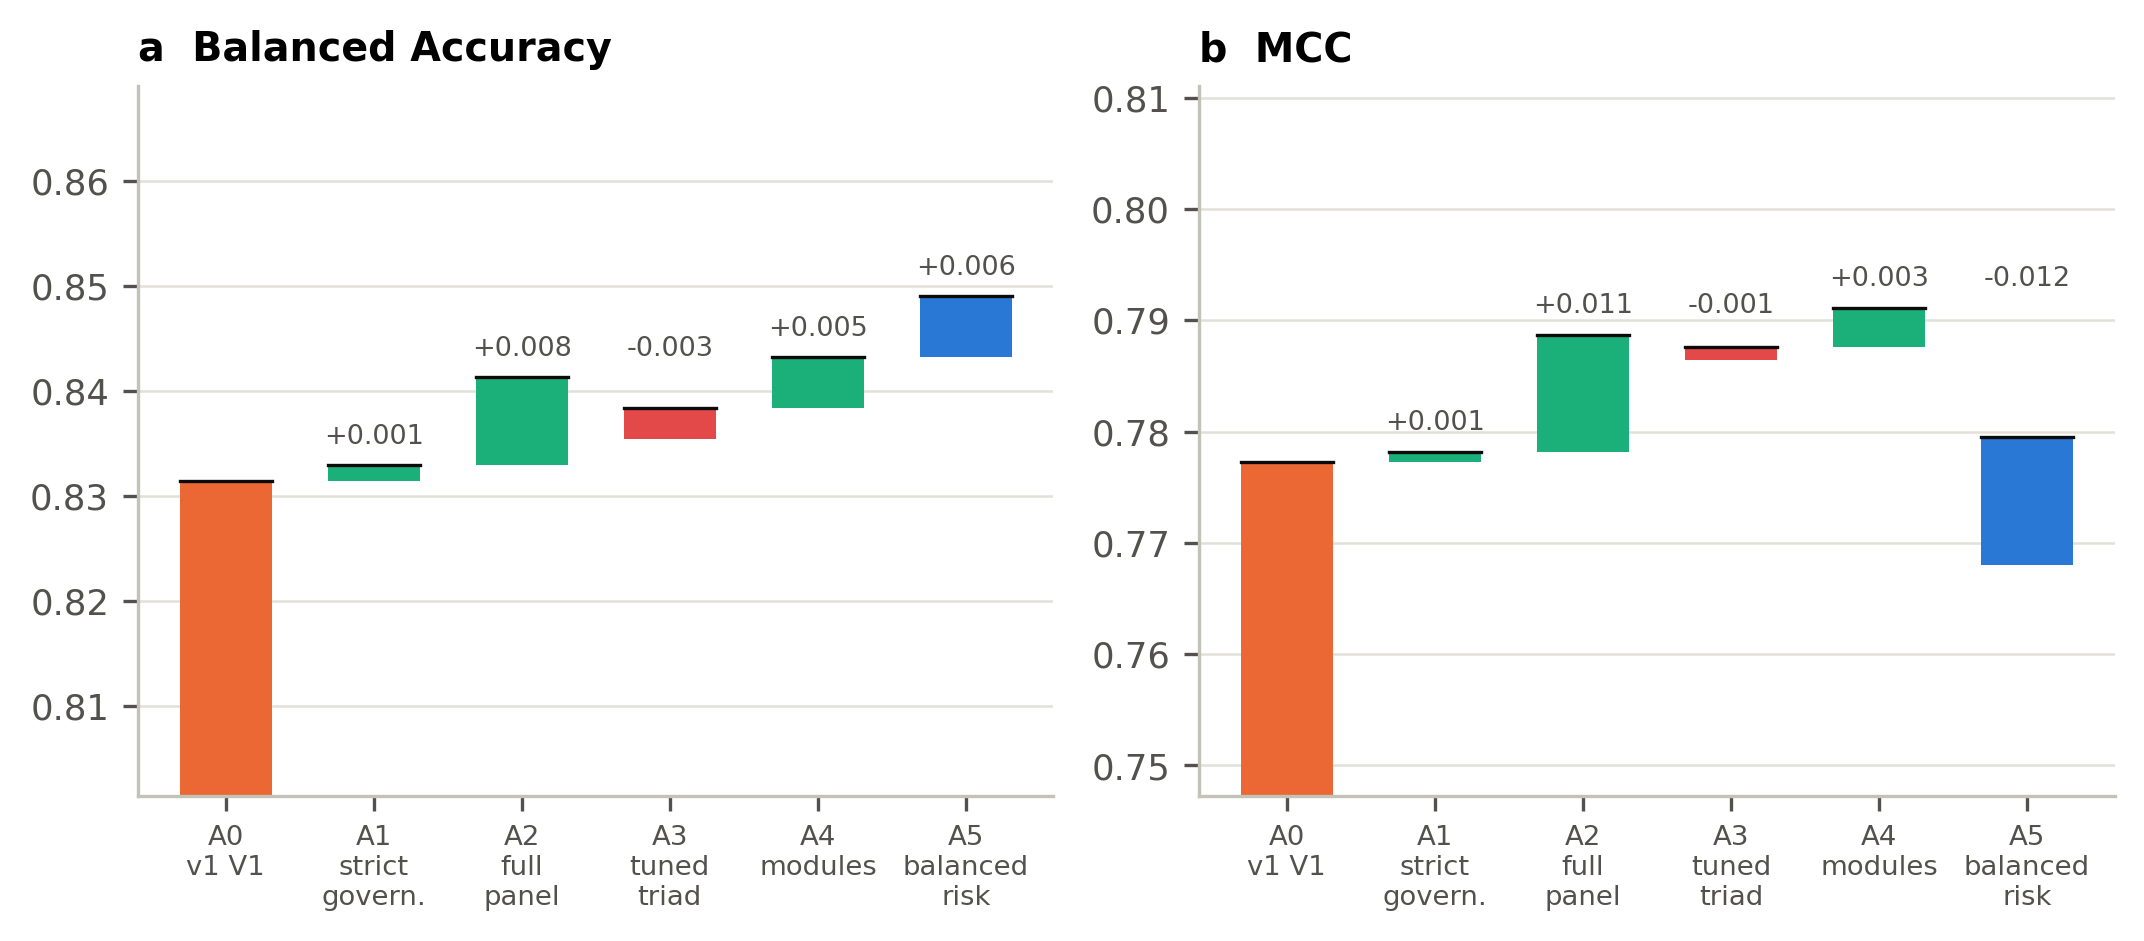

**Figure7 fusion_decision.** Balanced Accuracy for every combination of fusion and decision rule on the same TRIAD-BRCA+ expert fits. Gains come from the decision layer, not from learned or adaptive fusion.

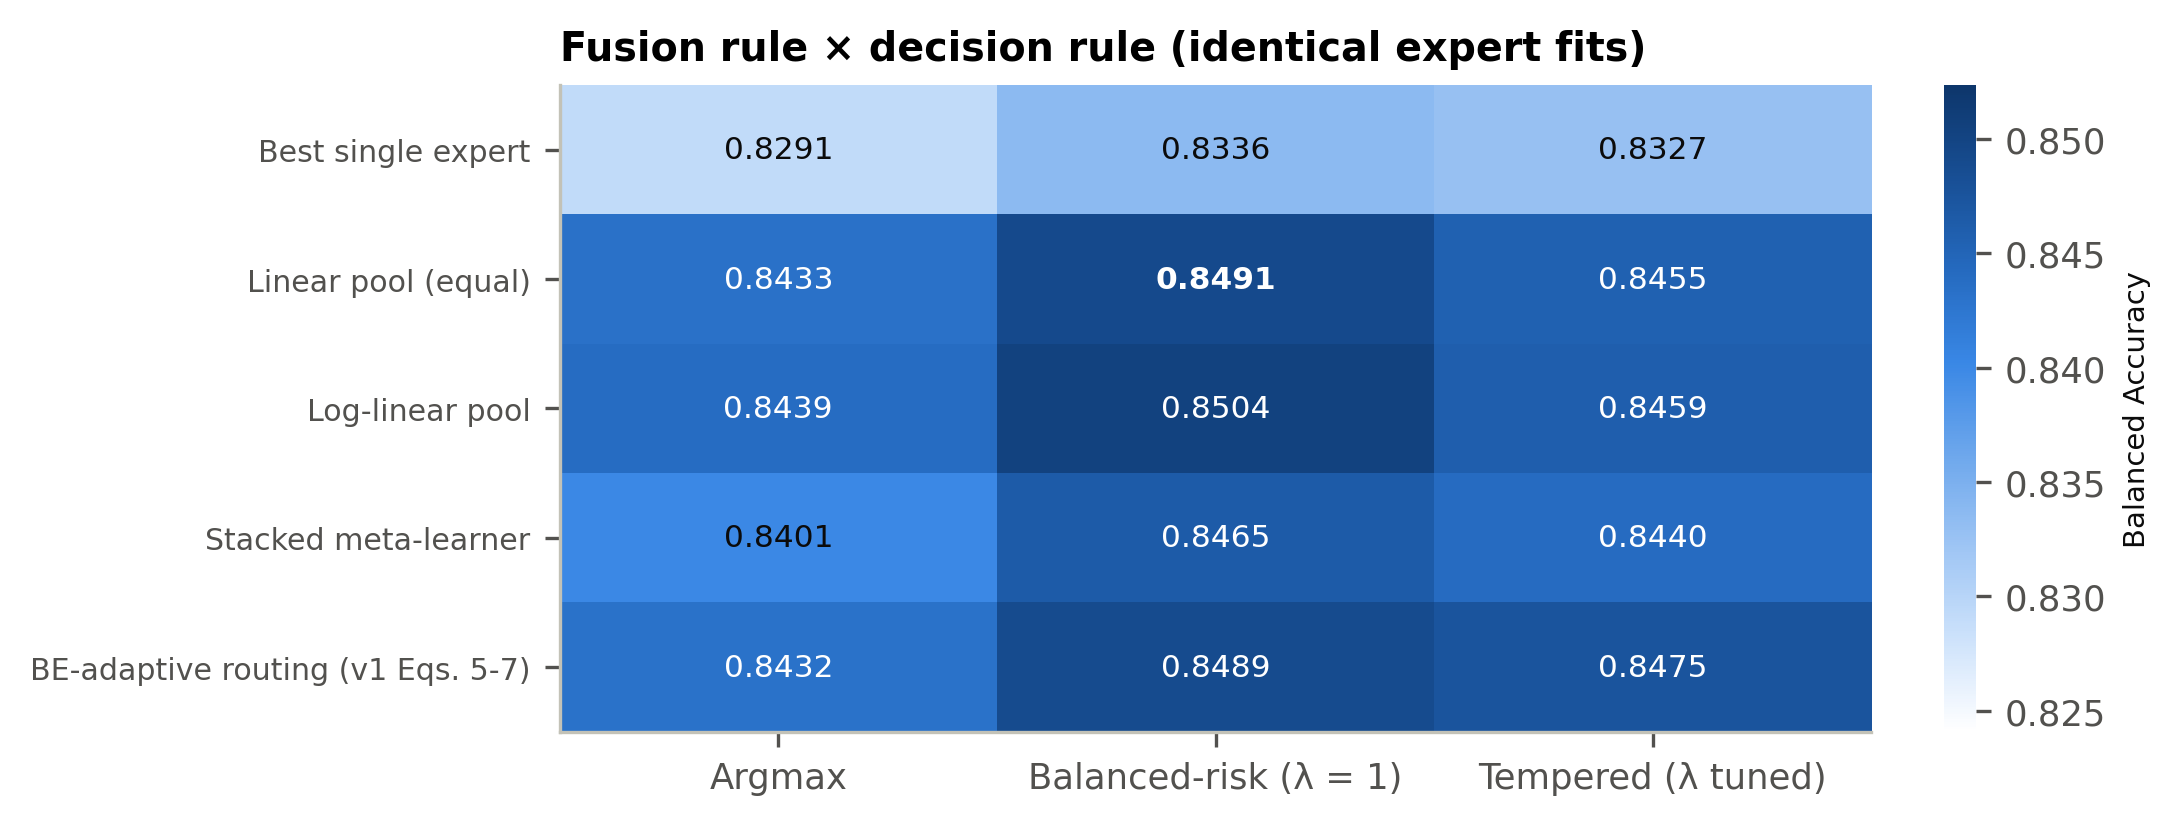

**Figure8 confusion.** Confusion matrices of pooled out-of-fold predictions (repeat 1, n = 1,559); cell text: count and row-normalised recall.

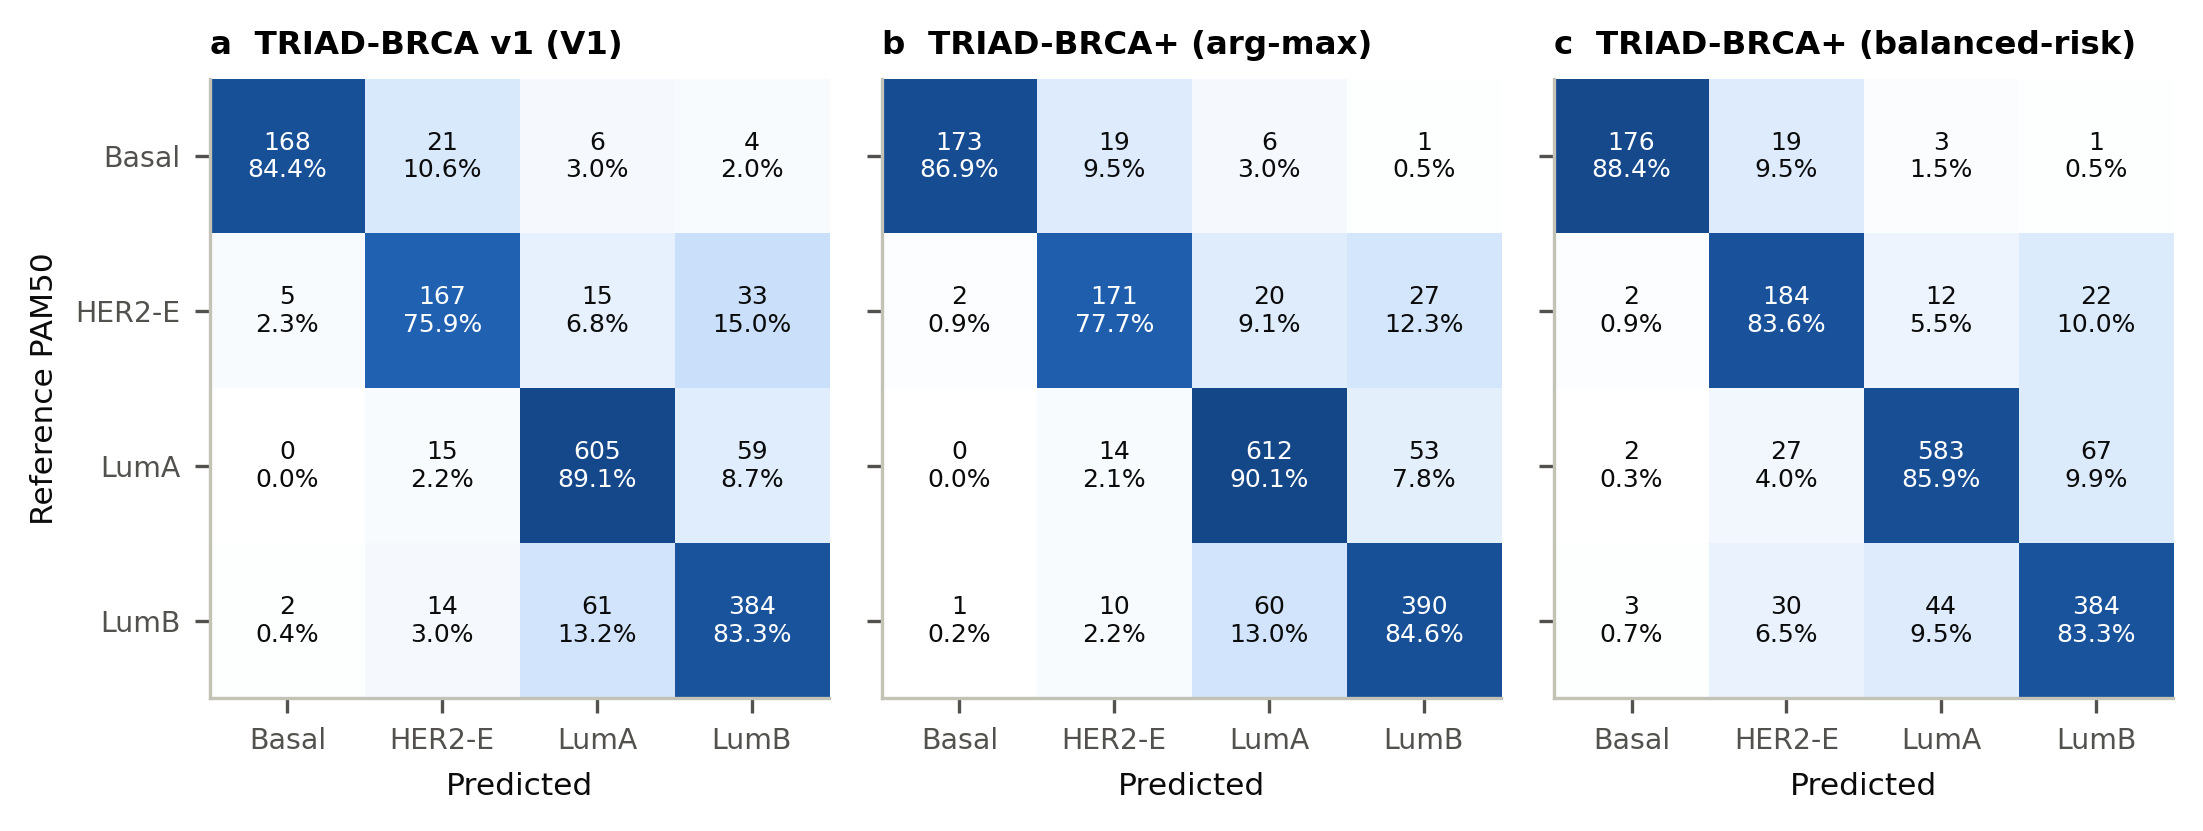

**Figure9 roc_pr.** Per-subtype ROC and precision–recall curves of the TRIAD-BRCA+ fused posterior (pooled out-of-fold, repeat 1).

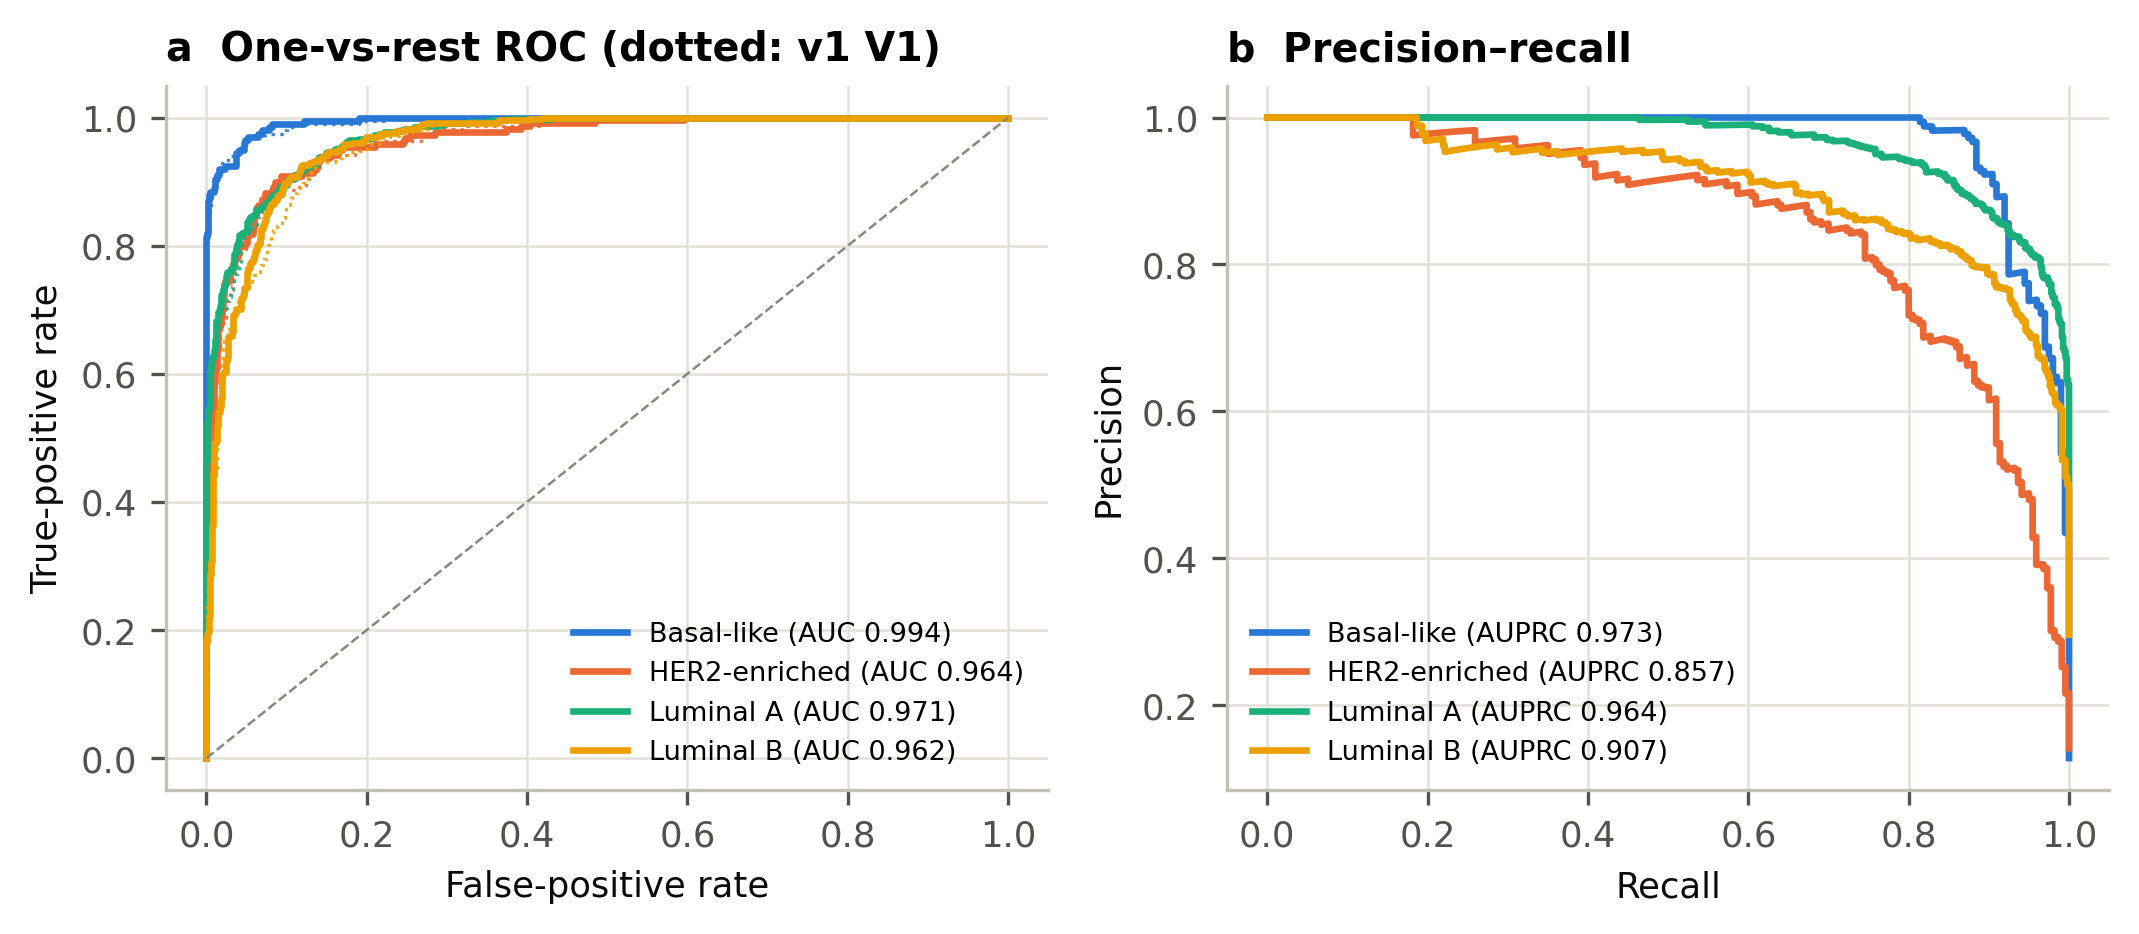

**Figure10 per_subtype.** Per-subtype F1 with bootstrap 95% CIs (pooled out-of-fold predictions).

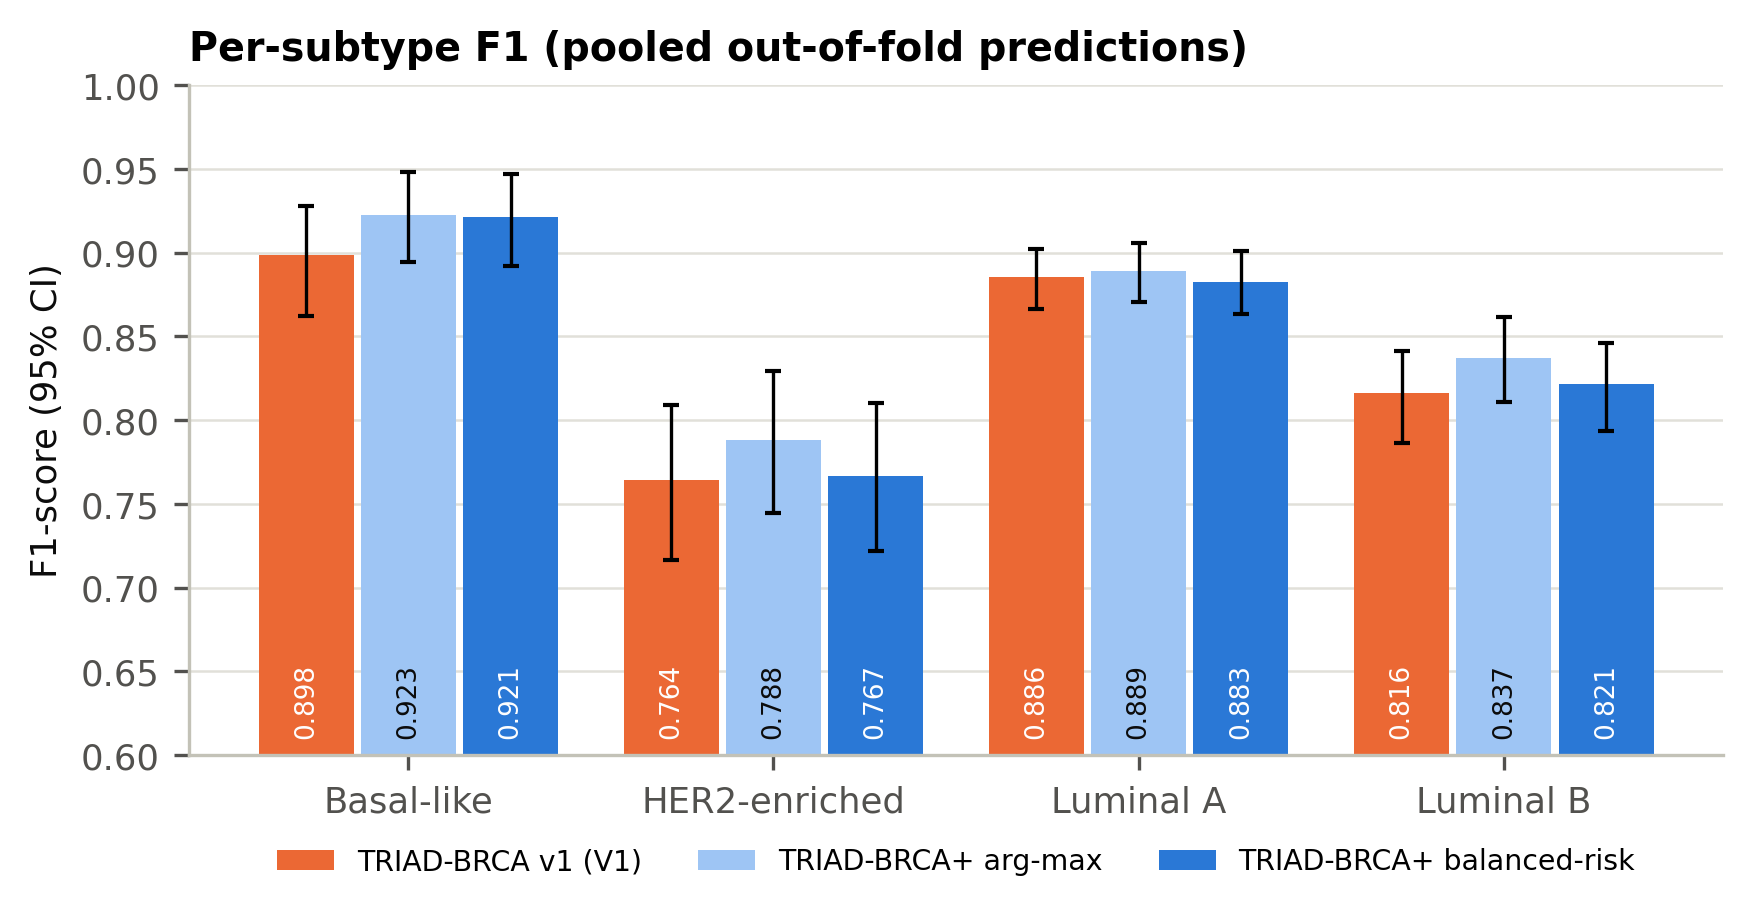

**Figure11 calibration.** Top-label reliability diagrams (10 bins, pooled out-of-fold posteriors).

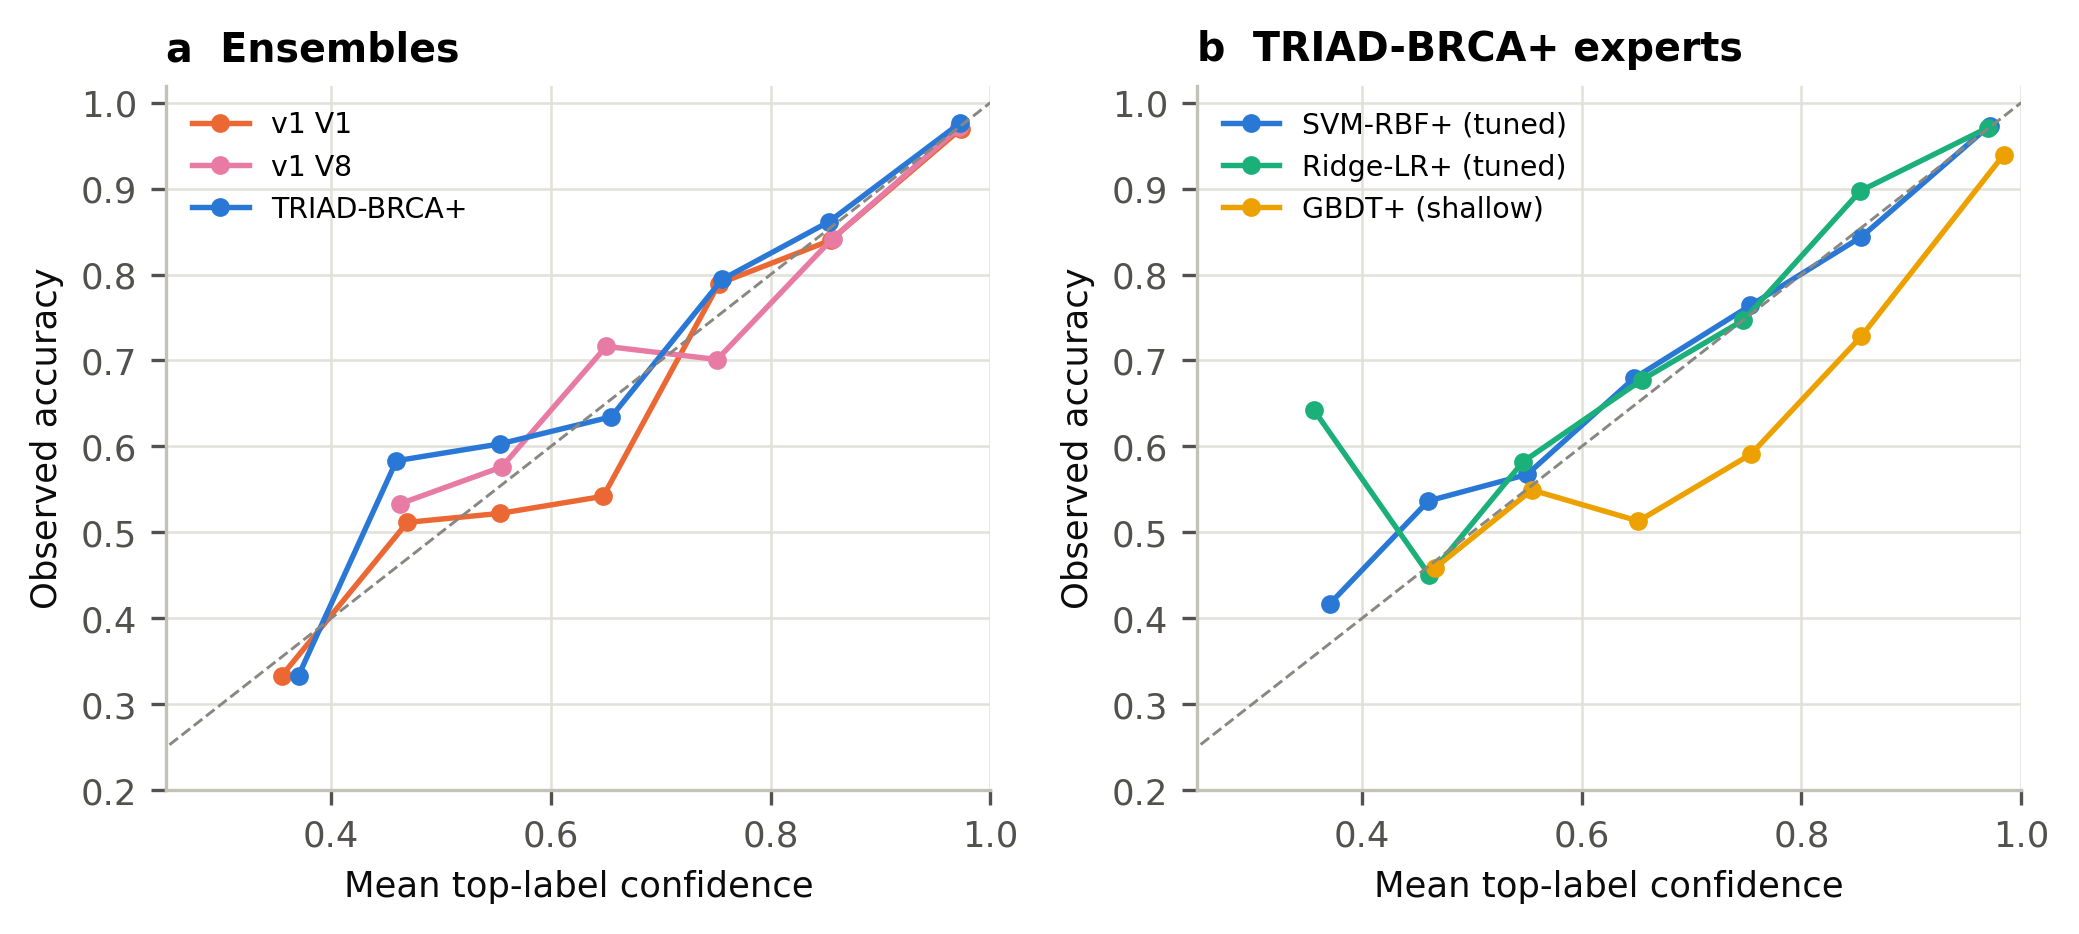

**Figure12 importance.** Permutation importance of TRIAD-BRCA+ on outer test folds (repeat 1).

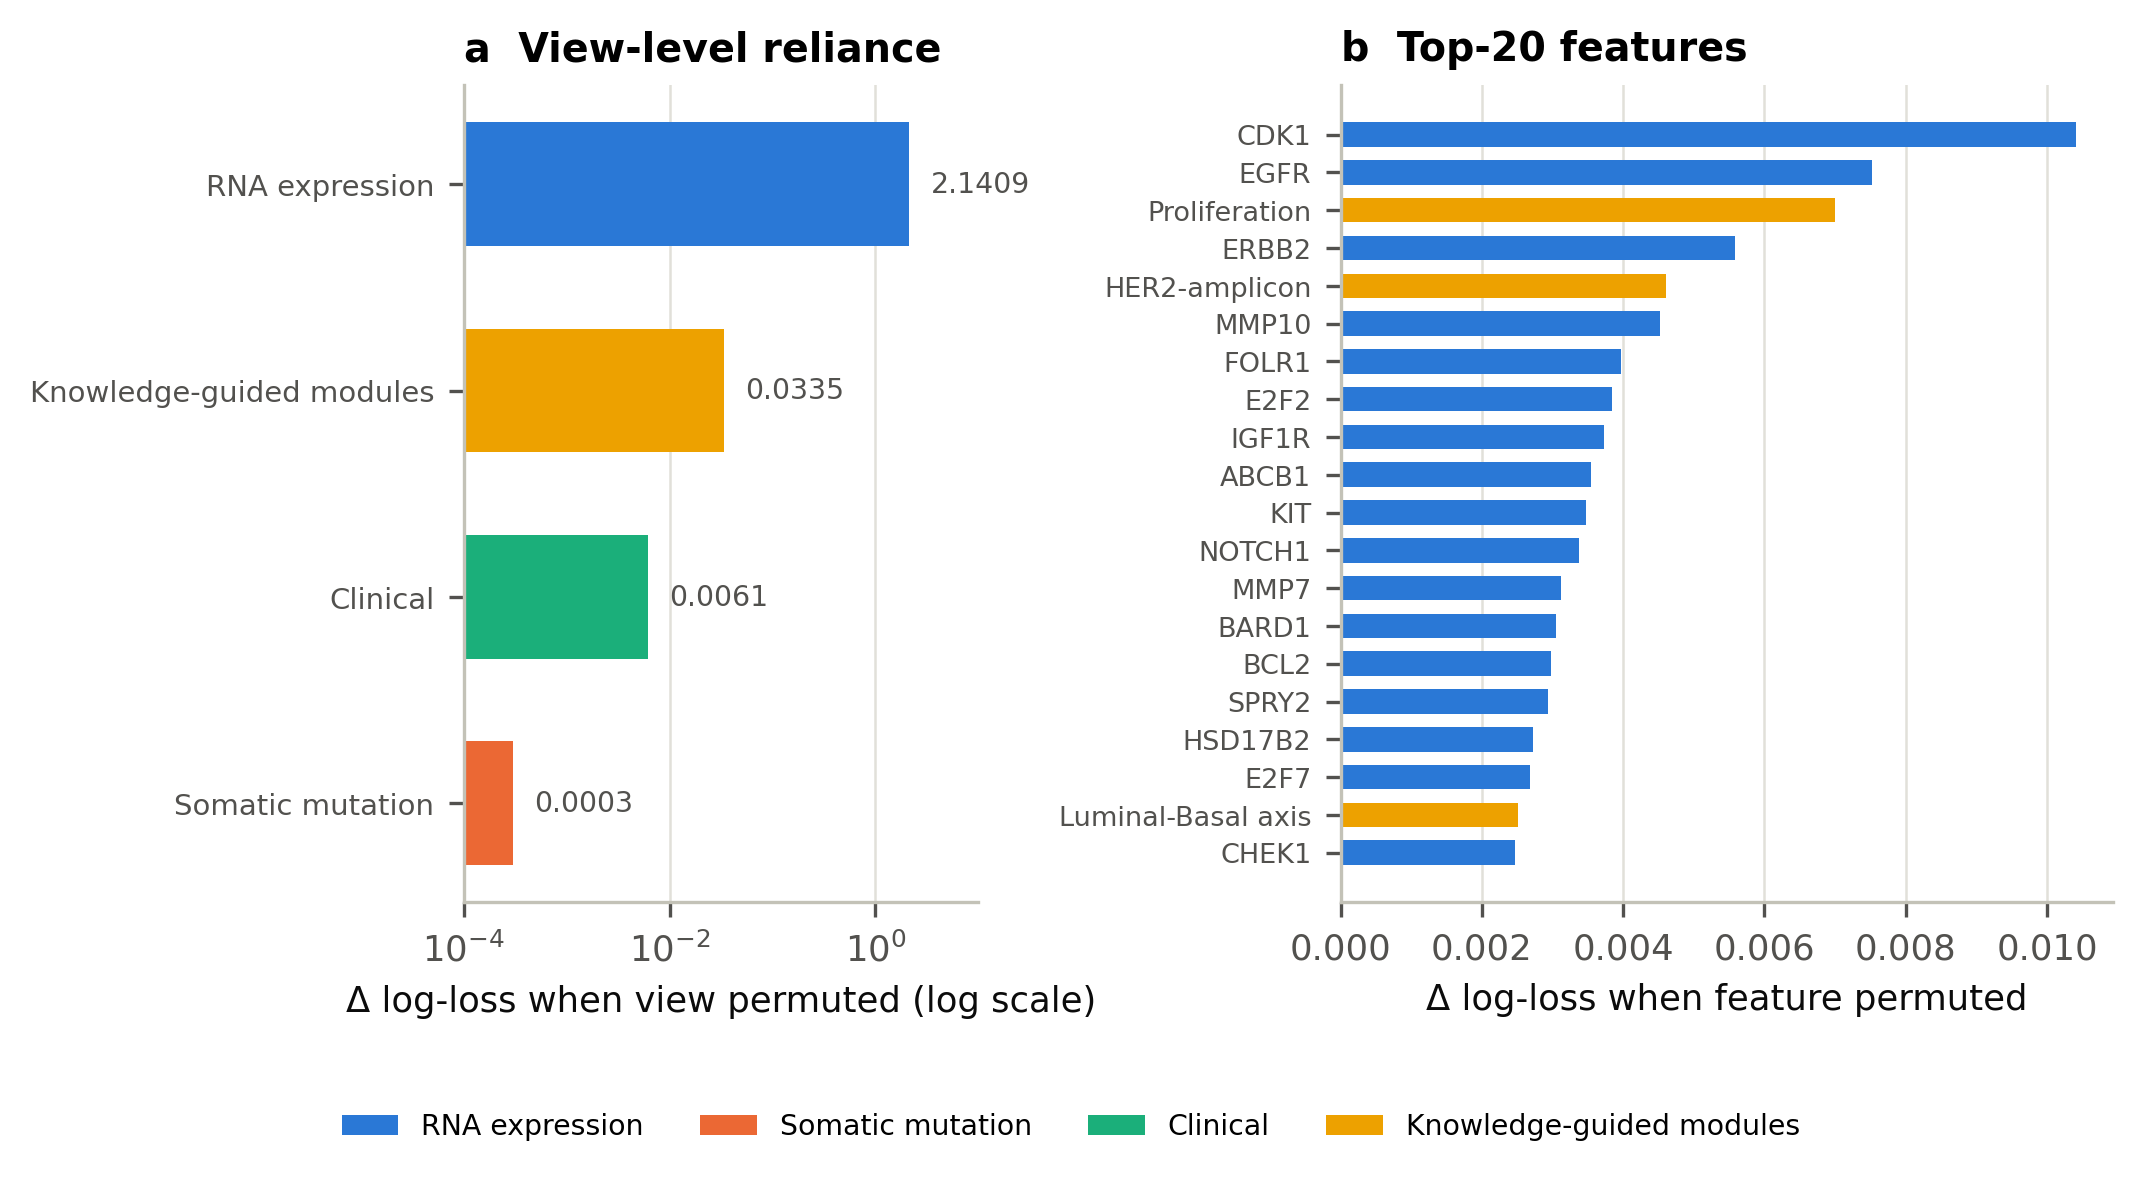

**Figure13 diversity.** Pairwise error correlation between experts (pooled out-of-fold predictions).

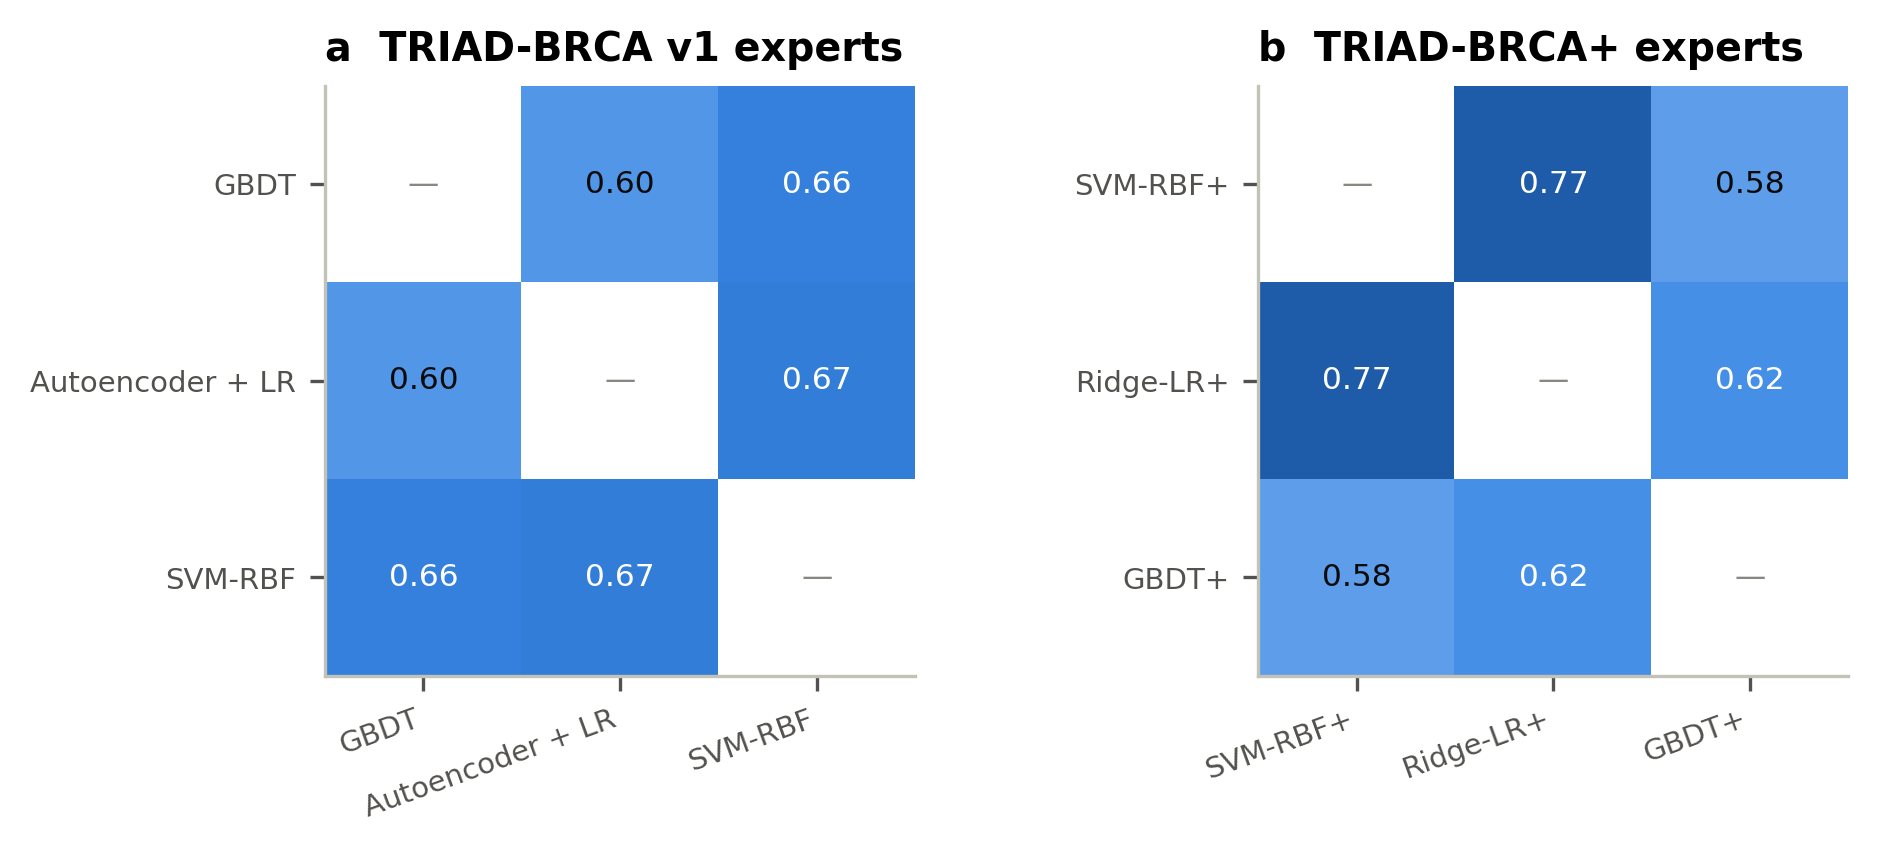

**Figure14 robustness.** Robustness to degraded molecular input at inference (mean ± SD, 5 folds).

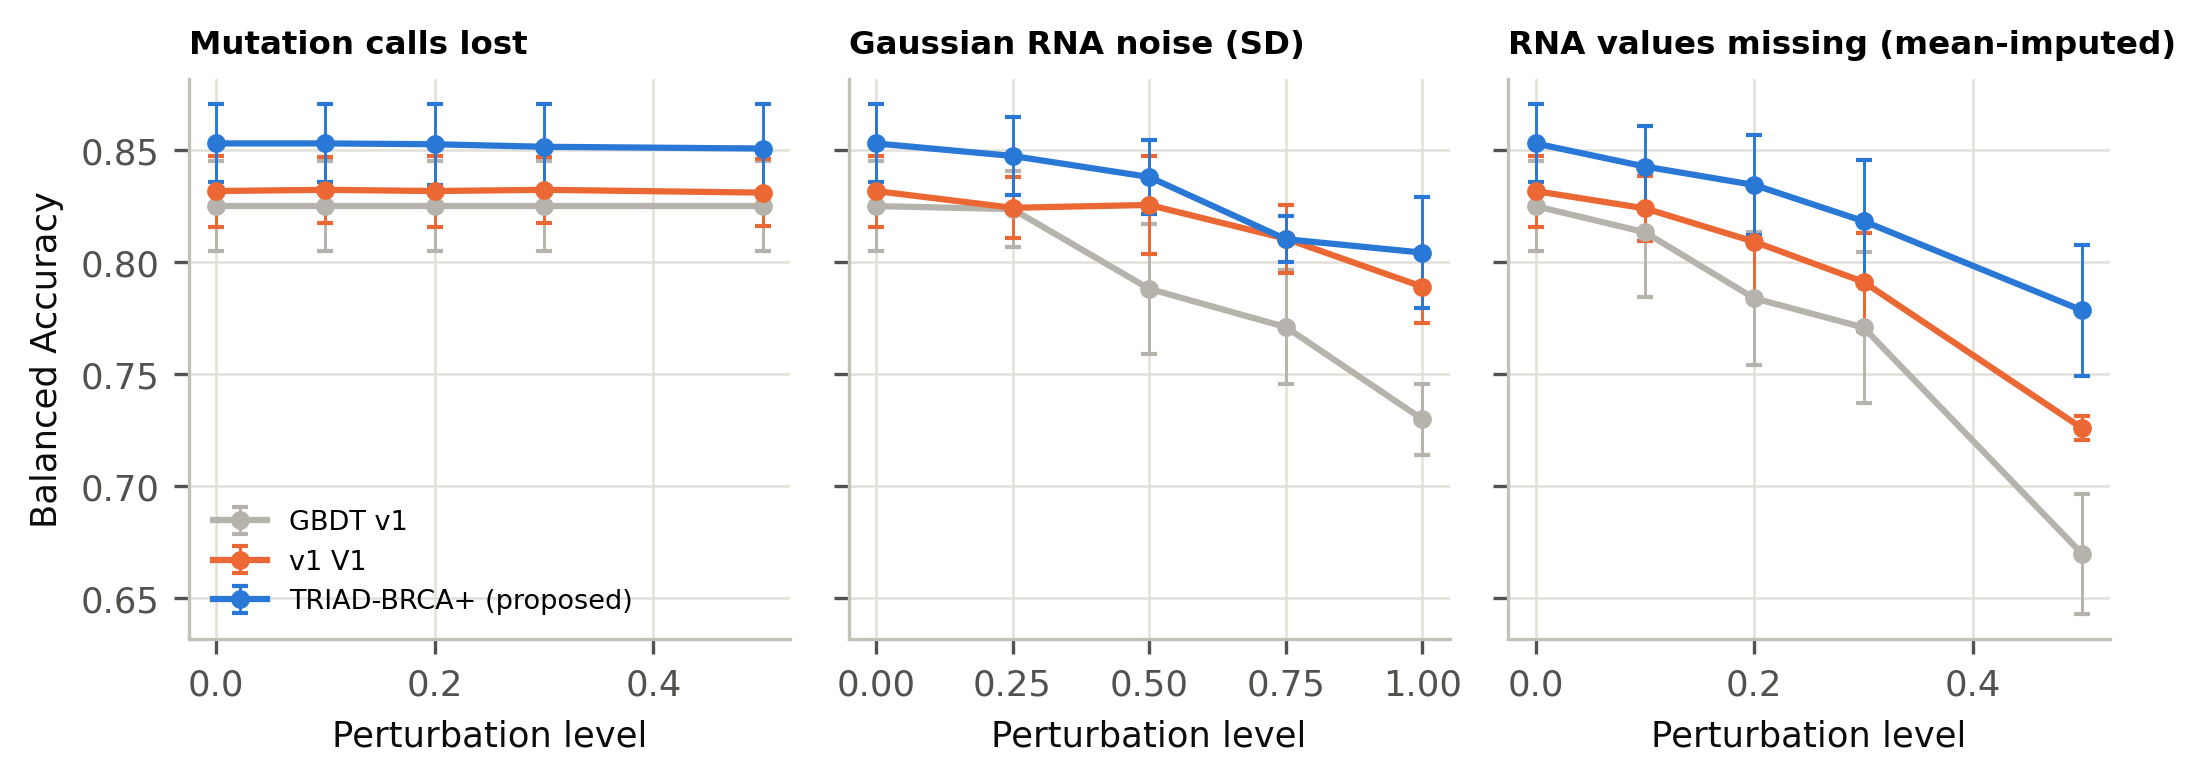

**Figure15 learning_curve.** Learning curves (mean ± SD over 5 folds of repeat 1).

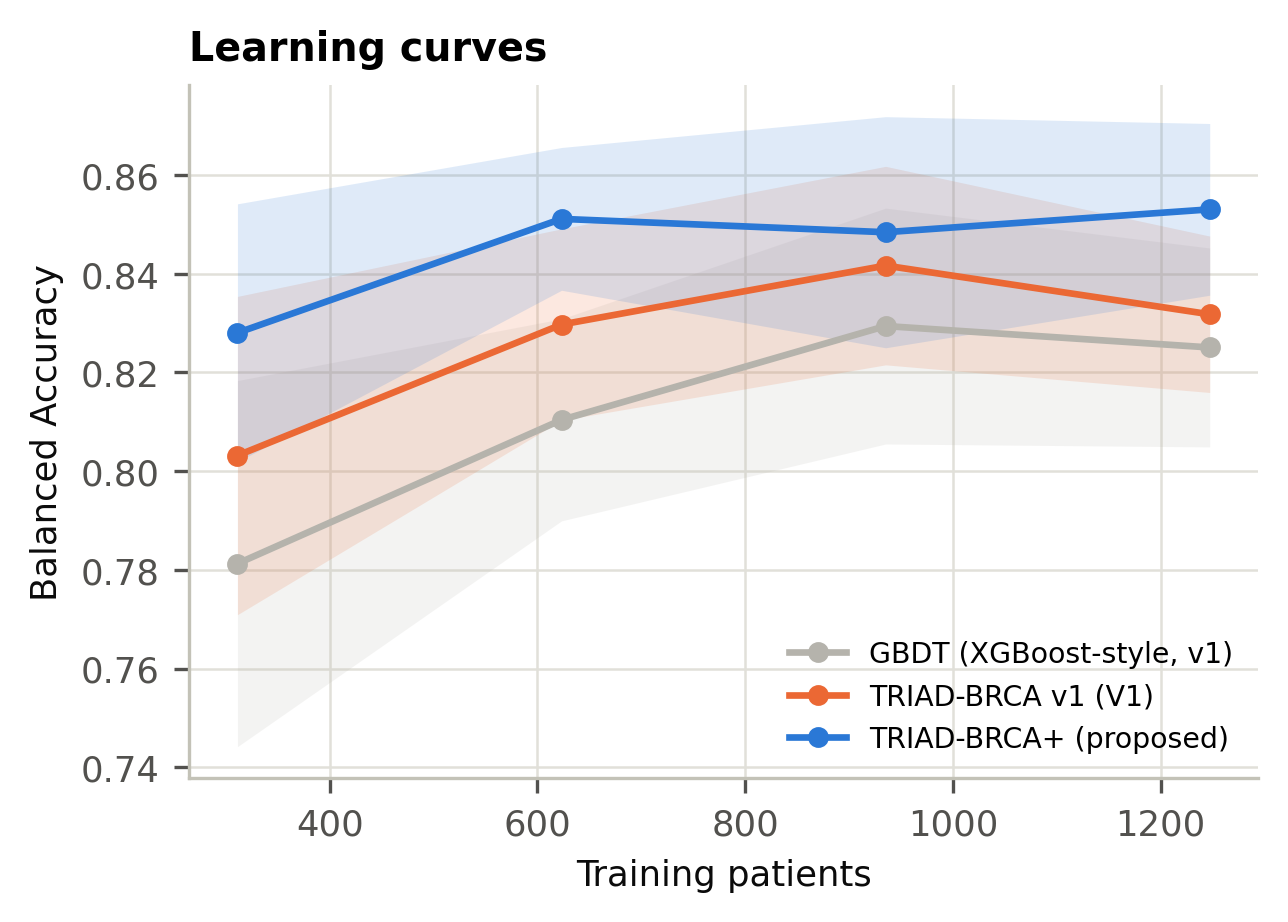

**Figure16 survival.** Kaplan–Meier curves by reference PAM50 label and by TRIAD-BRCA+ out-of-fold prediction.

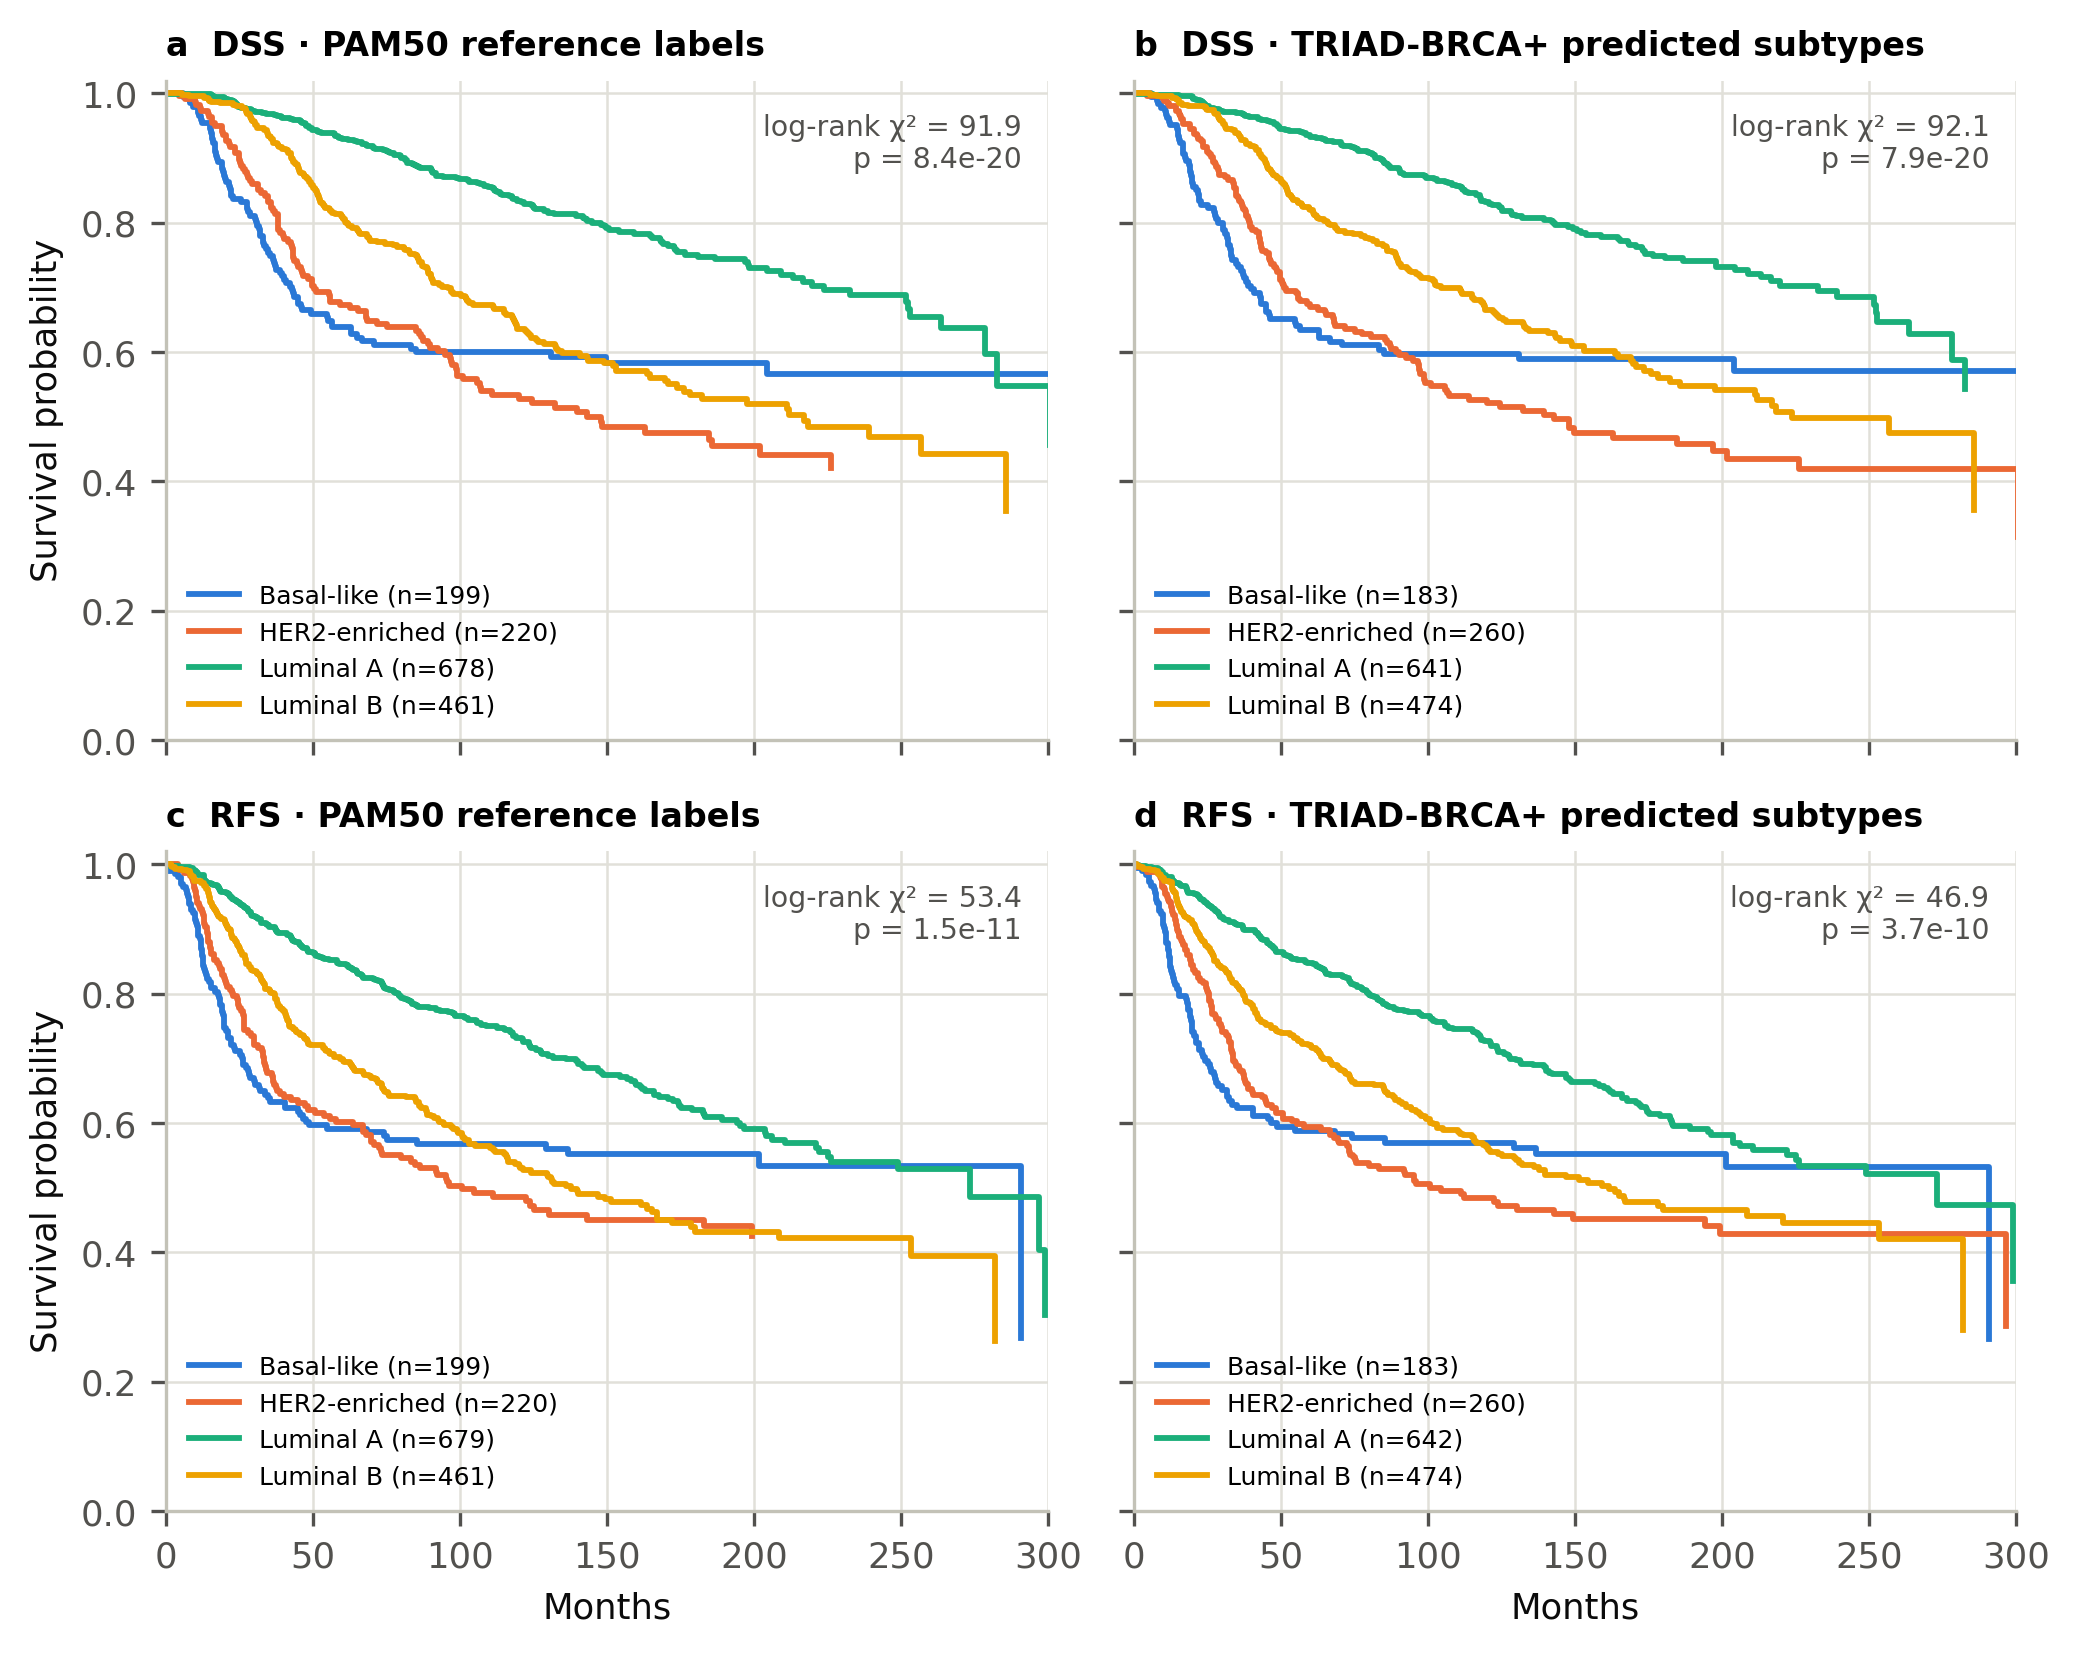

**Figure17 external.** External transfer to TCGA-BRCA (n = 506). (a) Balanced Accuracy with bootstrap 95% CIs under the v1 protocol (E1) and the proposed harmonisation protocols (E2, E3). (b–c) Confusion matrices.

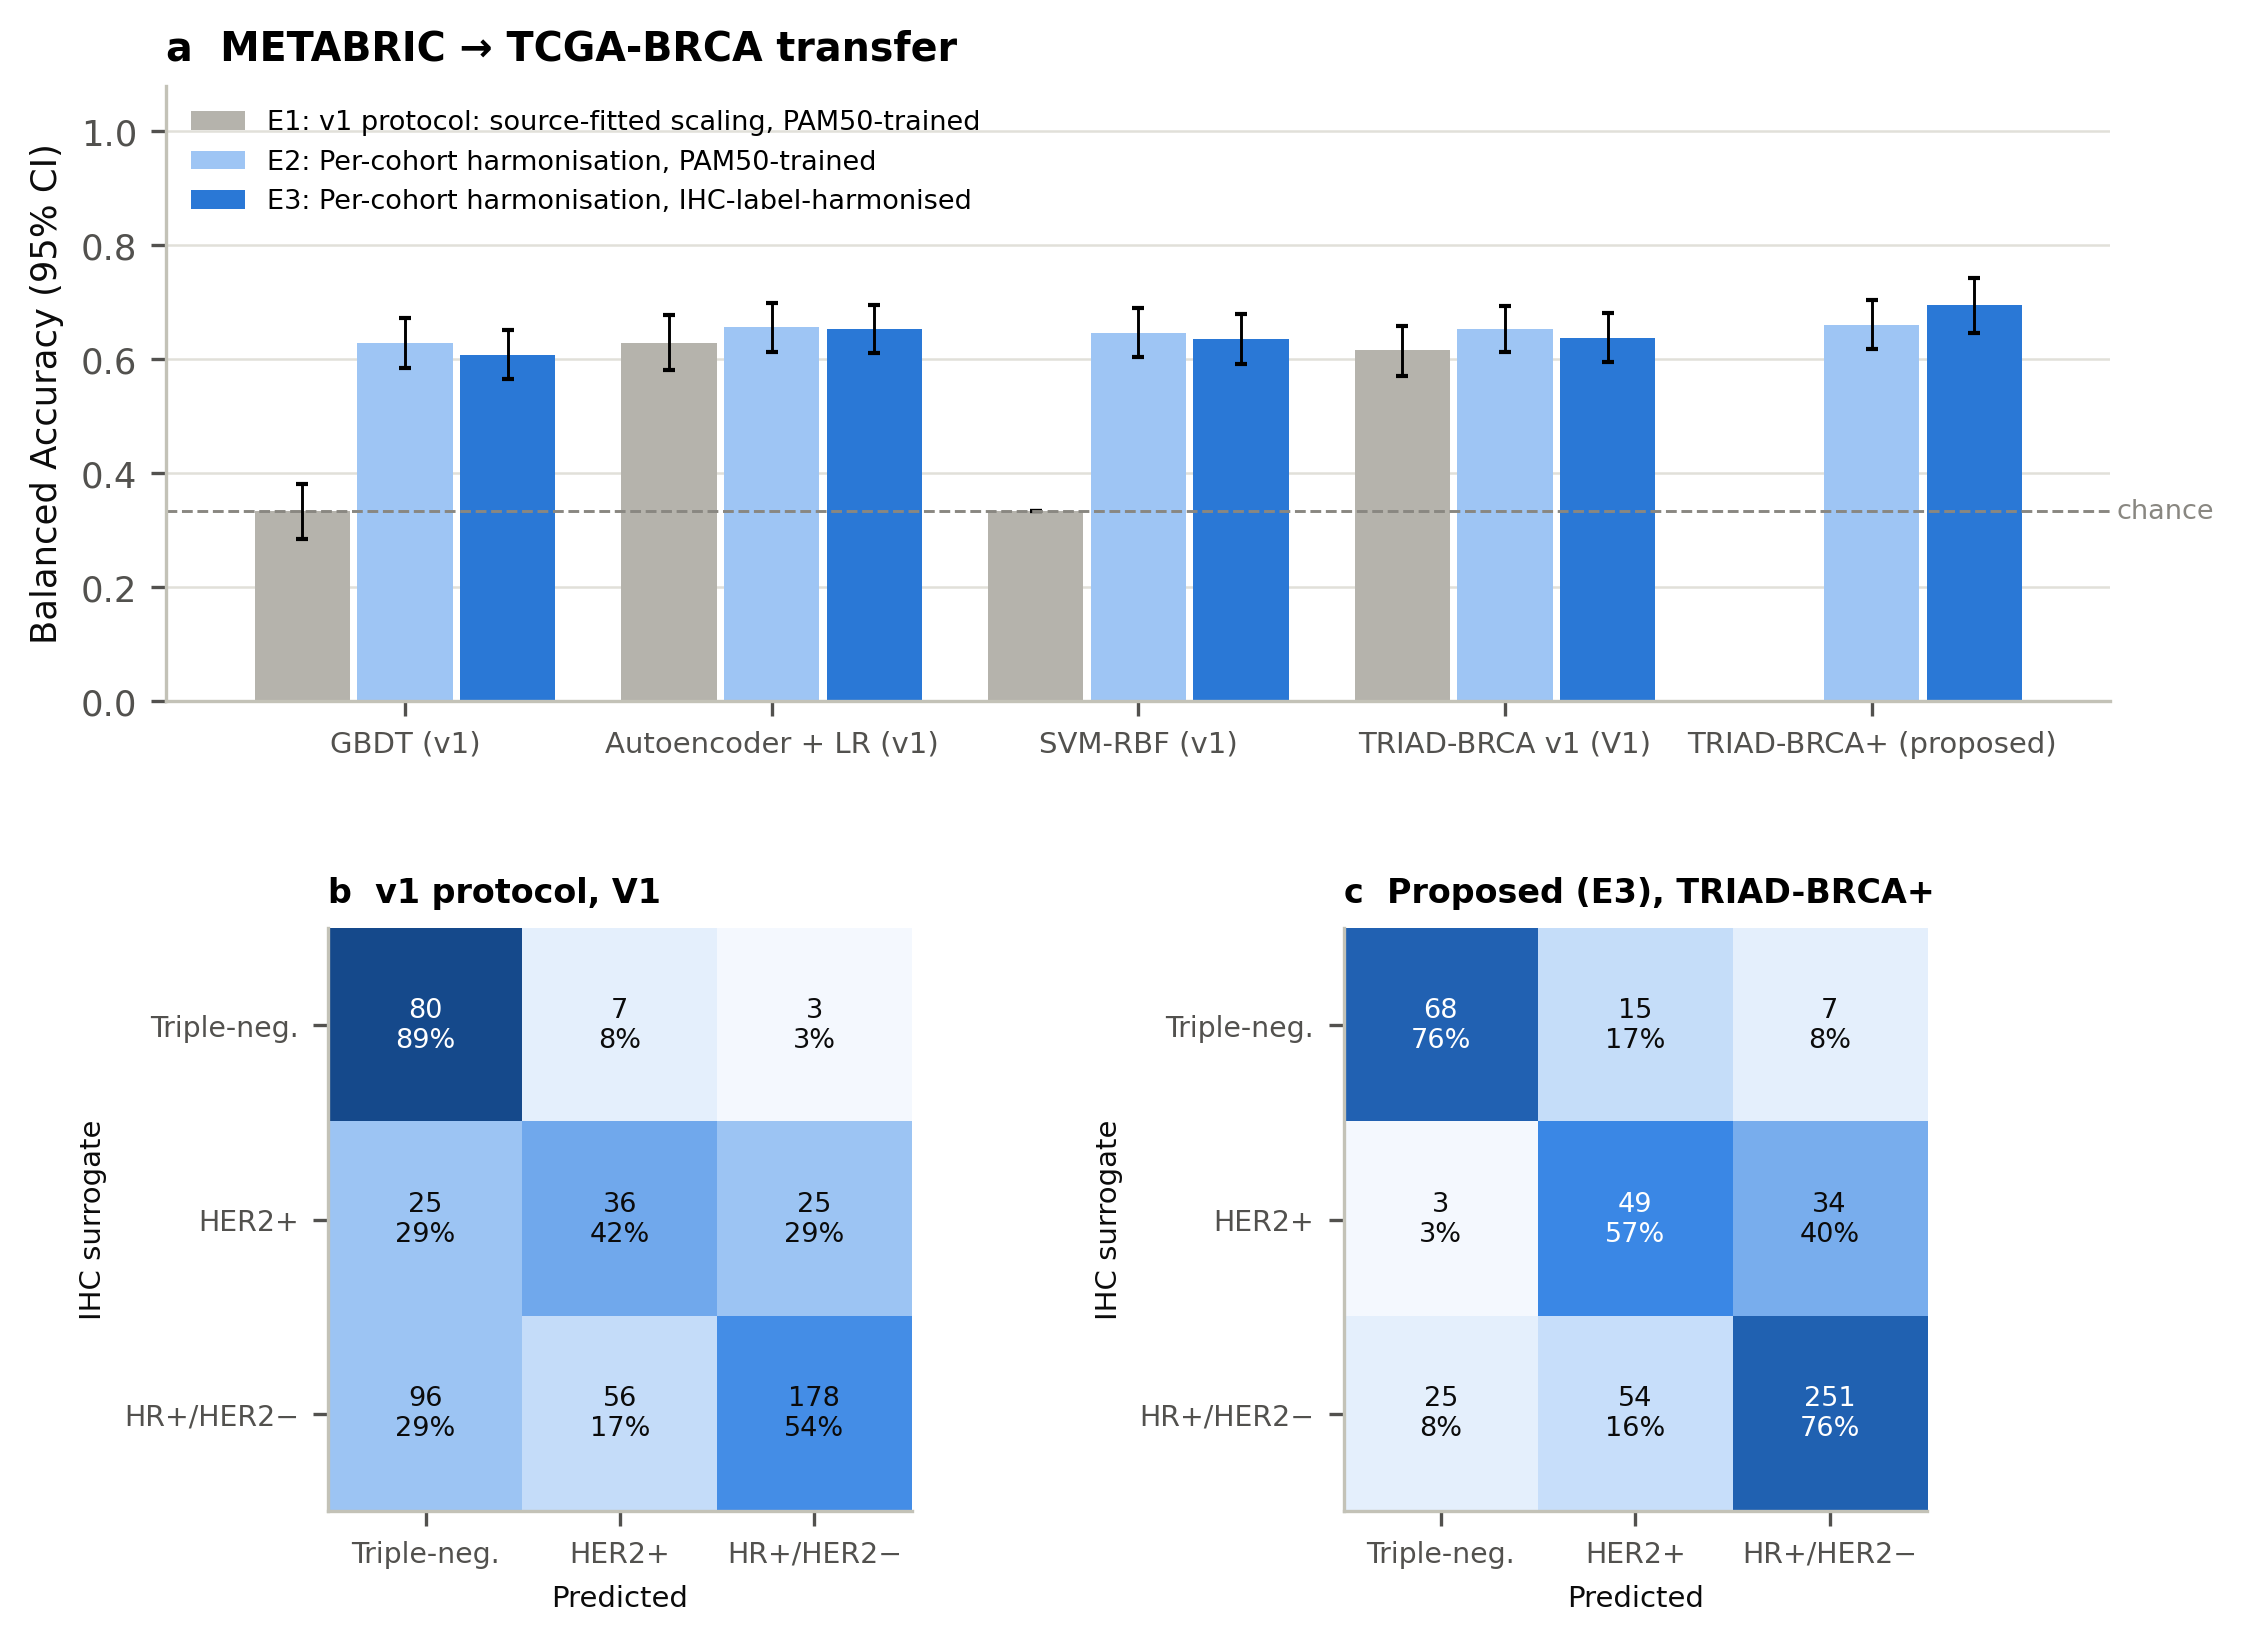

In [ ]:
for key in sorted(reporter.figcaps, key=_num):
    display(Markdown(f"**{key.replace('_', ' ', 1)}.** {reporter.figcaps[key]}"))
    path = os.path.join(OUT_DIR, "figures", f"{key}.png")
    display(IPImage(filename=path, width=900) if IPImage else path)

In [ ]:
zip_path = os.path.join(os.path.dirname(OUT_DIR), "TRIAD-BRCA-plus_results.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in ["tables", "figures"]:
        for f in sorted(glob.glob(os.path.join(OUT_DIR, folder, "*"))):
            zf.write(f, os.path.join("results", folder, os.path.basename(f)))
    for f in ["TRIAD-BRCA-plus_all_tables.xlsx", "captions.csv"]:
        zf.write(os.path.join(OUT_DIR, f), os.path.join("results", f))
print("written:", zip_path, f"({os.path.getsize(zip_path)/1e6:.1f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)

written: /content/TRIAD-BRCA-plus_results.zip (2.6 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>